# California Wildfire Risk: How It Works
**Angel Cruz · Research project**

What weather conditions accompanied historical California fires? This notebook joins the project's saved fire and weather records, calculates a transparent score, and visualizes the results.

**Start here:** Choose **Runtime → Run all** in Google Colab. No API key, Drive mount, GPU, or additional files are needed. To experiment, save your own copy and change the weather inputs below.

The analysis loads the saved dataset with pandas, checks for missing weather values, normalizes the measurements, and combines them into a weighted score. Charts show how those scores vary across the recorded fires. The saved snapshot makes the results reproducible without live API calls.

**Scope:** The score describes weather conditions associated with recorded fires. It is not a probability of ignition, an acreage forecast, or an emergency warning. The data contains fires, not a comparison group of places and days without fires.


## 1. Data sources and loading
The project uses a pandas DataFrame to store and process the fire and weather records. The CSV below is embedded directly from `data/processed/wildfire_weather_merged.csv`; it is a saved project snapshot, not a fresh API download. API failures remain visible as missing weather values.

The original pipeline is `calfire_api.py → weather_api.py → analysis.py → charts/maps`. CAL FIRE supplies event names, dates, acres, and centroid coordinates. Open-Meteo supplies historical reanalysis weather near those coordinates. The weather window runs from seven days before the alarm date **through the alarm date**, inclusive (eight calendar days). It therefore includes event-day weather and is not a strictly pre-ignition forecast.


In [1]:
from io import StringIO
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SNAPSHOT_CSV = 'fire_name,year,alarm_date,latitude,longitude,acres,weather_start,weather_end,max_temperature_f,min_relative_humidity_pct,total_precipitation_in,max_wind_speed_mph,mean_soil_moisture,weather_error\nGIFFORD,2025,2025-08-01,35.13103698717047,-120.1512187070564,131613.5,2025-07-25,2025-08-01,87.6,22.0,0.0,12.1,0.068,\nMADRE,2025,2025-07-02,35.116913071740925,-119.89333734235868,80779.1,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.11691&longitude=-119.89334&start_date=2025-06-25&end_date=2025-07-02&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGARNET,2025,2025-08-24,36.949439024741416,-119.08128286410009,60019.23,2025-08-17,2025-08-24,83.0,16.0,0.075,11.5,0.22725,\nSALT,2025,2025-09-02,35.99259690257236,-120.33830601008476,25553.55,2025-08-26,2025-09-02,98.9,9.0,0.004,12.4,0.143125,\nPALISADES,2025,2025-01-07,34.07264560529137,-118.5742117113887,23448.88,2024-12-31,2025-01-07,71.1,11.0,0.0,22.9,0.10325000000000001,\nBUTLER,2025,2025-07-04,41.277482071812315,-123.37479887396819,21057.61,2025-06-27,2025-07-04,99.4,19.0,0.024,8.3,0.13675,\nGREEN,2025,2025-07-02,40.83500646273047,-122.09865966992015,19021.99,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.83501&longitude=-122.09866&start_date=2025-06-25&end_date=2025-07-02&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nEATON,2025,2025-01-08,34.200787185240486,-118.09261031530156,14056.26,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.20079&longitude=-118.09261&start_date=2025-01-01&end_date=2025-01-08&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nDILLON,2025,2025-08-25,41.548474506520606,-123.56539365532925,11929.38,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.54847&longitude=-123.56539&start_date=2025-08-18&end_date=2025-08-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHUGHES,2025,2025-01-22,34.54216802269026,-118.58451526028216,10396.8,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.54217&longitude=-118.58452&start_date=2025-01-15&end_date=2025-01-22&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\n6-5,2025,2025-09-02,37.83896129605686,-120.42844981297188,6957.999,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.83896&longitude=-120.42845&start_date=2025-08-26&end_date=2025-09-02&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPICKETT,2025,2025-08-21,38.626242857464966,-122.5146065104517,6822.29,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.62624&longitude=-122.51461&start_date=2025-08-14&end_date=2025-08-21&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBORDER 2,2025,2025-01-23,32.615001313066394,-116.87664434410756,6629.878,2025-01-16,2025-01-23,73.0,3.0,0.0,12.4,0.057,\nCANYON,2025,2025-08-06,34.4668696513688,-118.70167541612423,5367.721,2025-07-30,2025-08-06,95.1,16.0,0.0,13.0,0.063,\n1-4,2025,2025-09-02,37.25326448218189,-120.05231084761633,4451.064,2025-08-26,2025-09-02,104.8,11.0,0.0,16.6,0.118625,\nDOGS,2025,2025-06-13,35.57099240301144,-118.98035099525549,4406.828,2025-06-06,2025-06-13,101.1,9.0,0.0,12.0,0.233625,\nJAW,2025,2025-05-19,35.31518946749164,-118.17914836614369,4326.964,2025-05-12,2025-05-19,76.7,13.0,0.004,31.3,0.04675,\nRANCH,2025,2025-06-10,34.393880511590595,-117.10429116171652,4291.886,2025-06-03,2025-06-10,95.1,9.0,0.106,14.1,0.050125,\nBLUE,2025,2025-08-27,41.79199581379583,-123.1866348839699,3712.53,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.792&longitude=-123.18663&start_date=2025-08-20&end_date=2025-08-27&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\n2-2,2025,2025-09-02,37.92313113512893,-120.78635177795051,3462.842,2025-08-26,2025-09-02,103.5,11.0,0.031,17.5,0.128625,\nMAMMOTH,2025,2025-07-25,41.71943844274133,-121.33456319647767,2534.267,2025-07-18,2025-07-25,91.8,10.0,0.35000000000000003,18.4,0.08374999999999999,\nLITTLE,2025,2025-08-22,35.58751125897348,-118.58291515015674,2506.547,2025-08-15,2025-08-22,95.2,14.0,0.0,8.6,0.0955,\nWOLF,2025,2025-06-29,33.88992458961521,-116.87727124709575,2413.62,2025-06-22,2025-06-29,91.6,10.0,0.0,13.2,0.038125000000000006,\nPACK,2025,2025-11-13,37.58163181010895,-118.78507659001983,1974.433,2025-11-06,2025-11-13,67.3,21.0,0.386,11.1,0.17124999999999999,\nSPRINGS,2025,2025-05-06,35.80245907129649,-118.94074278414755,1817.0,2025-04-29,2025-05-06,86.2,19.0,0.23299999999999998,9.8,0.180875,\nROSA,2025,2025-08-04,33.575992735090914,-116.50561275416949,1670.898,2025-07-28,2025-08-04,93.2,4.0,0.0,12.9,0.062,\nBITTER,2025,2025-06-14,35.53275100907996,-120.15584174517691,1663.73,2025-06-07,2025-06-14,94.3,8.0,0.0,14.3,0.185375,\nSILVER,2025,2025-03-30,37.41285145260809,-118.35774751075571,1605.057,2025-03-23,2025-03-30,74.1,3.0,0.0,10.0,0.023375,\n2-8,2025,2025-09-02,37.8859871184749,-120.63611613771164,1339.798,2025-08-26,2025-09-02,101.9,11.0,0.031,19.4,0.11,\nLOG,2025,2025-08-26,41.416914240273684,-123.27682626538422,1169.689,2025-08-19,2025-08-26,89.5,9.0,0.004,10.3,0.23225,\nMONTE,2025,2025-06-19,32.89996218429519,-116.82707048860918,1051.101,2025-06-12,2025-06-19,95.0,14.0,0.0,10.9,0.06125,\nDALE,2025,2025-07-16,33.51527292484627,-116.74897787067668,1038.642,2025-07-09,2025-07-16,97.7,6.0,0.0,13.0,0.073,\nGOLD,2025,2025-08-04,34.32857761652664,-116.88848084408876,1036.112,2025-07-28,2025-08-04,81.5,3.0,0.0,9.5,0.088375,\n6-2,2025,2025-09-02,37.776418643048196,-120.38010835740187,1024.863,2025-08-26,2025-09-02,101.3,12.0,0.028,20.3,0.11349999999999999,\nKENNETH,2025,2025-01-09,34.17520263700154,-118.68442775626993,1011.711,2025-01-02,2025-01-09,75.1,6.0,0.0,21.7,0.07925,\nMOUNTAIN,2025,2025-08-11,41.76238093888189,-121.34510494954257,979.9208,2025-08-04,2025-08-11,95.5,8.0,0.0,15.0,0.055375,\nBIG CLIFF,2025,2025-07-31,41.299378171443834,-123.00323957150108,973.5111,2025-07-24,2025-07-31,79.9,20.0,1.008,8.2,0.2995,\nDEMOCRAT,2025,2025-05-18,35.47328053187052,-118.69392328670307,902.7862,2025-05-11,2025-05-18,81.6,15.0,0.035,19.9,0.133625,\nDIAS,2025,2025-06-25,36.05329429229755,-120.40025603346392,852.0876,2025-06-18,2025-06-25,101.2,6.0,0.0,16.4,0.180375,\nHURST,2025,2025-01-07,34.33274904916097,-118.47982762663078,831.3855,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.33275&longitude=-118.47983&start_date=2024-12-31&end_date=2025-01-07&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nROOT,2025,2025-09-01,41.173734406694514,-122.39749786812843,728.6754,2025-08-25,2025-09-01,83.5,14.0,0.567,10.2,0.33062499999999995,\nINN,2025,2025-05-22,38.010822421690044,-119.15577476506257,726.5966,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.01082&longitude=-119.15577&start_date=2025-05-15&end_date=2025-05-22&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSUMMIT,2025,2025-07-01,41.520396477707166,-123.13591167722954,701.2705,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.5204&longitude=-123.13591&start_date=2025-06-24&end_date=2025-07-01&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nFAY,2025,2025-07-15,35.740832525659656,-118.29383269245602,648.1592,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.74083&longitude=-118.29383&start_date=2025-07-08&end_date=2025-07-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nACRES,2025,2025-05-14,37.0837609502511,-120.0058104097608,631.9116,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.08376&longitude=-120.00581&start_date=2025-05-07&end_date=2025-05-14&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCOYOTE,2025,2025-08-20,38.53243055700774,-120.62490018287957,623.9064,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.53243&longitude=-120.6249&start_date=2025-08-13&end_date=2025-08-20&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\n2-7,2025,2025-09-02,38.10550892643926,-120.48113208823023,615.7525,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.10551&longitude=-120.48113&start_date=2025-08-26&end_date=2025-09-02&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHUDSON,2025,2025-06-13,34.96367123048475,-119.40440447762617,610.8146,2025-06-06,2025-06-13,92.5,9.0,0.0,9.8,0.106,\nLITTLE,2025,2025-06-11,36.626944983515514,-120.89302737482386,592.3416,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.62694&longitude=-120.89303&start_date=2025-06-04&end_date=2025-06-11&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nKING,2025,2025-08-14,34.71242019993581,-118.79125761707839,577.1489,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.71242&longitude=-118.79126&start_date=2025-08-07&end_date=2025-08-14&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nJUNIPER,2025,2025-06-30,33.792845349340546,-117.31382344392615,560.1605,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.79285&longitude=-117.31382&start_date=2025-06-23&end_date=2025-06-30&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPEAK,2025,2025-08-25,40.90724297234738,-122.85361812387924,505.3025,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.90724&longitude=-122.85362&start_date=2025-08-18&end_date=2025-08-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLAKE,2025,2025-06-28,34.29483749128198,-117.34439369222693,488.7244,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.29484&longitude=-117.34439&start_date=2025-06-21&end_date=2025-06-28&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHAWK,2025,2025-08-14,34.541927910874506,-118.2218793980464,480.2473,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.54193&longitude=-118.22188&start_date=2025-08-07&end_date=2025-08-14&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nFIRESTONE,2025,2025-06-12,36.09079984613266,-120.46021796588734,472.0678,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.0908&longitude=-120.46022&start_date=2025-06-05&end_date=2025-06-12&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\n18-1,2025,2025-09-02,37.207103719781095,-120.09437728933874,463.0268,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.2071&longitude=-120.09438&start_date=2025-08-26&end_date=2025-09-02&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nNELLA,2025,2025-05-17,37.04557566269165,-120.96420823196905,458.0139,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.04558&longitude=-120.96421&start_date=2025-05-10&end_date=2025-05-17&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHORSE,2025,2025-07-02,40.87606929766594,-122.55048809809017,430.1073,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.87607&longitude=-122.55049&start_date=2025-06-25&end_date=2025-07-02&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPANOCHE,2025,2025-08-07,36.63165125341923,-120.98929001267008,422.5481,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.63165&longitude=-120.98929&start_date=2025-07-31&end_date=2025-08-07&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRUN,2025,2025-05-26,37.173887824162264,-119.96926631703424,420.0106,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.17389&longitude=-119.96927&start_date=2025-05-19&end_date=2025-05-26&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBRIDGE,2025,2025-07-07,40.16654092471631,-123.5956474170982,419.0038,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.16654&longitude=-123.59565&start_date=2025-06-30&end_date=2025-07-07&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMAX,2025,2025-07-13,36.97014222743919,-119.22027263566511,410.0221,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.97014&longitude=-119.22027&start_date=2025-07-06&end_date=2025-07-13&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLAKE,2025,2025-08-27,41.86504262560991,-121.22175141961769,398.1307,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.86504&longitude=-121.22175&start_date=2025-08-20&end_date=2025-08-27&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLAKE,2025,2025-08-03,38.978163780268765,-122.64214130151943,397.7174,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.97816&longitude=-122.64214&start_date=2025-07-27&end_date=2025-08-03&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nFORT,2025,2025-06-05,34.89915032167227,-118.9266157636292,389.011,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.89915&longitude=-118.92662&start_date=2025-05-29&end_date=2025-06-05&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCAMINO,2025,2025-06-20,37.75889136264029,-120.45404575199315,385.9513,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.75889&longitude=-120.45405&start_date=2025-06-13&end_date=2025-06-20&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nTWISSELMAN,2025,2025-06-24,35.725388975333715,-119.70258828456852,383.8156,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.72539&longitude=-119.70259&start_date=2025-06-17&end_date=2025-06-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGIANELLI,2025,2025-11-02,38.18457052851437,-119.90807967146523,373.5635,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.18457&longitude=-119.90808&start_date=2025-10-26&end_date=2025-11-02&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSOMERSVILLE,2025,2025-06-18,37.97443991942818,-121.84933357309521,358.065,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.97444&longitude=-121.84933&start_date=2025-06-11&end_date=2025-06-18&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLIDIA,2025,2025-01-08,34.43483759010238,-118.24682919466399,347.7042,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.43484&longitude=-118.24683&start_date=2025-01-01&end_date=2025-01-08&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nREEF,2025,2025-04-26,35.81364638137007,-120.01461800398728,336.357,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.81365&longitude=-120.01462&start_date=2025-04-19&end_date=2025-04-26&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nALPAUGH,2025,2025-08-14,35.85014740045836,-119.56697697986314,325.8804,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.85015&longitude=-119.56698&start_date=2025-08-07&end_date=2025-08-14&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nIDRIA,2025,2025-05-17,36.542170202493516,-120.83933199940556,310.3296,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.54217&longitude=-120.83933&start_date=2025-05-10&end_date=2025-05-17&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBUMMER,2025,2025-10-29,38.30513470984781,-120.02803633230212,294.2364,2025-10-22,2025-10-29,70.9,18.0,0.32600000000000007,10.5,0.41737500000000005,\n2-3,2025,2025-09-02,37.948740706231035,-120.59151639122653,285.2508,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.94874&longitude=-120.59152&start_date=2025-08-26&end_date=2025-09-02&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLOST HILLS,2025,2025-08-23,35.66079006250917,-119.66268504009467,277.9433,2025-08-16,2025-08-23,109.9,9.0,0.0,16.6,0.0595,\nDINO,2025,2025-06-11,37.07312178917828,-121.20378569136841,266.039,2025-06-04,2025-06-11,87.4,23.0,0.0,19.6,0.104375,\nMEDICINE,2025,2025-07-27,39.83342872139836,-123.26641636903118,262.8339,2025-07-20,2025-07-27,94.8,21.0,0.02,11.2,0.111,\nMIDWAY,2025,2025-05-22,37.72196191143776,-121.55019633726434,261.463,2025-05-15,2025-05-22,91.0,14.0,0.0,21.8,0.113625,\n1-4 PEAK,2025,2025-07-31,40.44379099466894,-120.65634063088952,259.6483,2025-07-24,2025-07-31,88.9,15.0,0.37,14.7,0.15337499999999998,\nHENDERSON,2025,2025-05-31,33.38439380600813,-117.05782999180605,255.4313,2025-05-24,2025-05-31,92.0,24.0,0.0,12.8,0.063625,\nSAGE,2025,2025-10-27,37.80929076189651,-118.80772988170234,254.1042,2025-10-20,2025-10-27,57.6,18.0,0.094,16.4,0.438,\nHEATHER,2025,2025-08-14,41.93263503359876,-122.40408289728295,228.574,2025-08-07,2025-08-14,103.9,8.0,0.0,12.8,0.058249999999999996,\nEUREKA,2025,2025-05-30,34.06516883570939,-116.32794009374449,213.8287,2025-05-23,2025-05-30,84.3,8.0,0.0,19.9,0.01575,\nBONEYARD 2,2025,2025-07-26,37.77223427483439,-120.20710718725827,202.3712,2025-07-19,2025-07-26,88.3,12.0,0.0,10.4,0.105,\nBONANZA,2025,2025-06-17,38.65616049601536,-120.88248784360978,181.2267,2025-06-10,2025-06-17,90.1,13.0,0.0,8.6,0.130125,\nCATLETT,2025,2025-05-10,38.85557053631609,-121.3957403315931,176.425,2025-05-03,2025-05-10,96.2,11.0,0.0,26.1,0.102875,\nGRANITE,2025,2025-06-24,35.51847180349581,-119.01392757772163,174.4417,2025-06-17,2025-06-24,101.9,9.0,0.0,18.0,0.23025,\nHORNITOS 1-2,2025,2025-09-02,37.53324559199314,-120.26552629084775,166.9535,2025-08-26,2025-09-02,101.5,12.0,0.004,18.1,0.13275,\nBROWN,2025,2025-09-02,38.45830387568009,-121.03817261037379,166.7195,2025-08-26,2025-09-02,103.1,10.0,0.032,14.3,0.12487500000000001,\nWILDWOOD,2025,2025-08-09,35.736778845178215,-119.46093677035896,158.709,2025-08-02,2025-08-09,106.9,11.0,0.0,12.2,0.10575,\nRICHBAR,2025,2025-08-09,35.470824374783916,-118.72270809655768,158.3233,2025-08-02,2025-08-09,100.5,9.0,0.0,11.0,0.097,\nRANCHO,2025,2025-06-19,40.410573645315026,-122.3177447628295,156.8465,2025-06-12,2025-06-19,102.7,7.0,0.0,15.4,0.113,\n65,2025,2025-05-27,35.45179057320763,-119.06228024484989,151.1339,2025-05-20,2025-05-27,94.1,9.0,0.0,9.4,0.11375,\n1-3,2025,2025-09-02,37.265894768395114,-120.00942932090676,150.8438,2025-08-26,2025-09-02,104.8,11.0,0.0,16.6,0.118625,\nROCK,2025,2025-09-02,38.58823292193436,-121.07154814667852,146.8478,2025-08-26,2025-09-02,103.7,10.0,0.02,15.2,0.132375,\nCALLBOX,2025,2025-01-05,34.574887862718,-118.56338118316101,145.0597,2024-12-29,2025-01-05,67.6,16.0,0.0,14.5,0.078375,\nR-3 WILLOW,2025,2025-08-24,40.44716817476898,-120.48384818535169,144.4809,2025-08-17,2025-08-24,96.4,10.0,0.04,13.8,0.05125,\nWEST,2025,2025-06-07,35.57322701547842,-119.63604107496563,142.0538,2025-05-31,2025-06-07,108.1,11.0,0.0,16.7,0.078,\nBOGGS,2025,2025-09-10,39.96050098703731,-122.3916137830091,135.0296,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.9605&longitude=-122.39161&start_date=2025-09-03&end_date=2025-09-10&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCAHUILLA,2025,2025-06-10,33.525777358444415,-116.7348862411325,133.8233,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.52578&longitude=-116.73489&start_date=2025-06-03&end_date=2025-06-10&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSADDLE,2025,2025-06-26,36.39891140203172,-118.94254701169348,131.8539,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.39891&longitude=-118.94255&start_date=2025-06-19&end_date=2025-06-26&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLIERLY,2025,2025-08-23,34.993569214108,-119.04490120950804,131.3383,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.99357&longitude=-119.0449&start_date=2025-08-16&end_date=2025-08-23&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCLAYPIT,2025,2025-08-04,38.410255580271084,-121.02155725286475,131.1089,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.41026&longitude=-121.02156&start_date=2025-07-28&end_date=2025-08-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRANCH,2025,2025-08-04,38.844152922874166,-121.29553524246764,125.0502,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.84415&longitude=-121.29554&start_date=2025-07-28&end_date=2025-08-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nTIGER,2025,2025-08-08,38.43528299949712,-120.51480119237604,117.527,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.43528&longitude=-120.5148&start_date=2025-08-01&end_date=2025-08-08&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRED,2025,2025-07-07,41.49594685491402,-123.76645702026303,115.8292,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.49595&longitude=-123.76646&start_date=2025-06-30&end_date=2025-07-07&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHELENA,2025,2025-07-03,40.79436547304795,-123.13695840241482,114.1198,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.79437&longitude=-123.13696&start_date=2025-06-26&end_date=2025-07-03&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCROSSING,2025,2025-05-20,33.46630344570905,-116.82327871973173,112.0008,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.4663&longitude=-116.82328&start_date=2025-05-13&end_date=2025-05-20&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nFRAZIER,2025,2025-05-29,34.820084308133616,-118.90456391707887,109.9302,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.82008&longitude=-118.90456&start_date=2025-05-22&end_date=2025-05-29&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRANCHO 3,2025,2025-10-09,33.07696160854034,-116.76336386939408,104.9052,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.07696&longitude=-116.76336&start_date=2025-10-02&end_date=2025-10-09&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBYERS,2025,2025-06-04,40.33320681741583,-120.47069698558832,104.5473,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.33321&longitude=-120.4707&start_date=2025-05-28&end_date=2025-06-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHOWARDS,2025,2025-07-31,41.479835903188395,-120.94166327227573,100.6936,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.47984&longitude=-120.94166&start_date=2025-07-24&end_date=2025-07-31&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nTABLE ROCK,2025,2025-06-10,41.70484087603146,-122.31215150680302,98.71336,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.70484&longitude=-122.31215&start_date=2025-06-03&end_date=2025-06-10&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPYRITE,2025,2025-07-07,34.02722311499233,-117.4431849840487,98.19131,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.02722&longitude=-117.44318&start_date=2025-06-30&end_date=2025-07-07&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nR-10 SPANISH,2025,2025-08-25,40.75180019658087,-120.2692190956009,97.00241,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.7518&longitude=-120.26922&start_date=2025-08-18&end_date=2025-08-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCEDAR,2025,2025-09-02,40.40748851202349,-123.2319163540792,91.45392,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.40749&longitude=-123.23192&start_date=2025-08-26&end_date=2025-09-02&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nABERDEEN,2025,2025-08-25,36.95256891546247,-118.32688956136298,90.84187,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.95257&longitude=-118.32689&start_date=2025-08-18&end_date=2025-08-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRUNNER,2025,2025-08-08,32.68898032663209,-116.28012016136695,88.39762,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.68898&longitude=-116.28012&start_date=2025-08-01&end_date=2025-08-08&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPONDEROSA,2025,2025-08-10,39.38649222054629,-121.2934059076952,87.2483,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.38649&longitude=-121.29341&start_date=2025-08-03&end_date=2025-08-10&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nYORK,2025,2025-08-24,41.844641684458686,-122.40401626878088,86.16303,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.84464&longitude=-122.40402&start_date=2025-08-17&end_date=2025-08-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLILAC 2,2025,2025-01-21,33.30616630220511,-117.15512547129161,80.53833,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.30617&longitude=-117.15513&start_date=2025-01-14&end_date=2025-01-21&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nFORD,2025,2025-06-03,36.751086502418374,-119.37779774791704,80.3026,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.75109&longitude=-119.3778&start_date=2025-05-27&end_date=2025-06-03&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGROVE,2025,2025-07-04,39.37509209472901,-121.4133540316691,78.17875,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.37509&longitude=-121.41335&start_date=2025-06-27&end_date=2025-07-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLODGE,2025,2025-09-05,32.72494765562212,-116.95659879027518,77.02348,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.72495&longitude=-116.9566&start_date=2025-08-29&end_date=2025-09-05&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBROWN,2025,2025-07-27,35.56740793137077,-119.88383601073785,76.71473,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.56741&longitude=-119.88384&start_date=2025-07-20&end_date=2025-07-27&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nELECTRICAL ,2025,2025-05-03,35.61173641500195,-119.85240521850292,75.40412,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.61174&longitude=-119.85241&start_date=2025-04-26&end_date=2025-05-03&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMINDY,2025,2025-06-29,33.556648585221566,-116.85384920393,72.54568,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.55665&longitude=-116.85385&start_date=2025-06-22&end_date=2025-06-29&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPOND,2025,2025-06-13,35.72295551260421,-119.37064909992854,71.13763,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.72296&longitude=-119.37065&start_date=2025-06-06&end_date=2025-06-13&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHONOLULU,2025,2025-06-01,35.14614620049376,-119.37624529959045,69.44583,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.14615&longitude=-119.37625&start_date=2025-05-25&end_date=2025-06-01&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nDUCK,2025,2025-05-14,37.91916177447245,-120.93423956495249,68.18237,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.91916&longitude=-120.93424&start_date=2025-05-07&end_date=2025-05-14&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSCISSORS 2,2025,2025-11-02,33.09969136366184,-116.48339633094959,68.07378,2025-10-26,2025-11-02,84.3,10.0,0.0,14.7,0.024625,\nPIONEER,2025,2025-05-04,40.239423107577835,-122.41251700198725,68.01633,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.23942&longitude=-122.41252&start_date=2025-04-27&end_date=2025-05-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBERRY,2025,2025-08-08,38.6973502127824,-122.27319269892438,67.19569,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.69735&longitude=-122.27319&start_date=2025-08-01&end_date=2025-08-08&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLAGUNA,2025,2025-01-23,34.162309153306005,-119.0576631802497,66.50694,2025-01-16,2025-01-23,78.3,4.0,0.0,25.2,0.038,\nBLACK ROCK,2025,2025-10-12,34.06289637778315,-116.393157904988,66.43217,2025-10-05,2025-10-12,78.5,13.0,0.441,15.4,0.020375,\nCREEK,2025,2025-05-15,37.534926013174044,-121.26769754661096,66.24147,2025-05-08,2025-05-15,93.0,10.0,0.008,13.7,0.112125,\nTAFT,2025,2025-10-07,35.2627060688121,-119.00988253096443,66.06812,2025-09-30,2025-10-07,90.1,19.0,0.221,11.2,0.196625,\nPASKENTA,2025,2025-08-25,40.0019175367036,-122.36492377308389,65.22432,2025-08-18,2025-08-25,108.0,7.0,0.0,15.8,0.123125,\nBEALVILLE,2025,2025-05-31,35.282424844154555,-118.64561716658113,62.99349,2025-05-24,2025-05-31,101.2,11.0,0.0,8.2,0.12325,\nAUTO,2025,2025-01-13,34.236405022614306,-119.20584282761257,60.93997,2025-01-06,2025-01-13,75.9,7.0,0.0,24.6,0.082375,\nRECTOR,2025,2025-06-02,36.76652247403258,-119.23180680062853,60.63538,2025-05-26,2025-06-02,95.6,21.0,0.0,9.7,0.14987499999999998,\nBORDER 18,2025,2025-11-08,32.59417670851692,-116.76100398378316,60.55587,2025-11-01,2025-11-08,88.0,15.0,0.0,10.6,0.1205,\nWOODY,2025,2025-07-25,35.614069741912424,-118.94610348139985,60.52179,2025-07-18,2025-07-25,98.3,13.0,0.0,11.7,0.186875,\nFELIPE,2025,2025-05-01,33.11184304605693,-116.45260421934039,59.91574,2025-04-24,2025-05-01,79.3,11.0,0.063,18.8,0.06575,\nWIND,2025,2025-08-12,35.10972120983068,-118.30999061000823,59.40875,2025-08-05,2025-08-12,95.5,8.0,0.0,17.2,0.035875000000000004,\nMARIA,2025,2025-06-16,34.339841603602245,-119.06533699982243,58.63367,2025-06-09,2025-06-16,88.1,35.0,0.0,8.1,0.116375,\nBAXTER,2025,2025-05-15,33.613495374500054,-117.14772701790483,58.50809,2025-05-08,2025-05-15,102.4,10.0,0.0,16.2,0.106,\nFLUME,2025,2025-07-06,36.16396174343486,-118.71244385893053,58.28129,2025-06-29,2025-07-06,90.4,13.0,0.0,8.1,0.118625,\nSUNSET,2025,2025-05-18,38.825922128915316,-121.36521405603449,57.56446,2025-05-11,2025-05-18,88.8,12.0,0.268,16.1,0.114125,\nBEALE AFB GRASS VALLEY GATE,2025,2025-05-23,39.11617339782451,-121.33917619223782,56.78709,2025-05-16,2025-05-23,92.1,9.0,0.0,17.3,0.138625,\nJUNIPER,2025,2025-05-28,41.58958463282523,-122.34720880341625,56.71992,2025-05-21,2025-05-28,90.1,11.0,0.0,17.4,0.010624999999999999,\nCRUMP,2025,2025-09-06,33.71352915200458,-117.31353679307774,55.24618,2025-08-30,2025-09-06,105.7,12.0,0.0,10.7,0.05975,\nVAIL,2025,2025-08-23,33.49878770410096,-116.99848670522873,54.9739,2025-08-16,2025-08-23,97.9,17.0,0.0,12.9,0.07275,\nRED,2025,2025-06-26,37.08590156779818,-119.69486239425036,54.064,2025-06-19,2025-06-26,96.5,9.0,0.0,19.1,0.124375,\nJURY,2025,2025-07-19,37.91691971247236,-120.35614282664774,53.71318,2025-07-12,2025-07-19,96.9,14.0,0.0,8.6,0.14125,\nDEBBIE,2025,2025-07-16,40.0935823770051,-120.09802163321255,53.37561,2025-07-09,2025-07-16,102.7,6.0,0.0,14.2,0.034,\nELWOOD,2025,2025-07-03,36.81468147651286,-119.37862072875349,52.9217,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.81468&longitude=-119.37862&start_date=2025-06-26&end_date=2025-07-03&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSHADY,2025,2025-07-25,33.653425544576905,-116.17655584645495,52.4022,2025-07-18,2025-07-25,106.7,5.0,0.0,12.4,0.041124999999999995,\nJACK,2025,2025-06-06,35.70817702753196,-120.15514113205086,51.1434,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.70818&longitude=-120.15514&start_date=2025-05-30&end_date=2025-06-06&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLASSEN,2025,2025-08-01,39.91712274259579,-121.9207608470327,50.84476,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.91712&longitude=-121.92076&start_date=2025-07-25&end_date=2025-08-01&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCLARK,2025,2025-08-10,40.91797160122734,-121.17035426506658,50.71144,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.91797&longitude=-121.17035&start_date=2025-08-03&end_date=2025-08-10&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nWALNUT,2025,2025-05-18,37.87377066028051,-121.70153632581328,50.69104,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.87377&longitude=-121.70154&start_date=2025-05-11&end_date=2025-05-18&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHAWICK,2025,2025-06-19,32.83068777268716,-116.88243794341814,50.6212,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.83069&longitude=-116.88244&start_date=2025-06-12&end_date=2025-06-19&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRIDER,2025,2025-06-18,33.824313294493855,-117.25897581797345,49.86058,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.82431&longitude=-117.25898&start_date=2025-06-11&end_date=2025-06-18&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSPRINGS 3,2025,2025-07-11,32.71490742349117,-116.74555656194877,49.86013,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.71491&longitude=-116.74556&start_date=2025-07-04&end_date=2025-07-11&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nACADEMY,2025,2025-05-16,33.08565638312631,-116.94198085828371,49.72696,2025-05-09,2025-05-16,98.7,13.0,0.055,12.8,0.12637500000000002,\nSANDY,2025,2025-04-24,37.18769799433911,-120.52657547396758,48.48575,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.1877&longitude=-120.52658&start_date=2025-04-17&end_date=2025-04-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nTOMBSTONE,2025,2025-08-30,36.90230940959398,-118.81792950810683,48.27648,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.90231&longitude=-118.81793&start_date=2025-08-23&end_date=2025-08-30&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\n3-5 LITTLE,2025,2025-07-25,40.9776957220823,-121.27362059166673,48.16375,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.9777&longitude=-121.27362&start_date=2025-07-18&end_date=2025-07-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBUTTER,2025,2025-08-26,35.46551342244352,-118.14751043759583,47.95021,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.46551&longitude=-118.14751&start_date=2025-08-19&end_date=2025-08-26&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nNICHOLS,2025,2025-07-07,33.72081286740888,-117.35975738161632,47.49926,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.72081&longitude=-117.35976&start_date=2025-06-30&end_date=2025-07-07&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nAURORA,2025,2025-07-19,34.637945724750416,-117.11882453384374,47.04757,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.63795&longitude=-117.11882&start_date=2025-07-12&end_date=2025-07-19&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGRIZZLY,2025,2025-06-23,37.78191328723559,-120.26384554115337,46.79976,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.78191&longitude=-120.26385&start_date=2025-06-16&end_date=2025-06-23&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nWASHINGTON,2025,2025-06-23,37.27801125861954,-120.73874268762283,46.71652,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.27801&longitude=-120.73874&start_date=2025-06-16&end_date=2025-06-23&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nJACKET,2025,2025-07-03,41.30183940392596,-123.29738195714286,46.07977,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.30184&longitude=-123.29738&start_date=2025-06-26&end_date=2025-07-03&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nOAK,2025,2025-08-02,33.99915184715433,-117.15017556652157,45.90355,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.99915&longitude=-117.15018&start_date=2025-07-26&end_date=2025-08-02&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nFOOTHILL,2025,2025-09-02,34.90343671032311,-119.59172477047508,45.61524,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.90344&longitude=-119.59172&start_date=2025-08-26&end_date=2025-09-02&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nS-14,2025,2025-09-01,41.2306432459096,-120.07570589078378,44.3112,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.23064&longitude=-120.07571&start_date=2025-08-25&end_date=2025-09-01&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGENERAL,2025,2025-07-14,35.28039425471502,-118.71587103257684,44.18845,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.28039&longitude=-118.71587&start_date=2025-07-07&end_date=2025-07-14&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHOWE,2025,2025-06-16,34.388144633243606,-118.7866973336794,43.79828,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.38814&longitude=-118.7867&start_date=2025-06-09&end_date=2025-06-16&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nANCHOR,2025,2025-05-09,36.69568870550807,-119.31441096931631,43.42168,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.69569&longitude=-119.31441&start_date=2025-05-02&end_date=2025-05-09&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMILPAS,2025,2025-05-24,34.408978905777545,-117.09167635497171,43.19293,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.40898&longitude=-117.09168&start_date=2025-05-17&end_date=2025-05-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPOINT,2025,2025-08-23,40.391523465829906,-122.40910770353287,42.89072,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.39152&longitude=-122.40911&start_date=2025-08-16&end_date=2025-08-23&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nENERGY,2025,2025-05-12,35.35354581709642,-120.03320024991828,42.8705,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.35355&longitude=-120.0332&start_date=2025-05-05&end_date=2025-05-12&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nAIRLINE,2025,2025-06-12,36.33936276869754,-120.9426618940177,42.72174,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.33936&longitude=-120.94266&start_date=2025-06-05&end_date=2025-06-12&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCARLOS,2025,2025-08-18,35.44814434571706,-120.66764685837592,42.71249,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.44814&longitude=-120.66765&start_date=2025-08-11&end_date=2025-08-18&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nKECKS ,2025,2025-07-25,35.699113757574125,-120.00749523579536,42.70273,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.69911&longitude=-120.0075&start_date=2025-07-18&end_date=2025-07-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nDISTRICT,2025,2025-07-04,39.44829016517669,-121.48308853729593,41.83611,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.44829&longitude=-121.48309&start_date=2025-06-27&end_date=2025-07-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nDUNES,2025,2025-04-18,41.80593355654173,-124.23397218679516,41.41012,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.80593&longitude=-124.23397&start_date=2025-04-11&end_date=2025-04-18&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBUTTE,2025,2025-08-07,41.97389274541093,-121.1445268148838,40.64384,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.97389&longitude=-121.14453&start_date=2025-07-31&end_date=2025-08-07&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\n1-2,2025,2025-09-02,38.15659417201772,-120.71708760921436,40.37952,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.15659&longitude=-120.71709&start_date=2025-08-26&end_date=2025-09-02&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\n3-22 MUCK,2025,2025-08-25,40.98342634649458,-121.21726848124227,39.81916,2025-08-18,2025-08-25,96.4,10.0,0.079,13.2,0.18425,\nPEARL,2025,2025-07-25,35.6212792989812,-118.48693539557057,39.71396,2025-07-18,2025-07-25,96.9,14.0,0.0,11.4,0.0775,\nTANABE,2025,2025-08-23,39.263678133582296,-121.50496087681996,39.56842,2025-08-16,2025-08-23,105.5,12.0,0.0,13.0,0.103125,\nREADING,2025,2025-06-08,40.64233225784509,-122.94146407724377,39.37916,2025-06-01,2025-06-08,101.4,6.0,0.0,11.9,0.2235,\nROSAMOND,2025,2025-07-30,34.88016282600757,-118.39096346414995,38.63425,2025-07-23,2025-07-30,95.2,11.0,0.0,17.6,0.04975,\nTRAP,2025,2025-07-20,37.51539578251477,-120.01039774651781,38.32053,2025-07-13,2025-07-20,96.3,12.0,0.0,9.0,0.11,\nDRY,2025,2025-06-25,37.72205206373954,-118.96701071300161,37.35918,2025-06-18,2025-06-25,81.9,10.0,0.044,18.7,0.20787499999999998,\nJOAQUIN,2025,2025-09-25,36.32264584659226,-120.50970831765419,36.99887,2025-09-18,2025-09-25,84.8,17.0,0.716,9.2,0.1385,\nLICK,2025,2025-08-29,41.03691908385606,-122.76301941498262,36.69459,2025-08-22,2025-08-29,86.5,9.0,0.33399999999999996,8.8,0.3045,\nHIGH,2025,2025-08-25,36.95157571880695,-119.34806436341212,35.69007,2025-08-18,2025-08-25,101.5,13.0,0.0,11.8,0.127125,\nBREEZE,2025,2025-08-25,37.955449149221934,-119.65761758849257,34.43386,2025-08-18,2025-08-25,78.6,15.0,0.47300000000000003,9.9,0.22,\nRAVINE,2025,2025-07-03,39.064677868067434,-121.26714216890565,34.37255,2025-06-26,2025-07-03,99.2,15.0,0.0,15.4,0.12875,\nMICHIGAN,2025,2025-09-02,38.37771542181633,-121.01702403759832,33.97209,2025-08-26,2025-09-02,103.8,9.0,0.031,13.4,0.13025,\nFOREBAY,2025,2025-09-02,39.52798720992559,-121.6316348819284,33.85615,2025-08-26,2025-09-02,104.1,9.0,0.0,12.5,0.124875,\nSPRINGS,2025,2025-09-01,40.401124300316425,-121.81438602102087,33.48352,2025-08-25,2025-09-01,94.0,10.0,0.024,14.5,0.068875,\nPANAMA,2025,2025-08-22,35.271466969475874,-118.70527485742714,32.75241,2025-08-15,2025-08-22,103.3,13.0,0.0,8.9,0.100875,\nSPRINGS,2025,2025-09-05,34.354379872548144,-117.1846126926695,32.74208,2025-08-29,2025-09-05,92.6,12.0,0.087,14.6,0.05575,\nMORNING,2025,2025-05-18,35.409712482052775,-118.90917426031608,32.22947,2025-05-11,2025-05-18,91.7,13.0,0.0,15.5,0.17049999999999998,\nNINETY NINE,2025,2025-05-09,39.577174356709506,-121.68675145050062,32.16321,2025-05-02,2025-05-09,88.9,17.0,0.134,22.3,0.158125,\nVLECK,2025,2025-09-29,38.48163271429546,-121.06556616850915,32.07587,2025-09-22,2025-09-29,97.2,15.0,0.012,12.4,0.134625,\nBAXTER,2025,2025-06-03,37.07097010718383,-118.31262984742251,31.69332,2025-05-27,2025-06-03,90.1,8.0,0.07400000000000001,11.3,0.051875000000000004,\n5-4,2025,2025-08-27,40.782360032704055,-122.63452236254395,31.44775,2025-08-20,2025-08-27,96.2,7.0,0.008,9.7,0.262875,\nSTONEWALL,2025,2025-08-31,36.4681562351187,-121.22320613194785,31.06484,2025-08-24,2025-08-31,98.1,12.0,0.0,15.0,0.058374999999999996,\nLAKE,2025,2025-06-10,35.10976495157347,-119.30287107576602,30.47568,2025-06-03,2025-06-10,103.2,15.0,0.0,10.4,0.098125,\nOLIVAS,2025,2025-01-08,34.23666278768508,-119.24473229520882,30.10198,2025-01-01,2025-01-08,74.4,8.0,0.0,21.7,0.09525,\nPANOCHE,2025,2025-04-20,36.638596803989145,-120.88698013275844,29.94425,2025-04-13,2025-04-20,85.2,15.0,0.0,14.5,0.122375,\nHIDDEN,2025,2025-06-10,40.48863704087996,-123.432392704585,29.67354,2025-06-03,2025-06-10,97.4,14.0,0.044,11.2,0.2345,\nWILLOW,2025,2025-06-11,41.79132671013076,-120.2113608962234,29.48021,2025-06-04,2025-06-11,81.7,16.0,0.30700000000000005,12.5,0.174875,\nSPRINGS,2025,2025-10-08,35.34326095592161,-118.3526262885706,29.3266,2025-10-01,2025-10-08,81.1,12.0,0.142,13.9,0.141625,\nKRN-25-25974,2025,2025-06-01,35.585502935119194,-119.71286104462875,28.55898,2025-05-25,2025-06-01,107.4,11.0,0.0,18.4,0.083875,\nSTEELE 2,2025,2025-07-09,32.7322215392586,-116.91677187208815,28.41091,2025-07-02,2025-07-09,89.6,28.0,0.0,9.4,0.04875,\nCORN,2025,2025-05-18,36.66374514159011,-119.14556281726597,27.93816,2025-05-11,2025-05-18,81.2,21.0,0.244,12.2,0.16125,\nTORO,2025,2025-05-14,33.764267001487106,-117.33203253702555,27.76788,2025-05-07,2025-05-14,98.7,7.0,0.016,13.2,0.13137500000000002,\nLOKERN ,2025,2025-06-21,35.406593125429076,-119.72275180761933,27.76694,2025-06-14,2025-06-21,103.0,7.0,0.0,15.0,0.1385,\nRANCHO,2025,2025-07-05,35.535290687546826,-120.6200481000835,27.51352,2025-06-28,2025-07-05,87.0,20.0,0.0,16.1,0.131,\nPASS,2025,2025-09-17,36.20060779851933,-118.18490715360534,27.19731,2025-09-10,2025-09-17,72.0,15.0,0.059,11.9,0.1905,\nPANOCHE,2025,2025-05-18,36.64607918919671,-120.6395366828989,27.18991,2025-05-11,2025-05-18,88.7,11.0,0.0,16.6,0.145625,\nARDEN,2025,2025-08-09,39.10184819632526,-122.80344244500738,26.04275,2025-08-02,2025-08-09,99.7,13.0,0.0,13.6,0.087625,\nCLARK,2025,2025-06-20,39.62013526668703,-121.6542135764722,25.7984,2025-06-13,2025-06-20,101.8,12.0,0.0,20.5,0.12975,\nQUARRY,2025,2025-07-01,38.29032064765196,-121.07242757804386,25.76958,2025-06-24,2025-07-01,99.8,15.0,0.0,12.5,0.11875,\nCOULTER,2025,2025-07-19,38.54705076513582,-121.00161506651311,25.7527,2025-07-12,2025-07-19,99.2,16.0,0.0,10.8,0.093,\nCOTTONWOOD,2025,2025-09-05,34.303713340977325,-118.68549749062102,25.53726,2025-08-29,2025-09-05,96.7,15.0,0.0,10.1,0.06525,\nPOND,2025,2025-08-06,39.7329390807344,-123.50954790219888,25.1699,2025-07-30,2025-08-06,87.3,26.0,0.0,10.6,0.13575,\nDAN,2025,2025-05-22,37.236090746241814,-120.73815249973559,24.44448,2025-05-15,2025-05-22,93.8,11.0,0.0,16.9,0.098875,\nPERCH,2025,2025-06-30,41.917912564673216,-122.4285037842082,24.43616,2025-06-23,2025-06-30,101.2,10.0,0.008,15.0,0.052875,\nRICA,2025,2025-06-13,39.27951517216674,-121.48106090255932,24.32036,2025-06-06,2025-06-13,96.5,18.0,0.0,16.2,0.107625,\nSANDIA 2,2025,2025-10-07,33.447094176440075,-117.26280404731261,23.9757,2025-09-30,2025-10-07,80.8,42.0,0.008,10.0,0.0695,\nPARKVILLE,2025,2025-08-27,40.43104682362975,-122.19042234273809,23.89887,2025-08-20,2025-08-27,106.9,7.0,0.0,18.3,0.125,\nKETTLE,2025,2025-08-31,36.939805193973974,-118.76794876367899,23.83323,2025-08-24,2025-08-31,71.0,12.0,0.263,8.5,0.24275,\nSCHOOL,2025,2025-10-07,37.31963142190906,-122.36478381133807,23.33731,2025-09-30,2025-10-07,75.4,44.0,0.7989999999999999,12.1,0.260375,\nFISH,2025,2025-07-07,36.81743695159986,-119.43179408397681,23.25034,2025-06-30,2025-07-07,100.6,11.0,0.0,15.5,0.128125,\nMARIPOSA,2025,2025-06-17,34.471156042047625,-120.19065756390711,23.18431,2025-06-10,2025-06-17,92.6,20.0,0.0,15.5,0.13075,\nLANGLEY,2025,2025-05-25,35.37440506632445,-119.09727366722086,22.86259,2025-05-18,2025-05-25,94.2,9.0,0.0,11.8,0.076375,\nMORNING,2025,2025-05-09,35.392226346094176,-118.90387421560459,22.77419,2025-05-02,2025-05-09,96.8,14.0,0.13,10.0,0.196875,\nUPHILL,2025,2025-09-22,38.821457272429925,-120.99291862230828,22.22845,2025-09-15,2025-09-22,93.7,15.0,0.374,10.7,0.17325000000000002,\nHART,2025,2025-07-04,35.74137976227304,-119.05447782102016,21.59082,2025-06-27,2025-07-04,103.6,9.0,0.0,16.4,0.17925,\nFOBES,2025,2025-07-15,33.63991110576804,-116.63087575704493,21.49974,2025-07-08,2025-07-15,94.6,5.0,0.0,14.2,0.075,\nCANAL,2025,2025-10-23,35.20616362011991,-118.76812643502114,21.39122,2025-10-16,2025-10-23,82.3,23.0,0.008,7.5,0.19924999999999998,\nMISSION 2,2025,2025-06-16,33.302512924093854,-117.22408463695187,21.38923,2025-06-09,2025-06-16,92.3,25.0,0.016,9.9,0.14950000000000002,\nCOYOTE,2025,2025-05-31,40.40808854786868,-120.52792792614672,21.24901,2025-05-24,2025-05-31,95.7,7.0,0.0,14.4,0.010374999999999999,\nIGNACIO,2025,2025-07-05,33.54012785630377,-116.9011467198996,21.24298,2025-06-28,2025-07-05,96.1,10.0,0.0,11.7,0.064125,\nGRANITE,2025,2025-09-02,39.893862947205506,-121.45200404017217,20.90041,2025-08-26,2025-09-02,88.4,15.0,0.091,10.3,0.21050000000000002,\nCACTUS,2025,2025-07-05,33.90727416823828,-117.30277700259988,20.83071,2025-06-28,2025-07-05,96.3,8.0,0.0,11.9,0.078,\nACAMPO,2025,2025-05-15,38.167641145029755,-121.03678192700352,20.81965,2025-05-08,2025-05-15,90.9,16.0,0.012,14.5,0.13425,\n4-1 WASHINGTON,2025,2025-07-24,41.45884544110827,-120.92692968643962,20.47464,2025-07-17,2025-07-24,89.7,10.0,0.237,20.0,0.0905,\nW-2 FITZHUGH,2025,2025-07-25,41.36640799261666,-120.42775172297323,20.42416,2025-07-18,2025-07-25,87.7,11.0,0.299,15.1,0.145625,\nPILITAS,2025,2025-06-20,35.35066476856271,-120.4932723003078,20.20947,2025-06-13,2025-06-20,97.5,12.0,0.0,13.0,0.083,\nRUTH,2025,2025-06-20,36.724957942883016,-119.1480917678795,20.08119,2025-06-13,2025-06-20,92.7,9.0,0.0,11.9,0.13737500000000002,\nGRANGE,2025,2025-05-18,37.669226439550684,-120.43941734595523,19.91957,2025-05-11,2025-05-18,82.5,15.0,0.032,15.7,0.14,\nMARYSVILLE,2025,2025-06-29,39.38339158385007,-121.15084787434218,19.86819,2025-06-22,2025-06-29,91.8,14.0,0.0,10.4,0.22612500000000002,\nPASO,2025,2025-06-13,35.0269589114769,-118.74382006330063,19.70666,2025-06-06,2025-06-13,100.0,9.0,0.0,9.0,0.13225,\nCOTTONWOOD,2025,2025-06-02,41.92001531164194,-122.58318209883082,19.58972,2025-05-26,2025-06-02,96.5,12.0,0.0,14.8,0.04375,\nUNION,2025,2025-10-06,35.18516287269469,-119.00491040495382,19.31531,2025-09-29,2025-10-06,87.3,23.0,0.103,13.1,0.11875000000000001,\nPOSTA,2025,2025-07-24,32.678513136629114,-116.43654044505921,19.0752,2025-07-17,2025-07-24,84.7,12.0,0.028,12.8,0.07949999999999999,\nMADERA,2025,2025-07-10,33.49970652368074,-117.01104371292357,19.07495,2025-07-03,2025-07-10,97.5,16.0,0.0,12.4,0.087375,\nRIFLE,2025,2025-05-24,36.93911177542755,-119.68168719417262,19.03836,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nHEAVEN,2025,2025-06-15,41.82893164008416,-122.65329516178164,19.02455,2025-06-08,2025-06-15,102.1,11.0,0.08700000000000001,16.3,0.16925,\nQUINN,2025,2025-07-02,35.73055780186,-119.08169352320706,18.98449,2025-06-25,2025-07-02,102.6,9.0,0.0,10.7,0.180375,\nRADAR,2025,2025-08-02,41.72152095337488,-121.13347110310845,18.91577,2025-07-26,2025-08-02,87.6,11.0,0.122,18.5,0.0615,\nMONTANA,2025,2025-06-24,41.63096999068838,-122.36455848116894,18.77196,2025-06-17,2025-06-24,88.1,11.0,0.138,18.5,0.04525,\nKIBBIE,2025,2025-08-26,38.02913108103703,-119.82461013993887,18.68576,2025-08-19,2025-08-26,80.1,14.0,0.851,12.9,0.13425,\nFLEMING,2025,2025-06-25,34.024024691523124,-117.47246324578896,18.61419,2025-06-18,2025-06-25,97.6,18.0,0.0,11.3,0.0935,\nVAN CLIEF RD STEVENSON,2025,2025-07-06,37.283505187939966,-120.82856630477815,18.27019,2025-06-29,2025-07-06,103.9,11.0,0.0,16.3,0.109625,\nRUSH,2025,2025-06-20,40.711315614343505,-122.81047302400927,18.25358,2025-06-13,2025-06-20,91.1,9.0,0.008,16.5,0.13737500000000002,\nRECHE,2025,2025-07-10,33.95848113533223,-117.19240743692119,18.2381,2025-07-03,2025-07-10,100.6,6.0,0.0,12.1,0.0835,\nANTONIO,2025,2025-06-09,37.33436066965786,-121.49903004758741,18.231,2025-06-02,2025-06-09,87.8,14.0,0.0,11.6,0.112125,\nDEER,2025,2025-06-20,35.22233625206303,-118.71136217045064,18.10975,2025-06-13,2025-06-20,99.4,8.0,0.0,11.5,0.128,\nCLEMENT,2025,2025-06-13,40.48193659338376,-122.4508954002026,18.05686,2025-06-06,2025-06-13,105.2,11.0,0.0,15.0,0.0455,\nGYLE,2025,2025-10-27,39.99620625808415,-122.27431252126223,18.05467,2025-10-20,2025-10-27,81.9,11.0,1.48,23.3,0.19375,\nMOORE,2025,2025-07-10,38.87280998863288,-121.3260795523941,17.88558,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.87281&longitude=-121.32608&start_date=2025-07-03&end_date=2025-07-10&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHOSKING 3,2025,2025-07-21,35.28287307196888,-119.02372918333843,17.70028,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.28287&longitude=-119.02373&start_date=2025-07-14&end_date=2025-07-21&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBOYD,2025,2025-04-17,32.89716907078434,-115.29219681686526,17.30158,2025-04-10,2025-04-17,102.4,3.0,0.0,25.4,0.012750000000000001,\nGARDEN,2025,2025-08-26,41.31560717090588,-123.23315973566847,17.24211,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.31561&longitude=-123.23316&start_date=2025-08-19&end_date=2025-08-26&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nVALLEY,2025,2025-09-01,38.72505200661098,-121.03087922294804,17.20355,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.72505&longitude=-121.03088&start_date=2025-08-25&end_date=2025-09-01&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nOAK,2025,2025-06-15,37.025517492398365,-119.51661654356127,17.03071,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.02552&longitude=-119.51662&start_date=2025-06-08&end_date=2025-06-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBORDER,2025,2025-01-01,32.59744200265702,-116.83012052258958,16.9115,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.59744&longitude=-116.83012&start_date=2024-12-25&end_date=2025-01-01&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSABE,2025,2025-06-05,36.81838822309589,-121.18056156318572,16.89966,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.81839&longitude=-121.18056&start_date=2025-05-29&end_date=2025-06-05&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nELM,2025,2025-06-16,36.28243007315243,-121.27725028703274,16.846,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.28243&longitude=-121.27725&start_date=2025-06-09&end_date=2025-06-16&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCROSS,2025,2025-02-09,35.95251448258401,-121.13107586464763,16.71458,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.95251&longitude=-121.13108&start_date=2025-02-02&end_date=2025-02-09&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBAKER,2025,2025-07-16,40.30622369740449,-122.57974608038398,16.5998,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.30622&longitude=-122.57975&start_date=2025-07-09&end_date=2025-07-16&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHANSEN,2025,2025-05-13,37.701849362734905,-121.51272847459468,16.33476,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.70185&longitude=-121.51273&start_date=2025-05-06&end_date=2025-05-13&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCRATER,2025,2025-08-27,41.75090226992825,-121.55563832286548,16.1303,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.7509&longitude=-121.55564&start_date=2025-08-20&end_date=2025-08-27&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nALTA,2025,2025-07-20,39.4234370194075,-121.46825113450605,16.11074,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.42344&longitude=-121.46825&start_date=2025-07-13&end_date=2025-07-20&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nQUAIL,2025,2025-06-04,40.53983814154645,-122.27069883591867,16.0962,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.53984&longitude=-122.2707&start_date=2025-05-28&end_date=2025-06-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLITTLE,2025,2025-07-17,41.11783958692888,-120.96380381721166,15.89377,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.11784&longitude=-120.9638&start_date=2025-07-10&end_date=2025-07-17&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBIRD,2025,2025-10-04,35.65117033977681,-118.84262417540573,15.8049,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.65117&longitude=-118.84262&start_date=2025-09-27&end_date=2025-10-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBAND,2025,2025-06-18,37.645184591907196,-120.33477582562777,15.50475,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.64518&longitude=-120.33478&start_date=2025-06-11&end_date=2025-06-18&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPEREZ,2025,2025-08-12,41.71397405694461,-121.28425864607877,15.31279,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.71397&longitude=-121.28426&start_date=2025-08-05&end_date=2025-08-12&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGUN CUB ,2025,2025-06-23,35.69760994272975,-119.51150144674628,15.31198,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.69761&longitude=-119.5115&start_date=2025-06-16&end_date=2025-06-23&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCEMETARY,2025,2025-07-05,35.38554655579134,-118.8978356957937,15.24142,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.38555&longitude=-118.89784&start_date=2025-06-28&end_date=2025-07-05&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRESERVOIR,2025,2025-07-01,41.71765257746024,-120.69511458683314,15.21916,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.71765&longitude=-120.69511&start_date=2025-06-24&end_date=2025-07-01&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCORNING,2025,2025-07-07,39.928349806853134,-122.29899117641311,15.20529,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.92835&longitude=-122.29899&start_date=2025-06-30&end_date=2025-07-07&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\n309,2025,2025-08-19,35.916318998698344,-119.34116741886332,15.04406,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.91632&longitude=-119.34117&start_date=2025-08-12&end_date=2025-08-19&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGIBBEL,2025,2025-01-23,33.70979138026601,-116.9627589516062,15.00072,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.70979&longitude=-116.96276&start_date=2025-01-16&end_date=2025-01-23&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLA PORTE,2025,2025-04-24,39.517797109864574,-121.19866077435823,14.96098,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.5178&longitude=-121.19866&start_date=2025-04-17&end_date=2025-04-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPARK,2025,2025-09-02,35.94963131820551,-120.35317131196385,14.95,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.94963&longitude=-120.35317&start_date=2025-08-26&end_date=2025-09-02&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSLIGER,2025,2025-07-25,38.954876601755096,-120.93431005329106,14.87471,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.95488&longitude=-120.93431&start_date=2025-07-18&end_date=2025-07-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBEAVER,2025,2025-12-04,38.48346281513164,-120.35226136347957,14.75826,2025-11-27,2025-12-04,65.7,18.0,0.0,22.2,0.401625,\n84,2025,2025-05-10,35.9294435059661,-119.39505968558129,14.40466,2025-05-03,2025-05-10,102.2,10.0,0.122,17.5,0.09325,\nCRESTON,2025,2025-05-22,35.56641995761558,-120.56386133577594,14.21327,2025-05-15,2025-05-22,91.5,11.0,0.004,19.1,0.13375,\nCREEK,2025,2025-05-16,40.436865035930815,-121.9184357878202,14.11715,2025-05-09,2025-05-16,86.3,14.0,0.504,26.1,0.15912500000000002,\nWILDROSE,2025,2025-04-08,34.70019219314986,-117.17931688659453,14.09043,2025-04-01,2025-04-08,82.8,7.0,0.024,23.4,0.015375,\nHILLCREST,2025,2025-04-07,35.38091249764481,-118.8959954341332,13.96742,2025-03-31,2025-04-07,81.0,22.0,0.9490000000000001,13.7,0.298625,\nSPRINGS,2025,2025-06-27,41.56878094824566,-122.36367067657265,13.95434,2025-06-20,2025-06-27,88.9,10.0,0.047,14.9,0.025750000000000002,\nAQUADUCT,2025,2025-09-07,35.26815105528231,-118.09875327193625,13.78122,2025-08-31,2025-09-07,91.6,7.0,0.012,17.8,0.018125,\nALOMA ,2025,2025-04-22,35.61346134709992,-119.65392482397394,13.77262,2025-04-15,2025-04-22,88.4,12.0,0.0,15.4,0.107125,\nFARM,2025,2025-08-06,40.40781079402745,-122.52080245281397,13.72191,2025-07-30,2025-08-06,100.9,12.0,0.0,20.5,0.066625,\nCOACH,2025,2025-08-30,36.80640890446238,-121.54497033718862,13.57751,2025-08-23,2025-08-30,89.1,25.0,0.0,10.0,0.121125,\nFANDANGO,2025,2025-07-14,41.78866215401699,-120.175762301618,13.49481,2025-07-07,2025-07-14,93.0,13.0,0.0,10.0,0.11125000000000002,\nLOBINGER,2025,2025-06-11,39.947962282939905,-122.20994341336223,13.22655,2025-06-04,2025-06-11,100.2,9.0,0.0,18.1,0.1045,\nKRN-25-24931,2025,2025-05-25,35.7600030667576,-119.28128239275084,13.12227,2025-05-18,2025-05-25,91.2,17.0,0.0,10.8,0.1015,\nBUELL,2025,2025-09-10,40.46055738126619,-122.60734274814516,13.06349,2025-09-03,2025-09-10,98.6,13.0,0.5,13.8,0.23975000000000002,\nRUSH,2025,2025-08-02,37.78746860430609,-120.07409124025368,12.92799,2025-07-26,2025-08-02,87.5,18.0,0.0,9.2,0.13375,\nELK,2025,2025-09-17,35.30359230121505,-119.54396620662659,12.66308,2025-09-10,2025-09-17,98.2,15.0,0.0,10.6,0.103125,\nH-10,2025,2025-08-26,40.733699418968776,-121.35929935812099,12.6223,2025-08-19,2025-08-26,93.7,12.0,0.402,10.6,0.224875,\nSARGENT,2025,2025-05-20,35.95756638558335,-120.8514491565812,12.56901,2025-05-13,2025-05-20,90.8,12.0,0.0,20.4,0.12737500000000002,\nGRANDE,2025,2025-05-09,37.45720829671971,-121.19333011900193,12.46485,2025-05-02,2025-05-09,93.8,14.0,0.0,18.1,0.103375,\nLAKE,2025,2025-04-13,41.8844977584777,-124.20602891685893,12.4645,2025-04-06,2025-04-13,69.9,44.0,2.059,19.6,0.363375,\nFINK,2025,2025-06-05,37.39501270565829,-121.17661664548336,12.33877,2025-05-29,2025-06-05,106.1,9.0,0.0,12.9,0.120625,\nBEAR,2025,2025-06-02,35.32148448087469,-118.71189723327454,12.27456,2025-05-26,2025-06-02,103.4,10.0,0.0,12.6,0.22125,\nNICHOLS,2025,2025-10-07,39.108479034953746,-121.25318366796473,12.24453,2025-09-30,2025-10-07,84.0,23.0,1.3940000000000001,11.8,0.245375,\nTEMPLIN,2025,2025-01-01,34.60335159091766,-118.67130014907028,12.2261,2024-12-25,2025-01-01,71.9,22.0,0.0,21.9,0.07062500000000001,\nSTARDUST,2025,2025-07-12,38.88309353033721,-121.2481958443819,12.19767,2025-07-05,2025-07-12,104.2,12.0,0.0,11.1,0.107125,\nGUN,2025,2025-08-10,37.00594533305174,-119.6471319991421,12.06726,2025-08-03,2025-08-10,103.5,10.0,0.0,12.5,0.107,\nMURPHY,2025,2025-08-26,41.21246351461735,-123.16995368433145,11.90152,2025-08-19,2025-08-26,94.9,7.0,0.008,9.5,0.256625,\nMARIPOSA,2025,2025-08-09,34.328419908434796,-117.4766394943822,11.87765,2025-08-02,2025-08-09,95.5,10.0,0.0,12.2,0.101,\nLOOP,2025,2025-08-23,35.305422496933204,-119.70700574326608,11.73412,2025-08-16,2025-08-23,103.6,12.0,0.0,10.8,0.1425,\nGREILICH,2025,2025-06-10,38.456069519333816,-120.88500783098287,11.682,2025-06-03,2025-06-10,90.3,23.0,0.0,9.8,0.1265,\nBEAR,2025,2025-08-24,41.62459465566263,-122.74256245449567,11.63204,2025-08-17,2025-08-24,94.4,8.0,0.074,10.1,0.10200000000000001,\nHAROLD,2025,2025-10-12,34.3063312354001,-118.61561274944454,11.45487,2025-10-05,2025-10-12,87.7,12.0,0.0,11.3,0.07387500000000001,\n33,2025,2025-04-14,35.121379498974406,-119.43795550522526,11.44568,2025-04-07,2025-04-14,84.9,19.0,0.0,8.9,0.10187500000000001,\nUTAH,2025,2025-08-11,37.574295800473756,-120.12839016221116,11.39059,2025-08-04,2025-08-11,97.2,15.0,0.0,10.7,0.075625,\nBRADFORD BRANCH,2025,2025-07-16,33.50632225629656,-116.79410053553563,11.35215,2025-07-09,2025-07-16,99.0,8.0,0.0,9.9,0.083,\nHOVEY ,2025,2025-06-11,35.09954068363607,-119.47689331499195,11.16992,2025-06-04,2025-06-11,99.1,15.0,0.0,10.0,0.092375,\nWINDY,2025,2025-06-09,37.346849410306824,-119.33566925001651,11.13911,2025-06-02,2025-06-09,88.2,23.0,0.0,9.2,0.138125,\nASSIST/BDC/OASIS,2025,2025-06-19,34.61767725887526,-117.64759107813347,11.13588,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.61768&longitude=-117.64759&start_date=2025-06-12&end_date=2025-06-19&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLOCUST,2025,2025-06-29,35.61695743940209,-117.64038538385927,11.12911,2025-06-22,2025-06-29,100.6,4.0,0.0,15.4,0.014624999999999999,\nHERMOSA ,2025,2025-06-08,35.303425521119166,-118.80212077964075,10.96412,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.30343&longitude=-118.80212&start_date=2025-06-01&end_date=2025-06-08&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\n6-3,2025,2025-08-26,39.52774654605449,-121.64439579193571,10.90325,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nCYRUS,2025,2025-07-07,35.70268413826295,-118.41530793959451,10.84886,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.70268&longitude=-118.41531&start_date=2025-06-30&end_date=2025-07-07&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLOOK,2025,2025-08-24,36.532095531174825,-118.90423148056563,10.80006,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.5321&longitude=-118.90423&start_date=2025-08-17&end_date=2025-08-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGUN,2025,2025-05-25,36.62173900949839,-120.65826486939427,10.78514,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.62174&longitude=-120.65826&start_date=2025-05-18&end_date=2025-05-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nIVERSON,2025,2025-06-19,36.54859479844386,-121.39215670135229,10.73471,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.54859&longitude=-121.39216&start_date=2025-06-12&end_date=2025-06-19&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPLUTO,2025,2025-05-24,41.56925777377669,-122.28964905491391,10.65996,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.56926&longitude=-122.28965&start_date=2025-05-17&end_date=2025-05-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCLEAR,2025,2025-07-30,41.841587836661866,-120.73186626664085,10.63687,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.84159&longitude=-120.73187&start_date=2025-07-23&end_date=2025-07-30&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLETTER,2025,2025-06-09,39.881907896699126,-121.28585180719955,10.63072,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.88191&longitude=-121.28585&start_date=2025-06-02&end_date=2025-06-09&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nISLAND,2025,2025-07-12,36.859135893493495,-119.32900920905972,10.60109,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.85914&longitude=-119.32901&start_date=2025-07-05&end_date=2025-07-12&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGUNSMOKE,2025,2025-05-18,40.175661780467095,-122.57403834135027,10.56276,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.17566&longitude=-122.57404&start_date=2025-05-11&end_date=2025-05-18&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBEALE,2025,2025-07-12,35.26529236632219,-118.62078037258783,10.52162,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.26529&longitude=-118.62078&start_date=2025-07-05&end_date=2025-07-12&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGRUBS,2025,2025-05-30,39.43373823876574,-121.46040319961534,10.40143,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.43374&longitude=-121.4604&start_date=2025-05-23&end_date=2025-05-30&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHIGHLINE,2025,2025-11-09,32.90139473906841,-115.24240242636192,10.3387,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.90139&longitude=-115.2424&start_date=2025-11-02&end_date=2025-11-09&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nFUEL,2025,2025-09-01,37.045315244853406,-119.4710065873134,10.3191,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.04532&longitude=-119.47101&start_date=2025-08-25&end_date=2025-09-01&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSOUTHSIDE,2025,2025-05-24,36.775607079259096,-121.35413477782528,10.30094,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.77561&longitude=-121.35413&start_date=2025-05-17&end_date=2025-05-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nORANGE,2025,2025-09-02,39.96034016615209,-122.16374043650458,10.2738,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.96034&longitude=-122.16374&start_date=2025-08-26&end_date=2025-09-02&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMATTHEW,2025,2025-05-06,39.0652425743063,-121.27479719560446,10.27065,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.06524&longitude=-121.2748&start_date=2025-04-29&end_date=2025-05-06&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRAVEN,2025,2025-06-20,41.879552475404594,-122.43621574123543,10.20997,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.87955&longitude=-122.43622&start_date=2025-06-13&end_date=2025-06-20&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nVISTA,2025,2025-06-15,33.81798252521668,-116.86431072636391,10.12553,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.81798&longitude=-116.86431&start_date=2025-06-08&end_date=2025-06-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nFRANDY ,2025,2025-06-25,35.75198099348644,-118.4224398270453,9.48122,2025-06-18,2025-06-25,102.1,6.0,0.0,18.1,0.10275,\nHOSKING ,2025,2025-04-14,35.284008127846946,-119.02581303420901,9.46642,2025-04-07,2025-04-14,89.4,19.0,0.0,8.5,0.105,\nHILLS,2025,2025-04-13,35.61355328555394,-119.89358368600762,9.40661,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.61355&longitude=-119.89358&start_date=2025-04-06&end_date=2025-04-13&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSAGE,2025,2025-07-05,33.93262439082758,-117.1844641383483,9.097208,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.93262&longitude=-117.18446&start_date=2025-06-28&end_date=2025-07-05&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPARK,2025,2025-05-18,35.38440564881044,-118.91600615745548,9.069969,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.38441&longitude=-118.91601&start_date=2025-05-11&end_date=2025-05-18&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPENNY,2025,2025-02-26,32.91921366455525,-116.47347671809705,8.994162,2025-02-19,2025-02-26,71.7,8.0,0.0,10.4,0.1595,\nNOPAH,2025,2025-02-12,35.8848320290928,-116.2333752082025,8.961789,2025-02-05,2025-02-12,73.2,8.0,0.0,20.3,0.01075,\nCREST,2025,2025-07-21,37.436689682872455,-118.66674404046022,8.493313,2025-07-14,2025-07-21,82.4,9.0,0.028,10.8,0.060375,\nMOUNTAIN,2025,2025-07-18,35.26833618517767,-118.69248705759776,8.436714,2025-07-11,2025-07-18,102.5,9.0,0.0,9.2,0.12025,\nGREEN,2025,2025-07-05,33.72361652215543,-117.33526312210894,8.389605,2025-06-28,2025-07-05,100.9,10.0,0.0,8.2,0.0825,\nWILLOW,2025,2025-08-22,35.0371649128062,-118.35282767574164,8.38383,2025-08-15,2025-08-22,95.7,7.0,0.0,13.9,0.029375000000000002,\nWILLOW,2025,2025-09-16,41.8104677794205,-122.38813858233627,8.307479,2025-09-09,2025-09-16,88.2,12.0,0.303,13.5,0.15375,\nORCHARD ,2025,2025-09-24,35.34112327163925,-118.78188509651191,8.015344,2025-09-17,2025-09-24,96.0,16.0,0.74,10.1,0.284625,\nSAWYER,2025,2025-08-18,39.24334401064176,-123.12100964233194,7.678487,2025-08-11,2025-08-18,96.7,23.0,0.0,13.1,0.11925,\nMAXX,2025,2025-06-30,35.37338387647559,-118.93421573778994,7.677474,2025-06-23,2025-06-30,104.9,7.0,0.0,10.0,0.15587499999999999,\nMONICA,2025,2025-07-13,35.374384683764646,-118.90680003072593,7.405249,2025-07-06,2025-07-13,108.5,8.0,0.0,14.3,0.145625,\nGRADE,2025,2025-09-13,35.01665696628012,-119.4129572321818,7.178474,2025-09-06,2025-09-13,92.4,19.0,0.0,10.1,0.08574999999999999,\nSTAGECOACH,2025,2025-06-14,34.9368756156268,-118.25369250249135,7.157779,2025-06-07,2025-06-14,100.7,5.0,0.0,18.2,0.010124999999999999,\nBALDY 2,2025,2025-09-25,39.91682235414398,-123.31487745648077,7.043671,2025-09-18,2025-09-25,89.4,14.0,0.095,8.9,0.151,\nESTRELLA,2025,2025-10-12,35.65766840278335,-120.54295002873803,7.01524,2025-10-05,2025-10-12,86.8,20.0,0.0,14.2,0.151625,\nUPLAND,2025,2025-05-22,41.816234717360025,-122.50279217949934,7.006025,2025-05-15,2025-05-22,79.7,14.0,0.083,16.2,0.09775,\nYUCCA,2025,2025-05-25,34.49642833119062,-117.1169313239219,6.966782,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.49643&longitude=-117.11693&start_date=2025-05-18&end_date=2025-05-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nOIL,2025,2025-09-06,35.16758800369029,-119.44128882912833,6.735997,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.16759&longitude=-119.44129&start_date=2025-08-30&end_date=2025-09-06&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBUCKHORN,2025,2025-03-04,34.974821571418985,-119.68003202554777,6.627492,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.97482&longitude=-119.68003&start_date=2025-02-25&end_date=2025-03-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPINE,2025,2025-08-24,35.55322923400373,-118.80927795772534,6.428208,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.55323&longitude=-118.80928&start_date=2025-08-17&end_date=2025-08-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCOMANCHE ,2025,2025-05-27,35.37344417580797,-118.84023118144236,6.423163,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.37344&longitude=-118.84023&start_date=2025-05-20&end_date=2025-05-27&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nKAM,2025,2025-06-30,35.29203149984845,-118.90678151401062,6.418489,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.29203&longitude=-118.90678&start_date=2025-06-23&end_date=2025-06-30&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLERDO,2025,2025-11-13,35.51646125603676,-119.07437665163194,6.401134,2025-11-06,2025-11-13,80.1,31.0,0.0,19.0,0.152625,\nAPPLE,2025,2025-01-07,33.093033302485146,-116.63854108072897,6.372646,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.09303&longitude=-116.63854&start_date=2024-12-31&end_date=2025-01-07&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGRADE,2025,2025-06-05,36.52158658406983,-121.75638932306255,6.33567,2025-05-29,2025-06-05,82.7,42.0,0.0,9.3,0.153625,\nSHASTA,2025,2025-06-10,41.551129887056,-122.41871091311162,6.328118,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.55113&longitude=-122.41871&start_date=2025-06-03&end_date=2025-06-10&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nR-13 PETES,2025,2025-08-26,40.60943857697046,-120.4124228634435,6.27591,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.60944&longitude=-120.41242&start_date=2025-08-19&end_date=2025-08-26&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLONG VALLEY,2025,2025-08-26,37.722707669941904,-118.80362751598764,6.237775,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.72271&longitude=-118.80363&start_date=2025-08-19&end_date=2025-08-26&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nISABELLA,2025,2025-06-07,35.59407952326301,-118.49109016308265,5.934118,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.59408&longitude=-118.49109&start_date=2025-05-31&end_date=2025-06-07&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGRAPEVINE,2025,2025-05-12,34.923208687348165,-118.92614217561503,5.828817,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nHARRY,2025,2025-06-30,41.63008042912691,-122.34805018932376,5.772521,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.63008&longitude=-122.34805&start_date=2025-06-23&end_date=2025-06-30&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLAKE,2025,2025-08-20,35.42729987249257,-118.83388088900959,5.752456,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.4273&longitude=-118.83388&start_date=2025-08-13&end_date=2025-08-20&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSOLAR,2025,2025-05-19,40.37209775629408,-120.26130891864315,5.712334,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.3721&longitude=-120.26131&start_date=2025-05-12&end_date=2025-05-19&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPOWER,2025,2025-06-12,35.39575359169481,-118.92324156174664,5.657748,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.39575&longitude=-118.92324&start_date=2025-06-05&end_date=2025-06-12&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nWILLOW,2025,2025-05-10,41.18658896040741,-122.16882933227097,5.643619,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.18659&longitude=-122.16883&start_date=2025-05-03&end_date=2025-05-10&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBIKE,2025,2025-06-24,35.40168020384949,-119.01631039242726,5.643009,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.40168&longitude=-119.01631&start_date=2025-06-17&end_date=2025-06-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRIVER ,2025,2025-09-27,35.403999552780384,-119.01067180174034,5.607408,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.404&longitude=-119.01067&start_date=2025-09-20&end_date=2025-09-27&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nR-1 DANNER,2025,2025-06-09,40.37890797811022,-120.23780443516928,5.606033,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.37891&longitude=-120.2378&start_date=2025-06-02&end_date=2025-06-09&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nWASCO POND,2025,2025-05-05,35.78751334679988,-119.32439914704281,5.571162,2025-04-28,2025-05-05,90.3,19.0,0.012,14.2,0.11562499999999999,\nDITCH,2025,2025-05-17,35.04462984814171,-119.35514932063356,5.47024,2025-05-10,2025-05-17,97.8,14.0,0.0,16.6,0.1235,\nOILFIELD ,2025,2025-07-07,35.50595519263812,-119.03186209843331,5.455512,2025-06-30,2025-07-07,103.3,7.0,0.0,19.0,0.223875,\nSTORMY ,2025,2025-06-23,35.58135674025342,-119.04829305626834,5.389888,2025-06-16,2025-06-23,101.9,9.0,0.0,17.6,0.20025,\nPUMP ,2025,2025-09-02,35.02298979360412,-118.9939518159309,5.34671,2025-08-26,2025-09-02,109.0,10.0,0.0,16.7,0.06775,\nCOCHES 2,2025,2025-09-08,32.834522011073254,-116.90064691544009,5.299844,2025-09-01,2025-09-08,97.6,19.0,0.091,10.9,0.095125,\nLERDO ,2025,2025-04-18,35.51040328621655,-119.07273728538466,5.224772,2025-04-11,2025-04-18,87.1,21.0,0.08299999999999999,10.7,0.130875,\nSLOUGH,2025,2025-08-25,41.504838877861665,-122.42705616129095,4.96555,2025-08-18,2025-08-25,99.8,5.0,0.016,11.5,0.168125,\nMERCED,2025,2025-06-13,35.53271775321257,-119.09305168672824,4.836013,2025-06-06,2025-06-13,102.3,8.0,0.0,10.6,0.082,\nCYMRIC,2025,2025-05-13,35.38268064526776,-119.71043316258587,4.827553,2025-05-06,2025-05-13,99.7,10.0,0.0,16.3,0.16012500000000002,\nAFTON,2025,2025-04-26,35.037198471135426,-116.38885305907303,4.786592,2025-04-19,2025-04-26,88.7,5.0,0.0,24.3,0.020250000000000004,\nBRIDGE,2025,2025-05-13,34.98569725121216,-120.42880292117472,4.782364,2025-05-06,2025-05-13,86.1,34.0,0.012,14.5,0.12325,\nRANCHITA,2025,2025-07-18,35.73441543838743,-120.61433133292952,4.414623,2025-07-11,2025-07-18,97.2,17.0,0.0,12.4,0.13037500000000002,\nCLUB,2025,2025-08-23,33.615759194584825,-117.55148023944999,4.2,2025-08-16,2025-08-23,95.0,20.0,0.0,7.3,0.057874999999999996,\nCOW,2025,2025-04-09,39.102808579125295,-123.10506945598604,3.983708,2025-04-02,2025-04-09,69.6,29.0,0.378,11.9,0.34687500000000004,\nMIRANDA,2025,2025-04-21,35.06854968931786,-119.98683508812218,3.950654,2025-04-14,2025-04-21,81.2,18.0,0.0,11.7,0.2015,\nBALDY,2025,2025-09-24,39.91711512595494,-123.31295274838239,3.859035,2025-09-17,2025-09-24,89.4,14.0,0.095,8.9,0.15375,\nCUESTA,2025,2025-07-22,35.29490851060707,-120.62293739438385,3.708038,2025-07-15,2025-07-22,74.9,48.0,0.0,9.7,0.113625,\nBEAN,2025,2025-09-03,39.63977396752385,-121.30643910894189,3.706272,2025-08-27,2025-09-03,95.8,10.0,0.0,14.2,0.194625,\nRIDGE,2025,2025-05-06,39.38460895076227,-123.24618786091361,3.599587,2025-04-29,2025-05-06,80.1,11.0,0.319,11.1,0.2015,\nCOTTON,2025,2025-05-25,35.609608860913205,-118.23854058195847,3.553523,2025-05-18,2025-05-25,87.4,12.0,0.0,14.3,0.065,\nCHESTER,2025,2025-07-25,35.46817991476248,-119.02614556638086,3.531665,2025-07-18,2025-07-25,102.7,12.0,0.0,12.6,0.07325,\nBELLA,2025,2025-06-09,35.65113468650653,-118.32042202153882,3.531122,2025-06-02,2025-06-09,99.1,10.0,0.0,12.4,0.106125,\nSALINAS,2025,2025-06-12,35.615962933658594,-120.68413343696334,3.421595,2025-06-05,2025-06-12,92.3,11.0,0.0,14.3,0.123625,\nAIRPORT,2025,2025-07-10,35.14670681736979,-119.44296714477005,3.415518,2025-07-03,2025-07-10,104.2,8.0,0.0,16.9,0.10037499999999999,\nANGLER,2025,2025-05-27,35.599300332389944,-118.48564522961459,3.393137,2025-05-20,2025-05-27,91.6,8.0,0.0,12.0,0.0965,\nR-12 RAMHORN,2025,2025-08-25,40.70901168401688,-120.27359671565912,3.287001,2025-08-18,2025-08-25,90.1,10.0,0.209,13.7,0.058750000000000004,\nRIVER,2025,2025-05-11,34.98631455439048,-120.43178163243613,3.136678,2025-05-04,2025-05-11,87.3,34.0,0.0,13.1,0.136875,\nTEMBLOR,2025,2025-10-21,35.41662691769149,-119.75949325318048,3.049498,2025-10-14,2025-10-21,78.2,32.0,1.339,10.8,0.337,\nMORNING,2025,2025-05-22,35.38824966454379,-118.91947829640092,3.048534,2025-05-15,2025-05-22,93.4,9.0,0.0,15.5,0.16375,\nVINEYARD,2025,2025-08-28,35.54351731670946,-120.74348126973845,2.947665,2025-08-21,2025-08-28,100.4,12.0,0.0,11.0,0.126,\n5-2,2025,2025-09-02,38.00309170202397,-120.36865513962907,2.83722,2025-08-26,2025-09-02,95.7,13.0,0.051000000000000004,17.9,0.13375,\nBLUE,2025,2025-09-24,34.269156297280375,-117.44868478022508,2.644855,2025-09-17,2025-09-24,93.2,19.0,0.346,11.0,0.136125,\nHUDSON,2025,2025-06-21,36.30022930223288,-119.09458784812416,2.64297,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.30023&longitude=-119.09459&start_date=2025-06-14&end_date=2025-06-21&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nDEEP,2025,2025-08-21,40.49503403436561,-120.26997282869333,2.618863,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.49503&longitude=-120.26997&start_date=2025-08-14&end_date=2025-08-21&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRIVER 2,2025,2025-07-05,35.347160520519,-120.35335115022353,2.604827,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.34716&longitude=-120.35335&start_date=2025-06-28&end_date=2025-07-05&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nR-5 BRANHAM,2025,2025-08-24,40.71989433028388,-120.51344906749604,2.583243,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.71989&longitude=-120.51345&start_date=2025-08-17&end_date=2025-08-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nISLAND,2025,2025-08-26,39.90850302004147,-121.35352306351707,2.579151,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.9085&longitude=-121.35352&start_date=2025-08-19&end_date=2025-08-26&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGILARDI,2025,2025-07-01,35.34773662907439,-120.74945331257878,2.422497,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.34774&longitude=-120.74945&start_date=2025-06-24&end_date=2025-07-01&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nOIL,2025,2025-03-21,35.15502700120432,-119.50327524887086,2.282036,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.15503&longitude=-119.50328&start_date=2025-03-14&end_date=2025-03-21&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBERNICE,2025,2025-04-28,36.174136603303836,-121.2188233910466,2.279337,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.17414&longitude=-121.21882&start_date=2025-04-21&end_date=2025-04-28&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nJANSS,2025,2025-10-21,34.16170260435909,-118.87145107979754,2.276464,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.1617&longitude=-118.87145&start_date=2025-10-14&end_date=2025-10-21&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nVASQUEZ,2025,2025-07-07,36.46816278646123,-121.76751472977605,2.226086,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.46816&longitude=-121.76751&start_date=2025-06-30&end_date=2025-07-07&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nFOOTHILL,2025,2025-09-16,39.79654501702149,-123.2812881348553,2.182911,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.79655&longitude=-123.28129&start_date=2025-09-09&end_date=2025-09-16&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPOZO,2025,2025-01-22,35.31493579666147,-120.40234904057142,2.182649,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.31494&longitude=-120.40235&start_date=2025-01-15&end_date=2025-01-22&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRIVER,2025,2025-09-06,40.365388454578074,-122.19622327313711,2.164113,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.36539&longitude=-122.19622&start_date=2025-08-30&end_date=2025-09-06&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLAKE,2025,2025-06-11,35.679878375326666,-120.75438808034103,2.109433,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.67988&longitude=-120.75439&start_date=2025-06-04&end_date=2025-06-11&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLOPEZ,2025,2025-08-06,35.24274599543219,-120.38078381528578,2.0799,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.24275&longitude=-120.38078&start_date=2025-07-30&end_date=2025-08-06&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHOPPER,2025,2025-09-15,39.82234265555185,-123.26200073440508,2.00499,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.82234&longitude=-123.262&start_date=2025-09-08&end_date=2025-09-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCLEARWATER,2025,2025-10-06,40.22128803628725,-122.37600149282042,2.003823,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.22129&longitude=-122.376&start_date=2025-09-29&end_date=2025-10-06&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCANE,2025,2025-06-25,35.729010232609994,-118.48046720030524,1.908832,2025-06-18,2025-06-25,93.2,10.0,0.0,18.3,0.1115,\nWATTERSON,2025,2025-09-06,37.64656370686512,-118.73640458630635,1.815923,2025-08-30,2025-09-06,78.8,17.0,0.194,9.8,0.077375,\nPOINT,2025,2025-06-21,35.759099108701385,-120.89682237508468,1.794168,2025-06-14,2025-06-21,101.2,6.0,0.0,17.9,0.1225,\nRUTH,2025,2025-07-05,40.3428044412194,-121.78262711884507,1.774964,2025-06-28,2025-07-05,91.0,13.0,0.02,14.8,0.105625,\nLAKE,2025,2025-04-21,35.03207678030006,-120.63071905529648,1.757029,2025-04-14,2025-04-21,55.5,80.0,0.0,15.6,0.0,\nGROVE,2025,2025-08-25,39.706228311129024,-120.91941724080246,1.709664,2025-08-18,2025-08-25,89.5,11.0,0.21299999999999997,12.3,0.2365,\nHELIOS,2025,2025-05-18,35.39029705709156,-120.07155974262113,1.696774,2025-05-11,2025-05-18,88.0,11.0,0.0,19.9,0.221875,\nR-8 RAILROAD,2025,2025-08-25,40.59875414267638,-120.39441238613743,1.638349,2025-08-18,2025-08-25,91.4,11.0,0.19,14.9,0.054125,\nLAKE,2025,2025-08-30,39.33435985946121,-123.73131138263363,1.610001,2025-08-23,2025-08-30,66.7,57.0,0.0,9.7,0.15125,\nSTONE,2025,2025-08-22,36.63675799784793,-121.23604799891028,1.578238,2025-08-15,2025-08-22,100.2,12.0,0.0,11.8,0.098625,\nLAKE,2025,2025-05-08,35.937168904465004,-117.90812113978288,1.563858,2025-05-01,2025-05-08,84.1,11.0,0.174,12.0,0.036875000000000005,\nHONOLULU 3,2025,2025-07-21,35.14930266151785,-119.3702149711732,1.554659,2025-07-14,2025-07-21,107.2,11.0,0.0,13.5,0.094375,\nPEACHY,2025,2025-03-01,35.62937652822288,-120.73349250455936,1.480178,2025-02-22,2025-03-01,78.6,21.0,0.0,12.6,0.223875,\nMAYHEWS,2025,2025-07-22,37.52953248173682,-122.0621514971789,1.412104,2025-07-15,2025-07-22,72.2,52.0,0.055,12.1,0.081875,\nTANK,2025,2025-08-03,35.2471184536379,-120.652524325553,1.406657,2025-07-27,2025-08-03,79.7,40.0,0.0,11.0,0.128125,\nHANKS,2025,2025-07-05,35.40500894731164,-115.78639635997774,1.395244,2025-06-28,2025-07-05,94.8,6.0,0.047,22.3,0.01425,\nHONEYHILL,2025,2025-08-03,34.34026924337884,-117.45922563414379,1.3934,2025-07-27,2025-08-03,89.2,11.0,0.0,11.9,0.096625,\nWENTWORTH,2025,2025-08-24,39.022880995551034,-120.35389939975035,1.382969,2025-08-17,2025-08-24,83.7,11.0,0.261,11.5,0.22562500000000002,\nPOVERTY ,2025,2025-06-09,39.62439043618614,-120.9925205231344,1.368686,2025-06-02,2025-06-09,86.2,13.0,0.02,14.0,0.25,\nSHIRLEY,2025,2025-07-12,39.475445282372185,-121.35751996138183,1.254534,2025-07-05,2025-07-12,96.9,12.0,0.0,8.8,0.119,\nMOBILE,2025,2025-05-21,38.80241018882476,-120.81456492976862,1.2333,2025-05-14,2025-05-21,82.0,16.0,0.02,11.7,0.18612499999999998,\nDUSTIN,2025,2025-06-28,39.42676111898943,-121.50160344755857,1.189732,2025-06-21,2025-06-28,98.7,12.0,0.0,16.3,0.12537500000000001,\nPANOCHE,2025,2025-07-21,36.651181596742234,-121.12551021347379,1.184332,2025-07-14,2025-07-21,97.6,15.0,0.0,11.3,0.093625,\nEAST,2025,2025-06-15,34.92472563343854,-118.91961032852267,1.167026,2025-06-08,2025-06-15,97.0,8.0,0.0,9.0,0.108375,\nJICARILLA,2025,2025-04-23,38.89044699386137,-119.97216539390377,1.163775,2025-04-16,2025-04-23,60.6,22.0,0.08299999999999999,10.0,0.48175,\nRIFLE,2025,2025-08-29,39.819817265917145,-123.27938767022738,1.152858,2025-08-22,2025-08-29,100.4,8.0,0.0,9.7,0.09825,\nSCENIC,2025,2025-05-31,35.02020334855732,-120.52013332047473,1.088145,2025-05-24,2025-05-31,75.8,51.0,0.0,17.5,0.10725,\nHALL,2025,2025-12-24,36.855804615527845,-121.72118900020052,1.085227,2025-12-17,2025-12-24,66.2,64.0,1.598,18.7,0.304,\nMARIPOSA,2025,2025-05-02,39.343778808494314,-123.2477295556403,1.037682,2025-04-25,2025-05-02,76.1,40.0,0.354,13.0,0.227875,\nREST,2025,2025-10-30,34.481388258927076,-120.23117146978751,0.9512382,2025-10-23,2025-10-30,94.1,14.0,0.0,15.3,0.207375,\nSKAGGS,2025,2025-08-09,38.15008139690814,-122.380433280391,0.9227914,2025-08-02,2025-08-09,90.5,26.0,0.0,19.0,0.12775,\nWARM,2025,2025-06-18,37.49477028780883,-121.95683012019,0.8030199,2025-06-11,2025-06-18,80.9,35.0,0.0,9.8,0.084,\nFELIZE,2025,2025-07-01,38.9808600468651,-123.13669427252213,0.7819327,2025-06-24,2025-07-01,97.0,21.0,0.0,10.9,0.1195,\nGRIMES,2025,2025-01-22,34.328635853464114,-118.90400085438003,0.7539553,2025-01-15,2025-01-22,72.9,4.0,0.0,20.5,0.121,\nBURKE 2,2025,2025-05-21,39.083734263849955,-123.18391035396718,0.6501259,2025-05-14,2025-05-21,79.3,33.0,0.0,16.5,0.11599999999999999,\nCHICKEN,2025,2025-10-20,39.232809026417925,-123.31905587911322,0.6132147,2025-10-13,2025-10-20,74.3,35.0,0.897,10.8,0.273,\nCOOKS,2025,2025-09-18,38.530745155802265,-120.42383189586187,0.59,2025-09-11,2025-09-18,81.4,17.0,0.059,9.3,0.24675,\nWILSON,2025,2025-05-04,39.98651092477083,-123.38702730863567,0.5505544,2025-04-27,2025-05-04,78.0,26.0,0.028,12.5,0.226625,\nDEERWOOD,2025,2025-10-23,39.1902389311495,-123.15444445055451,0.3063474,2025-10-16,2025-10-23,81.2,25.0,0.0,10.9,0.18762500000000001,\nMARINA,2025,2025-06-03,39.21605559769698,-123.19844995518842,0.2819401,2025-05-27,2025-06-03,93.7,32.0,0.0,9.2,0.121875,\nCABLE,2025,2025-07-05,38.77616713240204,-120.66588847652667,0.2687268,2025-06-28,2025-07-05,88.3,16.0,0.0,11.0,0.23775,\nPEAK,2025,2025-07-29,34.266275605800665,-118.64118278150329,0.2177159,2025-07-22,2025-07-29,88.2,27.0,0.0,9.0,0.070125,\nOAKS,2025,2025-08-31,35.64422539587632,-120.68260095537147,0.2009448,2025-08-24,2025-08-31,103.8,7.0,0.0,13.5,0.126,\nWILLIAMS,2025,2025-05-28,35.99661527450077,-121.02672821186185,0.1935975,2025-05-21,2025-05-28,88.6,7.0,0.0,17.5,0.12775,\nSALINAS,2025,2025-06-27,35.64131970867113,-120.68287915436481,0.1750592,2025-06-20,2025-06-27,93.5,9.0,0.0,18.3,0.12525,\nCANYON,2025,2025-12-23,36.773590866601616,-121.47784174643404,0.171532,2025-12-16,2025-12-23,63.2,48.0,0.078,19.9,0.258,\nCOMPANY,2025,2025-10-08,39.46023389146053,-123.70642929388444,0.1674148,2025-10-01,2025-10-08,72.1,54.0,0.158,16.4,0.28412499999999996,\nSTANLEY,2025,2025-12-06,34.31081918372635,-119.31113782050768,0.1236822,2025-11-29,2025-12-06,70.9,25.0,0.0,8.0,0.252375,\n12TH ST,2025,2025-12-01,34.351019117021764,-119.04682416932154,0.1143521,2025-11-24,2025-12-01,80.1,22.0,0.0,13.2,0.28725,\nCACHUMA,2025,2025-08-22,34.57822798403318,-119.96051532178981,0.08685759,2025-08-15,2025-08-22,97.7,20.0,0.0,10.2,0.100125,\nSKY,2025,2025-08-30,40.34491448628886,-121.74930441336294,0.06539362,2025-08-23,2025-08-30,93.4,12.0,0.079,10.4,0.106625,\nCASINO,2025,2025-06-25,40.869378641911055,-121.6743359981819,0.04059369,2025-06-18,2025-06-25,91.8,6.0,0.0,16.7,0.14875,\nGRADE,2025,2025-07-28,38.3975036521182,-122.42121767121644,0.02527107,2025-07-21,2025-07-28,82.8,38.0,0.063,8.4,0.13075,\nFRENCHTOWN,2025,2025-06-17,39.38340818177153,-121.24350178689912,0.02224333,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.38341&longitude=-121.2435&start_date=2025-06-10&end_date=2025-06-17&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nALTA,2025,2025-07-11,40.450402715583365,-120.76183358426559,0.02113453,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.4504&longitude=-120.76183&start_date=2025-07-04&end_date=2025-07-11&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCOUCH,2025,2025-06-25,34.50144975042251,-119.85798579800414,0.01249283,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.50145&longitude=-119.85799&start_date=2025-06-18&end_date=2025-06-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nNORTHSTAR,2025,2025-07-07,39.27301784256681,-120.09932344030594,0.003981718,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.27302&longitude=-120.09932&start_date=2025-06-30&end_date=2025-07-07&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nNORTHSTAR II,2025,2025-07-07,39.272964818127136,-120.09923190999132,0.001390146,2025-06-30,2025-07-07,80.0,12.0,0.0,13.8,0.25625000000000003,\nNORTHSTAR III,2025,2025-07-07,39.273098274967545,-120.0993558667209,0.0008994204,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.2731&longitude=-120.09936&start_date=2025-06-30&end_date=2025-07-07&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPARK,2024,2024-07-24,40.11752106508613,-121.79868307549191,429602.8,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.11752&longitude=-121.79868&start_date=2024-07-17&end_date=2024-07-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBOREL,2024,2024-07-24,35.503529474178414,-118.53256467256135,59288.54,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.50353&longitude=-118.53256&start_date=2024-07-17&end_date=2024-07-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBRIDGE,2024,2024-09-08,34.30518271454497,-117.70936822446654,55724.17,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.30518&longitude=-117.70937&start_date=2024-09-01&end_date=2024-09-08&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLINE,2024,2024-09-05,34.15930736635214,-117.06526176063937,43975.61,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.15931&longitude=-117.06526&start_date=2024-08-29&end_date=2024-09-05&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLAKE,2024,2024-07-05,34.75901270653388,-120.02974302590502,38610.38,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.75901&longitude=-120.02974&start_date=2024-06-28&end_date=2024-07-05&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nTROUT,2024,2024-07-13,35.980063422407284,-118.29342516547322,23822.11,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.98006&longitude=-118.29343&start_date=2024-07-06&end_date=2024-07-13&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nAIRPORT,2024,2024-09-09,33.6621444546905,-117.49319544351582,23526.35,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.66214&longitude=-117.4932&start_date=2024-09-02&end_date=2024-09-09&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMOUNTAIN,2024,2024-11-06,34.31626114773096,-119.0210055835484,19902.06,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.31626&longitude=-119.02101&start_date=2024-10-30&end_date=2024-11-06&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSITES,2024,2024-06-17,39.266349143130356,-122.4369801418518,19132.36,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.26635&longitude=-122.43698&start_date=2024-06-10&end_date=2024-06-17&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBOONE,2024,2024-09-03,36.173281952867704,-120.58239119618327,17614.5,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.17328&longitude=-120.58239&start_date=2024-08-27&end_date=2024-09-03&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPOST,2024,2024-06-15,34.72642867159727,-118.83416048748252,15563.13,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.72643&longitude=-118.83416&start_date=2024-06-08&end_date=2024-06-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSHELLY,2024,2024-07-03,41.49494509096298,-123.01397762120442,15519.74,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nCORRAL,2024,2024-06-01,37.633356815190936,-121.44558052633931,14166.77,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.63336&longitude=-121.44558&start_date=2024-05-25&end_date=2024-06-01&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCOFFEE POT,2024,2024-08-03,36.394303972569794,-118.76444685304592,14103.92,2024-07-27,2024-08-03,82.0,20.0,0.378,8.0,0.20475,\nBASIN,2024,2024-06-26,36.89073239810052,-119.12531549203116,14020.15,2024-06-19,2024-06-26,103.7,12.0,0.0,7.9,0.1395,\nHURRICANE,2024,2024-07-13,35.1988563801779,-119.65929300990675,13279.43,2024-07-06,2024-07-13,108.7,7.0,0.0,15.5,0.028749999999999998,\nBOISE,2024,2024-08-09,41.247894840894716,-123.47314576504546,12912.65,2024-08-02,2024-08-09,94.1,9.0,0.012,8.8,0.2525,\nHAPPY,2024,2024-07-16,36.83158976685382,-118.72926295013704,12543.15,2024-07-09,2024-07-16,90.8,6.0,0.087,10.7,0.273875,\nFRESNO JUNE LIGHTNING COMPLEX,2024,2024-06-24,36.754455313767444,-119.30507654034245,10641.13,2024-06-17,2024-06-24,103.1,9.0,0.0,11.5,0.128625,\nRANCHO,2024,2024-07-13,35.09608921585496,-118.74807513081839,9637.177,2024-07-06,2024-07-13,113.3,7.0,0.0,13.2,0.03475,\nLONG,2024,2024-07-15,35.85277420969908,-118.15787276167637,9204.34,2024-07-08,2024-07-15,96.6,6.0,0.035,15.1,0.08074999999999999,\nHILL,2024,2024-07-16,40.78035459133232,-123.64479157269831,7224.247,2024-07-09,2024-07-16,99.5,8.0,0.0,9.0,0.142875,\nWHITE,2024,2024-07-13,34.97085681069985,-118.53521829350554,5562.288,2024-07-06,2024-07-13,96.0,10.0,0.008,12.2,0.123,\nAERO,2024,2024-06-17,37.99920278683998,-120.64938774999183,5284.863,2024-06-10,2024-06-17,94.9,14.0,0.0,15.4,0.1385,\nNIXON,2024,2024-07-29,33.45694676875017,-116.72580277412608,5221.287,2024-07-22,2024-07-29,94.1,10.0,0.157,10.8,0.134125,\nSHOE,2024,2024-10-09,40.92658054751369,-122.09780112252145,5124.031,2024-10-02,2024-10-09,97.5,9.0,0.0,11.5,0.260625,\nNORTH,2024,2024-07-07,41.256073269316545,-120.42949757754958,4379.456,2024-06-30,2024-07-07,98.4,4.0,0.0,10.2,0.071375,\nHORSESHOE,2024,2024-10-30,36.50203529321228,-118.10139606459362,4223.524,2024-10-23,2024-10-30,73.3,8.0,0.335,6.1,0.044,\nFRANKLIN,2024,2024-12-09,34.05180990176493,-118.6975116587307,4123.706,2024-12-02,2024-12-09,74.8,12.0,0.0,11.8,0.119,\nLOST HILLS,2024,2024-07-15,35.63775352082193,-119.65501292767522,4044.124,2024-07-08,2024-07-15,116.6,6.0,0.0,17.5,0.02425,\nPEDRO,2024,2024-07-30,37.66227699038454,-120.27080391940629,3819.055,2024-07-23,2024-07-30,104.6,12.0,0.0,13.0,0.123,\nTHOMPSON,2024,2024-07-02,39.54554255713256,-121.5149697087074,3782.467,2024-06-25,2024-07-02,108.0,7.0,0.0,14.0,0.13387500000000002,\nBEAR,2024,2024-09-02,39.613971745117944,-120.19536350606757,3322.563,2024-08-26,2024-09-02,86.5,8.0,0.004,16.0,0.276875,\nLOST 3,2024,2024-06-06,35.70331441225792,-119.68725582426474,3283.201,2024-05-30,2024-06-06,109.7,10.0,0.0,14.8,0.032,\nMILL,2024,2024-07-22,39.73685932149374,-120.50179299821212,2936.694,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.73686&longitude=-120.50179&start_date=2024-07-15&end_date=2024-07-22&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nVISTA,2024,2024-07-07,34.2845519922485,-117.59256226700288,2935.85,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.28455&longitude=-117.59256&start_date=2024-06-30&end_date=2024-07-07&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRIDGE,2024,2024-07-20,39.04286795945999,-122.43730617071022,2755.283,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.04287&longitude=-122.43731&start_date=2024-07-13&end_date=2024-07-20&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPIZONA,2024,2024-06-26,38.0077483776408,-118.46806212509252,2160.581,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.00775&longitude=-118.46806&start_date=2024-06-19&end_date=2024-06-26&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCROZIER,2024,2024-08-06,38.83832044473727,-120.68839009832129,1955.33,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.83832&longitude=-120.68839&start_date=2024-07-30&end_date=2024-08-06&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nEAGLE,2024,2024-07-21,33.81431545812358,-117.47940448723688,1710.17,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.81432&longitude=-117.4794&start_date=2024-07-14&end_date=2024-07-21&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMCCAIN 4,2024,2024-07-01,32.66776543797422,-116.20889146808553,1596.656,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.66777&longitude=-116.20889&start_date=2024-06-24&end_date=2024-07-01&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nWEST,2024,2024-06-03,34.917933662284774,-118.24064687486452,1575.731,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.91793&longitude=-118.24065&start_date=2024-05-27&end_date=2024-06-03&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nAPACHE,2024,2024-07-24,34.7579960028255,-119.39735109714651,1496.342,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.758&longitude=-119.39735&start_date=2024-07-17&end_date=2024-07-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSCHOOL,2024,2024-05-02,35.031585689518245,-119.32016137482351,1478.558,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.03159&longitude=-119.32016&start_date=2024-04-25&end_date=2024-05-02&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBEAR,2024,2024-06-12,35.28680852492007,-119.93003893530972,1403.642,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.28681&longitude=-119.93004&start_date=2024-06-05&end_date=2024-06-12&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHILL,2024,2024-05-28,34.875894577219775,-119.5746461340993,1383.055,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.87589&longitude=-119.57465&start_date=2024-05-21&end_date=2024-05-28&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nOLIVE WEST,2024,2024-07-03,35.59711317365923,-119.90772522191568,1357.199,2024-06-26,2024-07-03,110.5,8.0,0.0,14.8,0.212,\nAIRLINE,2024,2024-07-02,36.669845808109784,-121.2289771039516,1295.254,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.66985&longitude=-121.22898&start_date=2024-06-25&end_date=2024-07-02&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nFIREBAUGH,2024,2024-05-30,36.8653506297035,-120.24624021404367,1267.995,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.86535&longitude=-120.24624&start_date=2024-05-23&end_date=2024-05-30&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRIM 3-6,2024,2024-07-13,40.89799639641617,-121.13776311342248,1262.497,2024-07-06,2024-07-13,102.0,3.0,0.012,15.5,0.23125,\nPOINT,2024,2024-06-16,38.693865225327805,-122.98159203831801,1207.01,2024-06-09,2024-06-16,101.8,10.0,0.0,17.0,0.14725,\nHESPERIA,2024,2024-06-16,34.33203263868917,-117.27789306946474,1130.459,2024-06-09,2024-06-16,97.6,6.0,0.0,24.2,0.024375,\nROAD,2024,2024-06-05,35.09812006470346,-119.49609169222468,1074.765,2024-05-29,2024-06-05,99.8,9.0,0.0,15.4,0.025,\nJUNES,2024,2024-06-15,39.35756320377307,-121.50431099043922,1060.483,2024-06-08,2024-06-15,105.8,9.0,0.0,13.6,0.12937500000000002,\nMETZ,2024,2024-07-23,36.33009614572918,-121.17948158850548,1054.964,2024-07-16,2024-07-23,111.3,8.0,0.0,15.5,0.117,\nDOVE,2024,2024-10-19,35.455830621969575,-118.13342062914788,954.2029,2024-10-12,2024-10-19,78.9,7.0,0.0,18.8,0.022,\nCLEAR,2024,2024-06-26,41.88469304668398,-121.22646501632623,909.145,2024-06-19,2024-06-26,92.8,6.0,0.012,21.0,0.037875,\nFRENCH,2024,2024-07-04,37.50161769302573,-119.9704629946534,908.0415,2024-06-27,2024-07-04,103.2,10.0,0.0,12.4,0.13887500000000003,\nCANAL,2024,2024-05-30,37.075808792664276,-119.9434620228046,899.6971,2024-05-23,2024-05-30,90.5,18.0,0.0,12.4,0.103625,\nCODY,2024,2024-06-08,35.64404711432201,-119.00960961313494,890.5767,2024-06-01,2024-06-08,106.9,9.0,0.0,13.1,0.208,\nLISA,2024,2024-06-16,33.93074349561443,-117.06297458020411,889.624,2024-06-09,2024-06-16,97.4,11.0,0.0,14.6,0.084375,\nGROVE 2,2024,2024-07-24,33.4044185681938,-116.73524431385987,863.4775,2024-07-17,2024-07-24,100.2,12.0,0.224,11.5,0.129125,\nROBLAR,2024,2024-09-07,33.40631619806951,-117.36892903427591,856.1542,2024-08-31,2024-09-07,109.0,12.0,0.0,10.8,0.08,\nMATEO,2024,2024-05-29,36.74245804373148,-120.30539749911733,750.8894,2024-05-22,2024-05-29,92.9,10.0,0.0,12.5,0.138125,\nCREEK,2024,2024-07-26,37.515554449386556,-121.8116018559884,744.1025,2024-07-19,2024-07-26,98.6,17.0,0.0,10.1,0.118,\nAPACHE,2024,2024-06-24,39.42706880127567,-121.49410207184258,695.3708,2024-06-17,2024-06-24,103.0,4.0,0.0,17.2,0.1325,\nHERNANDEZ,2024,2024-06-15,36.395398000605844,-120.97016567813738,642.2083,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.3954&longitude=-120.97017&start_date=2024-06-08&end_date=2024-06-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRANCH,2024,2024-06-01,35.45070426263995,-118.8214434095044,616.9343,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.4507&longitude=-118.82144&start_date=2024-05-25&end_date=2024-06-01&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nTULEDAD,2024,2024-10-06,40.885254286201274,-120.12333477482629,563.8792,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.88525&longitude=-120.12333&start_date=2024-09-29&end_date=2024-10-06&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nWATER,2024,2024-06-21,35.601390468250806,-119.96754862493239,542.5854,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.60139&longitude=-119.96755&start_date=2024-06-14&end_date=2024-06-21&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nVALLEY,2024,2024-05-21,41.219089369926536,-120.33214411416476,536.6061,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.21909&longitude=-120.33214&start_date=2024-05-14&end_date=2024-05-21&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSKY,2024,2024-06-19,35.31778195703792,-119.47126116059124,526.3655,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.31778&longitude=-119.47126&start_date=2024-06-12&end_date=2024-06-19&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCAMPBELL,2024,2024-10-28,36.20849704468015,-118.87635871149838,523.3388,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.2085&longitude=-118.87636&start_date=2024-10-21&end_date=2024-10-28&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRECORD,2024,2024-09-01,33.81801134799471,-116.93640516038676,517.0266,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.81801&longitude=-116.93641&start_date=2024-08-25&end_date=2024-09-01&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCOW 2,2024,2024-07-09,36.033378293228026,-118.81917590217684,512.2733,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nDORADO,2024,2024-09-05,36.14936396735014,-120.23984906276986,512.1791,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.14936&longitude=-120.23985&start_date=2024-08-29&end_date=2024-09-05&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSHEERING,2024,2024-06-25,38.04501109546729,-119.99037248363442,493.9644,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.04501&longitude=-119.99037&start_date=2024-06-18&end_date=2024-06-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSTODDARD 3,2024,2024-06-11,34.720234703238205,-117.15941829572185,472.7928,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.72023&longitude=-117.15942&start_date=2024-06-04&end_date=2024-06-11&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nEL PASO,2024,2024-06-30,35.512550819106835,-117.77737990682719,472.0264,2024-06-23,2024-06-30,101.0,8.0,0.0,20.9,0.015875,\nPOINT,2024,2024-07-26,38.0296820104242,-121.99074985889342,461.6589,2024-07-19,2024-07-26,102.5,13.0,0.0,17.6,0.105,\nBELLA,2024,2024-08-05,35.636987910607495,-117.9690767178756,453.8131,2024-07-29,2024-08-05,98.3,5.0,0.122,14.1,0.025875000000000002,\nAMORUSO,2024,2024-06-25,38.832748791533085,-121.41252666961573,432.6296,2024-06-18,2024-06-25,103.2,7.0,0.0,10.0,0.111625,\nFLYNN,2024,2024-07-25,37.73425823966246,-121.64414104593729,429.1544,2024-07-18,2024-07-25,103.8,13.0,0.0,17.8,0.113,\nHOLIDAY,2024,2024-05-25,34.8527264845334,-118.25550188158398,428.4925,2024-05-18,2024-05-25,85.9,7.0,0.0,26.7,0.109875,\nBLUE,2024,2024-08-10,35.34297380117078,-118.41693928690259,427.2897,2024-08-03,2024-08-10,97.8,11.0,0.0,12.4,0.1335,\nLUCERNE,2024,2024-07-06,34.46994446287529,-117.04523609900833,419.8341,2024-06-29,2024-07-06,108.5,4.0,0.0,16.7,0.022875,\nGLENHAVEN,2024,2024-10-04,39.028143842378554,-122.70333109292145,417.4464,2024-09-27,2024-10-04,96.5,9.0,0.0,8.6,0.147375,\nBOGUS,2024,2024-07-08,41.873239009543134,-122.38542261871687,411.5643,2024-07-01,2024-07-08,103.3,5.0,0.0,13.0,0.138625,\nPOSTA 3,2024,2024-10-07,32.71666064494312,-116.40635564183245,411.3604,2024-09-30,2024-10-07,95.3,8.0,0.0,12.7,0.104875,\nBORDER 53,2024,2024-06-01,32.56516351409734,-116.78765745570344,403.2409,2024-05-25,2024-06-01,76.3,45.0,0.004,12.1,0.079375,\nPENCIL,2024,2024-07-22,41.8300784397423,-120.49116615044257,395.5634,2024-07-15,2024-07-22,98.6,7.0,0.016,18.2,0.026999999999999996,\nFELICIA,2024,2024-10-03,34.46820821416478,-118.76458571199174,393.3771,2024-09-26,2024-10-03,106.8,8.0,0.0,11.4,0.079875,\nGASKELL 2,2024,2024-06-06,34.83482918087078,-118.29759004227054,392.9767,2024-05-30,2024-06-06,103.0,10.0,0.0,20.9,0.109,\nCOW,2024,2024-05-15,35.49746424516797,-118.69007109856146,370.8842,2024-05-08,2024-05-15,83.2,14.0,0.0,11.3,0.12475,\nI5,2024,2024-07-14,35.346518214394024,-119.33527538602262,356.6399,2024-07-07,2024-07-14,118.8,6.0,0.0,11.4,0.134625,\nSHERWOOD,2024,2024-05-10,35.65436810457163,-119.0289098763969,352.2255,2024-05-03,2024-05-10,87.4,11.0,0.162,12.2,0.238,\n5 INCIDENT,2024,2024-07-15,35.769040833427745,-119.78198379134031,347.2924,2024-07-08,2024-07-15,117.5,5.0,0.0,16.5,0.034125,\nROUND,2024,2024-06-29,33.92468115432182,-117.08918826265108,343.6256,2024-06-22,2024-06-29,102.3,7.0,0.0,15.9,0.084,\nPEAK,2024,2024-10-02,38.256965725880654,-119.9275175162194,334.1724,2024-09-25,2024-10-02,77.1,11.0,0.0,13.2,0.2115,\nBITTERWATER,2024,2024-06-05,35.359636425314704,-120.095297693548,331.2043,2024-05-29,2024-06-05,99.6,11.0,0.0,14.2,0.189,\nTURBINE ,2024,2024-08-12,35.0221386002455,-118.34325936840693,329.2224,2024-08-05,2024-08-12,98.6,8.0,0.0,20.7,0.022,\nGRANDE,2024,2024-07-04,37.468347149648785,-121.23395432087524,322.6475,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.46835&longitude=-121.23395&start_date=2024-06-27&end_date=2024-07-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPOLE,2024,2024-07-30,34.412129464351885,-117.16739574952798,317.0617,2024-07-23,2024-07-30,99.1,6.0,0.016,20.7,0.02325,\nMIDDLE,2024,2024-08-04,37.86684766936275,-119.69471107737193,310.031,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.86685&longitude=-119.69471&start_date=2024-07-28&end_date=2024-08-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPOINT,2024,2024-07-15,41.78816926566341,-121.36172308186313,299.6147,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.78817&longitude=-121.36172&start_date=2024-07-08&end_date=2024-07-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nFORK,2024,2024-07-19,34.24167645276551,-117.754259271425,298.1226,2024-07-12,2024-07-19,94.1,14.0,0.0,8.0,0.130625,\nBORDER 66,2024,2024-07-30,32.57437634788954,-116.67580464285335,296.4171,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.57438&longitude=-116.6758&start_date=2024-07-23&end_date=2024-07-30&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nWILLOW,2024,2024-07-16,34.95281980464903,-118.27459300693266,289.8958,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.95282&longitude=-118.27459&start_date=2024-07-09&end_date=2024-07-16&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBRECKENRIDGE ,2024,2024-07-09,35.394057334874766,-118.76985561814462,276.5219,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.39406&longitude=-118.76986&start_date=2024-07-02&end_date=2024-07-09&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nAVE 80,2024,2024-04-27,35.785076880267084,-119.39592613793562,272.9945,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.78508&longitude=-119.39593&start_date=2024-04-20&end_date=2024-04-27&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPOST,2024,2024-09-04,33.76567284704427,-117.29706221538231,264.2433,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.76567&longitude=-117.29706&start_date=2024-08-28&end_date=2024-09-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nATHENS,2024,2024-07-26,38.83204477383366,-121.33077760568374,262.4109,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.83204&longitude=-121.33078&start_date=2024-07-19&end_date=2024-07-26&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nJACK,2024,2024-10-13,33.921893198356365,-117.04040032041343,261.3878,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.92189&longitude=-117.0404&start_date=2024-10-06&end_date=2024-10-13&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSENTINEL,2024,2024-07-14,36.75842626534357,-118.65786698353341,260.6602,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.75843&longitude=-118.65787&start_date=2024-07-07&end_date=2024-07-14&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBORDER 59,2024,2024-06-26,32.55356816616899,-116.84918349628114,259.9372,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.55357&longitude=-116.84918&start_date=2024-06-19&end_date=2024-06-26&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGARDNER,2024,2024-04-12,35.1600271048232,-119.39784467040688,254.9848,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.16003&longitude=-119.39784&start_date=2024-04-05&end_date=2024-04-12&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCANYON CREST,2024,2024-11-29,34.02659850345691,-117.48369693739144,254.0351,2024-11-22,2024-11-29,74.5,10.0,0.11399999999999999,13.1,0.107125,\nLONOAK,2024,2024-06-28,36.213027434181235,-121.06626850225513,252.9656,2024-06-21,2024-06-28,106.5,5.0,0.0,15.6,0.119,\nPALMAS,2024,2024-02-20,33.50359843462739,-115.81779628535736,239.119,2024-02-13,2024-02-20,74.0,23.0,0.0,11.3,0.035375000000000004,\nPINEY,2024,2024-10-08,36.381672300261684,-121.5638133315334,225.1171,2024-10-01,2024-10-08,99.4,12.0,0.0,9.4,0.1365,\nPILOT,2024,2024-07-12,35.2732300859785,-119.24043082876689,217.4707,2024-07-05,2024-07-12,119.2,6.0,0.0,10.7,0.137,\nROWLEE,2024,2024-05-19,35.72395736947237,-119.46800184095365,215.4237,2024-05-12,2024-05-19,95.4,13.0,0.0,15.5,0.13925,\nBLUE WATER,2024,2024-07-06,34.174985439242256,-114.26417146606515,215.105,2024-06-29,2024-07-06,120.7,2.0,0.0,15.0,0.0125,\nWILLOW,2024,2024-06-22,37.16293485813483,-119.9059312435644,212.5165,2024-06-15,2024-06-22,101.8,9.0,0.0,15.2,0.114,\nROYAL,2024,2024-07-07,39.235999423150744,-120.41307729309327,211.2695,2024-06-30,2024-07-07,95.4,7.0,0.0,12.8,0.26737500000000003,\nLAVENDER,2024,2024-06-25,35.64618902477207,-120.02362263458161,209.7129,2024-06-18,2024-06-25,106.1,6.0,0.0,15.3,0.21025,\nDEVIL,2024,2024-06-06,35.86195216019578,-119.93448736273302,208.7452,2024-05-30,2024-06-06,107.6,8.0,0.0,17.9,0.043,\nFIVE 5,2024,2024-06-14,35.54803903287654,-119.59519478629845,197.0585,2024-06-07,2024-06-14,106.7,10.0,0.0,14.7,0.137,\nPANOCHE,2024,2024-05-25,36.50666179804722,-120.85328887718559,191.3729,2024-05-18,2024-05-25,82.8,14.0,0.0,14.2,0.11975,\nGREAT 3,2024,2024-05-30,32.99779593611154,-116.45392479807028,186.7424,2024-05-23,2024-05-30,96.1,8.0,0.0,16.1,0.025,\nYORK,2024,2024-04-21,35.83198317798992,-120.05499513373898,181.9529,2024-04-14,2024-04-21,87.0,15.0,0.618,11.7,0.33775,\nLAKE 2,2024,2024-05-31,35.12809469355825,-119.3313489709854,179.6678,2024-05-24,2024-05-31,98.2,9.0,0.0,18.8,0.05,\nPENTZ,2024,2024-07-24,39.64632325502714,-121.69463120751799,176.418,2024-07-17,2024-07-24,110.5,6.0,0.0,16.2,0.13725,\nSHERWOOD 2,2024,2024-05-25,35.67021971655066,-119.47755527783873,163.1262,2024-05-18,2024-05-25,93.1,10.0,0.0,16.0,0.1395,\nSODA,2024,2024-07-13,35.0073856401717,-119.53290220070402,161.0311,2024-07-06,2024-07-13,107.9,7.0,0.0,14.6,0.037,\nSAWMILL,2024,2024-07-27,35.68303647169651,-118.4624127620847,160.834,2024-07-20,2024-07-27,103.8,12.0,0.004,10.4,0.147,\nPETROL,2024,2024-05-17,36.27444538354518,-120.33099776696233,157.6553,2024-05-10,2024-05-17,93.3,11.0,0.0,12.9,0.20525,\nRAILBRIDGE,2024,2024-07-11,39.40959868795208,-121.49009075166015,144.278,2024-07-04,2024-07-11,115.3,5.0,0.0,9.1,0.132,\nRED,2024,2024-05-11,35.38017612669396,-117.57328185781385,141.743,2024-05-04,2024-05-11,79.7,8.0,0.0,24.4,0.023,\nJAMES 2,2024,2024-06-11,35.45133198615756,-119.04774645675492,141.146,2024-06-04,2024-06-11,108.4,11.0,0.0,17.1,0.025125,\nBORDER 58,2024,2024-06-22,32.588872587087664,-116.89153102036911,136.5067,2024-06-15,2024-06-22,87.9,30.0,0.0,10.7,0.027,\nMACY,2024,2024-07-25,33.65330973478911,-117.38406842285717,134.3121,2024-07-18,2024-07-25,106.3,11.0,0.0,10.2,0.091,\nSHARP,2024,2024-07-03,34.29903190324539,-118.73934436564083,132.8858,2024-06-26,2024-07-03,92.7,20.0,0.0,12.0,0.08,\n10TH,2024,2024-06-24,34.97116558707372,-118.10988556523073,131.9613,2024-06-17,2024-06-24,102.6,7.0,0.0,30.8,0.011,\nTUSCANY,2024,2024-06-17,33.84380952535457,-116.57256005371491,126.07,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nDAYTONA 2,2024,2024-06-19,35.38237314287976,-118.86967543897075,124.1726,2024-06-12,2024-06-19,106.1,5.0,0.0,15.1,0.056,\nSANTA LUCIA,2024,2024-11-07,34.6910574204571,-120.49230224708398,123.438,2024-10-31,2024-11-07,73.9,13.0,0.154,14.1,0.13425,\nHOLLOWAY,2024,2024-07-15,35.700107587566485,-119.81023034917841,121.7129,2024-07-08,2024-07-15,117.5,5.0,0.0,16.5,0.034125,\nGRANT,2024,2024-06-12,38.5959156247922,-121.17212507824037,120.0366,2024-06-05,2024-06-12,102.8,20.0,0.0,13.2,0.105,\nWIND,2024,2024-05-20,34.96526675595875,-118.99450390942417,119.0229,2024-05-13,2024-05-20,89.3,15.0,0.0,11.5,0.06575,\nMOCAL,2024,2024-05-28,35.16743550812322,-119.57244434182282,116.1366,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.16744&longitude=-119.57244&start_date=2024-05-21&end_date=2024-05-28&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nDEWEY,2024,2024-07-15,41.7760264449298,-122.30925272627742,115.7677,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.77603&longitude=-122.30925&start_date=2024-07-08&end_date=2024-07-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPOND,2024,2024-09-24,35.722409096955396,-119.37935145113335,109.6348,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.72241&longitude=-119.37935&start_date=2024-09-17&end_date=2024-09-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nFRENCHMAN,2024,2024-11-07,34.6145500976658,-118.75624097541804,109.0292,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.61455&longitude=-118.75624&start_date=2024-10-31&end_date=2024-11-07&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLIBERTY,2024,2024-07-19,38.239872081868356,-121.08304100524452,104.1382,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.23987&longitude=-121.08304&start_date=2024-07-12&end_date=2024-07-19&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPARADISE,2024,2024-07-15,41.78896320329499,-122.50616695475729,101.7845,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.78896&longitude=-122.50617&start_date=2024-07-08&end_date=2024-07-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSPRING,2024,2024-06-28,40.39491188242609,-122.03094774648747,101.5416,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nPAUBA,2024,2024-07-12,33.48452601162309,-117.013670148763,101.4715,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.48453&longitude=-117.01367&start_date=2024-07-05&end_date=2024-07-12&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCARTAGO,2024,2024-04-04,36.310830462950214,-118.02177246403275,101.3442,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.31083&longitude=-118.02177&start_date=2024-03-28&end_date=2024-04-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nTENAJA,2024,2024-08-25,33.58842040322016,-117.40489282344902,99.1321,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.58842&longitude=-117.40489&start_date=2024-08-18&end_date=2024-08-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nQUINCY,2024,2024-09-12,39.47987577885835,-121.41694601276113,98.73624,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.47988&longitude=-121.41695&start_date=2024-09-05&end_date=2024-09-12&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRED,2024,2024-05-31,35.59478565516512,-118.47428870551758,97.80309,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.59479&longitude=-118.47429&start_date=2024-05-24&end_date=2024-05-31&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPATTERSON,2024,2024-06-03,37.70887459144955,-121.56777042357702,95.85375,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.70887&longitude=-121.56777&start_date=2024-05-27&end_date=2024-06-03&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMINA,2024,2024-07-07,39.96714661998202,-123.38453445222584,95.54716,2024-06-30,2024-07-07,111.0,4.0,0.0,11.6,0.14375,\nROUND,2024,2024-06-26,35.49458479914247,-118.932813803662,93.49149,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nCYPRESS,2024,2024-08-17,35.57830425918424,-120.90240241591052,92.61814,2024-08-10,2024-08-17,100.1,7.0,0.0,13.4,0.13525,\nOLINDA,2024,2024-07-03,40.432002024678965,-122.41393877328548,92.34819,2024-06-26,2024-07-03,111.4,3.0,0.0,18.2,0.1385,\nWATTS,2024,2024-06-22,36.91458535102988,-119.414631783933,91.0295,2024-06-15,2024-06-22,99.0,10.0,0.0,11.0,0.126125,\nARGYLE,2024,2024-09-01,36.0194323047517,-121.12512225233976,88.36693,2024-08-25,2024-09-01,98.8,8.0,0.0,10.2,0.114,\nMEISS,2024,2024-08-11,38.4415436430234,-121.04440216464198,87.90668,2024-08-04,2024-08-11,102.8,9.0,0.0,8.2,0.123,\nVETERANS,2024,2024-06-27,40.48269622036717,-122.54816155500856,85.31154,2024-06-20,2024-06-27,104.3,7.0,0.004,11.1,0.24562499999999998,\nGRANGE,2024,2024-07-25,39.050252469276884,-123.41597437213134,84.77656,2024-07-18,2024-07-25,103.5,14.0,0.0,11.5,0.140125,\nCANYON,2024,2024-08-09,37.97646476596011,-120.21664164065285,79.88668,2024-08-02,2024-08-09,98.3,10.0,0.043,10.0,0.14337499999999997,\nBORDER 74,2024,2024-10-04,32.59263473889681,-116.407159886143,78.61796,2024-09-27,2024-10-04,98.6,8.0,0.0,13.0,0.077,\nPANAMA,2024,2024-05-11,35.291928963181874,-119.24759488356332,78.08947,2024-05-04,2024-05-11,92.8,9.0,0.08299999999999999,12.5,0.152,\nWELLER,2024,2024-08-27,35.5484764270131,-118.96081258533634,77.51704,2024-08-20,2024-08-27,99.2,11.0,0.0,11.7,0.03275,\nPOWER,2024,2024-07-03,35.46677922821194,-118.75098893837254,76.63322,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.46678&longitude=-118.75099&start_date=2024-06-26&end_date=2024-07-03&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nIOWA,2024,2024-10-21,39.29478937555385,-121.48601731672039,75.39873,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.29479&longitude=-121.48602&start_date=2024-10-14&end_date=2024-10-21&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nYORK,2024,2024-07-05,35.79333702558177,-120.03290885462228,74.41171,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.79334&longitude=-120.03291&start_date=2024-06-28&end_date=2024-07-05&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nOIL,2024,2024-06-11,35.49582212812954,-119.05547789676007,73.68279,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.49582&longitude=-119.05548&start_date=2024-06-04&end_date=2024-06-11&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nREFUGIO,2024,2024-08-23,34.50458519558395,-120.06126550851039,72.71605,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.50459&longitude=-120.06127&start_date=2024-08-16&end_date=2024-08-23&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nDERRICK,2024,2024-12-02,36.44600837271296,-120.42486342137047,71.85108,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.44601&longitude=-120.42486&start_date=2024-11-25&end_date=2024-12-02&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nWICKLOW 2,2024,2024-09-09,38.36533493992776,-120.81098619215891,71.58815,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.36533&longitude=-120.81099&start_date=2024-09-02&end_date=2024-09-09&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMARIA,2024,2024-07-23,38.28936742744253,-120.65601725717676,71.03995,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.28937&longitude=-120.65602&start_date=2024-07-16&end_date=2024-07-23&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHILLS,2024,2024-07-05,33.75646158793926,-117.1059947393164,70.24644,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.75646&longitude=-117.10599&start_date=2024-06-28&end_date=2024-07-05&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nQUINN,2024,2024-06-15,35.76559708254538,-119.05672113582801,69.36256,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.7656&longitude=-119.05672&start_date=2024-06-08&end_date=2024-06-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBORDER 77,2024,2024-11-23,32.59052345147522,-116.9041321037555,68.85107,2024-11-16,2024-11-23,79.0,10.0,0.024,9.8,0.056499999999999995,\nJOHNSON,2024,2024-08-28,34.40048588442035,-117.55788731702765,67.26244,2024-08-21,2024-08-28,92.8,6.0,0.0,16.6,0.11,\nFAMOSO,2024,2024-05-19,35.5717292588026,-118.9641718537373,65.44274,2024-05-12,2024-05-19,92.9,15.0,0.0,12.9,0.044625,\nCARMEN,2024,2024-06-11,33.917871071656194,-116.7600702659036,64.26192,2024-06-04,2024-06-11,101.6,6.0,0.0,17.2,0.023,\nRIVERVIEW,2024,2024-10-24,34.62258612003772,-120.25871470412694,64.12293,2024-10-17,2024-10-24,92.1,8.0,0.0,15.2,0.14075,\nCENTERVILLE,2024,2024-09-02,39.74118245067416,-121.7032155992722,62.47217,2024-08-26,2024-09-02,97.8,11.0,0.0,9.1,0.166375,\nBURBANK,2024,2024-04-12,35.46843497846805,-119.21190641844002,62.28129,2024-04-05,2024-04-12,91.6,10.0,0.335,11.9,0.21,\nPAY,2024,2024-07-06,38.7215441045987,-120.75898542867922,61.6387,,,,,,,,502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.72154&longitude=-120.75899&start_date=2024-06-29&end_date=2024-07-06&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nEXECUTIVE,2024,2024-09-17,39.935732308685466,-122.31410088896911,60.2354,,,,,,,,502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.93573&longitude=-122.3141&start_date=2024-09-10&end_date=2024-09-17&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nDERSCH,2024,2024-07-05,40.48025821090454,-122.07667739773956,60.21759,,,,,,,,502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.48026&longitude=-122.07668&start_date=2024-06-28&end_date=2024-07-05&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCAL,2024,2024-08-09,35.026942561951856,-118.36130821801315,59.79034,,,,,,,,502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.02694&longitude=-118.36131&start_date=2024-08-02&end_date=2024-08-09&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBERRY,2024,2024-07-03,35.6370029572356,-118.84245062282474,59.50274,,,,,,,,502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.637&longitude=-118.84245&start_date=2024-06-26&end_date=2024-07-03&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMORNING 3,2024,2024-06-03,35.39507218733549,-118.90267603847354,58.64127,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.39507&longitude=-118.90268&start_date=2024-05-27&end_date=2024-06-03&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCANYON,2024,2024-06-30,37.44182614825503,-121.32440914969995,57.08528,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.44183&longitude=-121.32441&start_date=2024-06-23&end_date=2024-06-30&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPANEL,2024,2024-05-30,35.11026136974611,-119.32633489104332,56.98214,,,,,,,,502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.11026&longitude=-119.32633&start_date=2024-05-23&end_date=2024-05-30&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCHASE,2024,2024-09-28,35.3624039229401,-118.81082687983503,56.73235,,,,,,,,502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.3624&longitude=-118.81083&start_date=2024-09-21&end_date=2024-09-28&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nABBEY,2024,2024-07-19,34.09178694296979,-117.13842194505634,56.56629,,,,,,,,502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.09179&longitude=-117.13842&start_date=2024-07-12&end_date=2024-07-19&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMORNING 2,2024,2024-07-27,35.388030889247936,-118.90019210470979,56.402,,,,,,,,502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.38803&longitude=-118.90019&start_date=2024-07-20&end_date=2024-07-27&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSMITH,2024,2024-07-22,39.82036442833976,-120.5255549550131,55.70341,,,,,,,,502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.82036&longitude=-120.52555&start_date=2024-07-15&end_date=2024-07-22&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nDI GIORGIO,2024,2024-07-04,35.24839055890773,-118.97826661901325,55.6607,,,,,,,,502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.24839&longitude=-118.97827&start_date=2024-06-27&end_date=2024-07-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nECHO,2024,2024-08-03,37.75546334735234,-119.41158663511301,55.61696,,,,,,,,502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.75546&longitude=-119.41159&start_date=2024-07-27&end_date=2024-08-03&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\n155,2024,2024-06-06,35.68842094341367,-118.46459526788874,55.41169,,,,,,,,502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.68842&longitude=-118.4646&start_date=2024-05-30&end_date=2024-06-06&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPEACH,2024,2024-07-20,36.19050754213561,-120.77496762132358,53.42971,,,,,,,,502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.19051&longitude=-120.77497&start_date=2024-07-13&end_date=2024-07-20&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCALIENTE,2024,2024-07-08,35.273678593968505,-118.65083777999365,53.36197,,,,,,,,502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.27368&longitude=-118.65084&start_date=2024-07-01&end_date=2024-07-08&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGROVE,2024,2024-07-22,35.34186496707092,-119.49925834403491,52.62851,,,,,,,,502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.34186&longitude=-119.49926&start_date=2024-07-15&end_date=2024-07-22&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nTULE 2,2024,2024-05-28,35.59900574705012,-118.97755880792782,52.22429,,,,,,,,502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.59901&longitude=-118.97756&start_date=2024-05-21&end_date=2024-05-28&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSIMPSON,2024,2024-07-26,36.98122002441714,-118.61553302931092,52.11252,,,,,,,,502 Server Error: Bad Gateway for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.98122&longitude=-118.61553&start_date=2024-07-19&end_date=2024-07-26&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMOCCASIN,2024,2024-07-02,38.637685415134406,-120.77452035422299,51.05938,2024-06-25,2024-07-02,101.8,10.0,0.0,10.3,0.252125,\nGRANITE,2024,2024-07-06,37.71330926985515,-120.31980826871629,51.04713,2024-06-29,2024-07-06,105.3,13.0,0.0,11.6,0.127,\nQUALITY,2024,2024-07-14,36.580875165680546,-118.06146136552721,51.00266,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.58088&longitude=-118.06146&start_date=2024-07-07&end_date=2024-07-14&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nITALIAN,2024,2024-07-29,37.13401658815363,-119.38713482325188,50.31151,2024-07-22,2024-07-29,102.9,13.0,0.0,7.4,0.141375,\nGARDEN,2024,2024-11-08,33.33423077617121,-117.17748002448536,50.05513,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.33423&longitude=-117.17748&start_date=2024-11-01&end_date=2024-11-08&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBULLION,2024,2024-07-24,37.50895173668686,-120.04211680710367,49.60625,2024-07-17,2024-07-24,104.6,13.0,0.004,12.1,0.124125,\nGARLOCK,2024,2024-06-07,36.994439309672764,-119.51035600826361,48.95063,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.99444&longitude=-119.51036&start_date=2024-05-31&end_date=2024-06-07&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nTRAIN,2024,2024-09-09,35.268408947492475,-118.62312481786799,47.84439,2024-09-02,2024-09-09,100.6,12.0,0.0,11.3,0.121,\nCREEK,2024,2024-06-09,35.33914118012708,-118.39041135330376,47.46571,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.33914&longitude=-118.39041&start_date=2024-06-02&end_date=2024-06-09&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPACKSADDLE,2024,2024-07-13,35.92765595494813,-118.4276427205915,46.63833,2024-07-06,2024-07-13,87.9,7.0,0.19299999999999998,10.8,0.23199999999999998,\nROSA,2024,2024-09-16,34.59263061516209,-120.35944047758493,46.51128,2024-09-09,2024-09-16,83.6,30.0,0.0,13.6,0.135625,\nCIRCLE,2024,2024-07-23,37.154221151956044,-119.66022734915451,45.79848,2024-07-16,2024-07-23,107.0,13.0,0.0,9.3,0.136,\nLAVAL 2,2024,2024-05-09,34.97568911792649,-118.85042908486895,45.57498,2024-05-02,2024-05-09,85.2,12.0,0.598,11.5,0.21300000000000002,\nHIDDEN,2024,2024-06-16,40.725216060597475,-122.23558174552647,44.97513,2024-06-09,2024-06-16,104.8,6.0,0.0,16.6,0.228,\nHIDDEN VALLEY,2024,2024-11-20,33.96793448806278,-114.50863703932153,44.96106,2024-11-13,2024-11-20,74.9,9.0,0.0,15.9,0.045875,\nVINELAND,2024,2024-09-29,35.37048403106048,-118.8903581074773,43.32871,2024-09-22,2024-09-29,105.9,8.0,0.0,13.4,0.05475,\nKITCHEN,2024,2024-07-01,32.716547520484305,-116.47654343350818,42.96142,2024-06-24,2024-07-01,94.6,4.0,0.0,12.2,0.1205,\nHIGHWAY,2024,2024-07-04,35.25391552653721,-119.20143174105965,42.81101,2024-06-27,2024-07-04,114.3,8.0,0.0,9.8,0.137,\nROCK PILE,2024,2024-05-14,35.23243439777351,-118.7695624638805,42.58892,2024-05-07,2024-05-14,93.9,8.0,0.0,8.3,0.236875,\nOAK,2024,2024-12-31,34.88242653207924,-120.24445802357302,41.68362,2024-12-24,2024-12-31,66.8,34.0,0.252,12.7,0.29225,\nHORSE 3-7,2024,2024-07-13,40.90701015286193,-121.17752856422199,41.53341,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nHILL,2024,2024-06-01,35.10378816614594,-119.48081540303623,40.76807,2024-05-25,2024-06-01,93.8,10.0,0.0,15.4,0.025125,\nTOLL,2024,2024-07-02,38.636098824170595,-122.58377036336955,40.67759,2024-06-25,2024-07-02,105.5,4.0,0.012,11.9,0.141625,\nSORREL,2024,2024-06-04,34.68933714748989,-117.12031579328101,39.97076,2024-05-28,2024-06-04,93.1,8.0,0.0,19.8,0.018,\nGREENFIELD,2024,2024-06-24,35.268701679497184,-119.01669873643064,39.78333,2024-06-17,2024-06-24,112.6,4.0,0.0,11.9,0.2495,\nHORSESHOE,2024,2024-10-05,35.65108670378602,-118.9682001307375,39.70197,2024-09-28,2024-10-05,102.5,10.0,0.0,7.2,0.11025,\nWHITE,2024,2024-06-24,37.29181573986066,-119.93690715465065,39.02367,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.29182&longitude=-119.93691&start_date=2024-06-17&end_date=2024-06-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nTRAVEL,2024,2024-06-15,34.93980558933397,-119.45775218257238,38.00743,2024-06-08,2024-06-15,93.5,7.0,0.004,12.7,0.049,\nCLAY,2024,2024-10-18,33.965093485391904,-117.47442148589732,38.00608,2024-10-11,2024-10-18,94.2,6.0,0.031,13.9,0.094375,\nBACKUS,2024,2024-09-03,34.953313955918695,-118.22663792486195,37.60654,2024-08-27,2024-09-03,98.3,6.0,0.0,19.7,0.01,\nMEISS,2024,2024-09-27,38.464991643342444,-121.1244019195186,36.99982,2024-09-20,2024-09-27,100.0,14.0,0.0,8.7,0.107875,\nWEST,2024,2024-05-27,34.95450614188213,-119.70632183410649,36.68454,2024-05-20,2024-05-27,84.1,14.0,0.0,12.6,0.038375,\nPHELPS,2024,2024-09-19,36.16469807665853,-120.2533178441836,36.47032,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.1647&longitude=-120.25332&start_date=2024-09-12&end_date=2024-09-19&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLITTLE,2024,2024-06-06,36.78058876598325,-120.77074600652419,35.90513,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.78059&longitude=-120.77075&start_date=2024-05-30&end_date=2024-06-06&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSUNRISE 2,2024,2024-07-01,34.420768712757095,-117.80325066729951,35.31696,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.42077&longitude=-117.80325&start_date=2024-06-24&end_date=2024-07-01&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMORNING,2024,2024-05-11,35.403272137701514,-118.91124817937123,33.7582,2024-05-04,2024-05-11,91.4,8.0,0.158,14.4,0.07275,\nBAR,2024,2024-06-27,39.53851173395789,-121.5376387115484,33.54623,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nSHIRLEON,2024,2024-05-25,33.88724719717259,-116.8929156600192,33.50643,2024-05-18,2024-05-25,74.6,34.0,0.008,11.7,0.12225,\nCHURCH 2,2024,2024-09-07,32.684992499860755,-116.36575989288102,33.47947,2024-08-31,2024-09-07,99.1,11.0,0.0,14.7,0.075875,\nPAN,2024,2024-06-07,36.78400415590007,-120.76763250719635,33.28989,2024-05-31,2024-06-07,107.2,10.0,0.0,13.3,0.252,\nSNAKE 2,2024,2024-05-16,34.89302471853939,-118.18572326892479,33.07992,2024-05-09,2024-05-16,92.0,10.0,0.0,21.5,0.02325,\nQUIMBY,2024,2024-08-19,37.33088457469106,-121.73844547968521,32.96128,2024-08-12,2024-08-19,82.1,14.0,0.0,11.7,0.12687500000000002,\nBAY,2024,2024-05-24,35.66625387193275,-120.00539418237773,32.84939,2024-05-17,2024-05-24,88.1,9.0,0.0,18.7,0.211,\nINKOPAH 5,2024,2024-06-16,32.65193253971487,-116.10158277847427,32.37347,2024-06-09,2024-06-16,101.2,7.0,0.0,22.2,0.023125,\nTAR,2024,2024-07-22,35.933942699948375,-120.19760319074905,31.95447,2024-07-15,2024-07-22,100.8,7.0,0.0,13.4,0.206,\nDEER,2024,2024-07-04,40.20239605260114,-122.30184313559921,31.89286,2024-06-27,2024-07-04,110.5,6.0,0.0,19.1,0.13,\nPLANTATION,2024,2024-07-17,41.84315145767231,-120.34497023466476,31.23761,2024-07-10,2024-07-17,92.7,8.0,0.181,15.8,0.135125,\nEDMONDS,2024,2024-05-21,34.961636106250445,-118.22629549980181,31.22492,2024-05-14,2024-05-21,89.2,10.0,0.012,19.2,0.024375,\nRRU/HOWARD,2024,2024-05-30,33.56795975300533,-116.70739822648743,30.44253,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nALMOND,2024,2024-07-01,35.457602828524635,-119.64341833939275,30.18414,2024-06-24,2024-07-01,108.1,9.0,0.0,14.1,0.101,\nMORRISON,2024,2024-08-04,37.907095117533544,-119.61429799370201,29.55619,2024-07-28,2024-08-04,81.9,16.0,0.118,7.9,0.24400000000000002,\nIDRIA,2024,2024-05-15,36.50912736727549,-120.84146064824627,29.10712,2024-05-08,2024-05-15,89.5,18.0,0.0,11.9,0.138625,\nLOST,2024,2024-06-01,35.40160640353253,-119.68488384628044,29.02665,2024-05-25,2024-06-01,98.3,8.0,0.0,13.9,0.066875,\nLAGO,2024,2024-10-02,34.514917531328045,-118.58454985781732,28.54437,2024-09-25,2024-10-02,108.1,6.0,0.0,17.2,0.082125,\nBITTER,2024,2024-05-15,35.63410951270925,-119.8708773249053,28.39853,2024-05-08,2024-05-15,94.3,8.0,0.0,17.1,0.072,\nDELANO,2024,2024-08-09,35.771874653173406,-119.27739452863018,28.35473,2024-08-02,2024-08-09,112.6,8.0,0.0,9.6,0.123875,\nDUTCH,2024,2024-10-05,39.2280174252516,-120.83190701264235,28.29969,2024-09-28,2024-10-05,93.1,10.0,0.0,10.9,0.272625,\nBRENTWOOD,2024,2024-06-30,35.278169456602,-119.9498063551992,28.25279,2024-06-23,2024-06-30,97.6,13.0,0.0,14.5,0.03899999999999999,\nPEPPER,2024,2024-05-28,36.68407286592842,-119.15803887399998,28.01812,2024-05-21,2024-05-28,84.1,17.0,0.0,8.5,0.164,\nCOD,2024,2024-06-10,41.906847809111355,-122.45154510314258,27.87774,2024-06-03,2024-06-10,94.1,14.0,0.091,11.8,0.13237500000000002,\nBERKSHIRE,2024,2024-06-10,35.28632445497772,-119.02272199078466,27.84261,2024-06-03,2024-06-10,109.8,10.0,0.0,16.1,0.029,\nPROCTOR 8,2024,2024-08-24,32.676852694383655,-116.92291066498231,27.25527,2024-08-17,2024-08-24,97.0,27.0,0.0,11.0,0.073,\nGOLD,2024,2024-07-13,34.99402699031816,-119.17986379662572,27.20513,2024-07-06,2024-07-13,114.2,6.0,0.0,15.1,0.117,\nRAWSON,2024,2024-06-10,40.10407153968955,-122.23039202841235,25.64202,2024-06-03,2024-06-10,104.4,9.0,0.0,13.7,0.112,\nRESORT 2,2024,2024-11-08,33.28918013565313,-116.64174316486793,24.86569,2024-11-01,2024-11-08,70.4,12.0,0.063,13.5,0.1395,\nSOUTH,2024,2024-07-07,34.84704378666559,-118.31084169443929,24.77898,2024-06-30,2024-07-07,113.4,3.0,0.0,18.0,0.106375,\nRUBY,2024,2024-10-04,34.95980379558349,-118.1899534302383,24.54488,2024-09-27,2024-10-04,99.0,7.0,0.0,18.6,0.017750000000000002,\nROLLING,2024,2024-06-30,35.74444962724027,-119.04259219986778,24.41115,2024-06-23,2024-06-30,108.2,9.0,0.0,12.0,0.213625,\nDOM,2024,2024-05-11,36.35188667967571,-120.33977072378433,24.31393,2024-05-04,2024-05-11,93.3,9.0,0.157,13.6,0.25812500000000005,\nPINE,2024,2024-09-06,39.35759687550554,-123.18999266799682,23.97869,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.3576&longitude=-123.18999&start_date=2024-08-30&end_date=2024-09-06&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMARYSVILLE,2024,2024-08-17,39.4699385076577,-121.5644130101739,23.83634,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.46994&longitude=-121.56441&start_date=2024-08-10&end_date=2024-08-17&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPIONEER ,2024,2024-08-25,35.374831350323724,-118.83961193021179,23.75912,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.37483&longitude=-118.83961&start_date=2024-08-18&end_date=2024-08-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPOND,2024,2024-04-27,35.739685169903076,-119.47539554662835,23.75165,2024-04-20,2024-04-27,90.9,19.0,0.043,17.7,0.158875,\nLOST,2024,2024-07-21,35.6627127082577,-119.7032779968054,23.72649,2024-07-14,2024-07-21,110.5,7.0,0.0,14.6,0.022,\nGRADE,2024,2024-08-20,34.53644143960572,-120.19533615717839,23.58384,2024-08-13,2024-08-20,98.7,14.0,0.0,15.5,0.122625,\nSANDY,2024,2024-11-17,35.97750175411564,-120.6175736527818,23.42525,2024-11-10,2024-11-17,72.4,17.0,0.098,13.8,0.143125,\nWILD WASH,2024,2024-08-24,34.697649549300394,-117.13598526791081,23.12263,2024-08-17,2024-08-24,98.2,3.0,0.0,25.0,0.014875,\nLOST 2,2024,2024-05-17,35.75062518712279,-119.66486643522002,22.82088,2024-05-10,2024-05-17,97.1,10.0,0.0,15.5,0.032,\nWALNUT,2024,2024-07-28,33.814443991461914,-117.25950772078653,22.60514,2024-07-21,2024-07-28,103.9,14.0,0.0,16.7,0.026,\nBORDER 60,2024,2024-07-02,32.585227577903304,-116.61184655022328,22.57423,2024-06-25,2024-07-02,92.8,15.0,0.0,11.1,0.08175,\nSPENCEVILLE,2024,2024-06-10,39.1343553986213,-121.30601183724004,22.31638,2024-06-03,2024-06-10,101.3,17.0,0.004,17.3,0.14987499999999998,\nBORDER 79,2024,2024-12-10,32.59292237267555,-116.69993776231499,22.09362,2024-12-03,2024-12-10,76.3,6.0,0.0,28.0,0.0595,\nTRACTOR,2024,2024-06-28,35.660107484382195,-119.73921941425495,21.81498,2024-06-21,2024-06-28,110.0,8.0,0.0,15.6,0.039,\nR-6 RODEO,2024,2024-07-24,40.90859554815636,-120.05039590319025,21.51391,2024-07-17,2024-07-24,93.0,8.0,0.07500000000000001,19.4,0.026750000000000003,\nBEAR,2024,2024-10-02,40.51322252540927,-123.55955518927146,21.3633,2024-09-25,2024-10-02,90.3,11.0,0.0,9.8,0.275625,\nBUTTON,2024,2024-07-04,35.27004040991018,-119.42042911505155,20.9724,2024-06-27,2024-07-04,110.9,7.0,0.0,9.9,0.02275,\nYOLLA,2024,2024-07-02,40.3857494543182,-122.76016923970778,20.6361,2024-06-25,2024-07-02,108.0,4.0,0.0,18.3,0.247,\nDINO,2024,2024-10-02,37.04481875412031,-121.25892216457535,20.37168,2024-09-25,2024-10-02,103.6,10.0,0.0,13.1,0.1485,\nANITA,2024,2024-08-12,32.71971787094564,-116.92967547003737,20.23684,2024-08-05,2024-08-12,92.3,33.0,0.0,11.3,0.08075,\nFRIO,2024,2024-09-21,35.46155917856359,-118.95819232522281,19.78715,2024-09-14,2024-09-21,94.9,13.0,0.012,14.1,0.035875000000000004,\nRICE 2,2024,2024-09-09,33.36020240904281,-117.13010870721975,19.77127,2024-09-02,2024-09-09,109.0,11.0,0.0,11.0,0.112,\nRANCH,2024,2024-07-10,39.80961244452356,-120.02891131923205,19.74748,2024-07-03,2024-07-10,100.0,4.0,0.0,16.8,0.03775,\nSUMMIT,2024,2024-06-29,36.76187831214187,-118.75375247066329,19.67888,2024-06-22,2024-06-29,78.0,15.0,0.575,7.5,0.347875,\nVESTAL,2024,2024-07-05,40.22566572559589,-122.5243065346926,19.33734,2024-06-28,2024-07-05,117.2,3.0,0.0,18.7,0.13587500000000002,\nELK,2024,2024-05-21,39.65459430330258,-122.4851486738517,19.13121,2024-05-14,2024-05-21,93.5,13.0,0.0,17.4,0.119625,\nGRAPE,2024,2024-07-18,35.063891266499844,-119.21707423334617,19.11954,2024-07-11,2024-07-18,114.0,6.0,0.0,15.1,0.117,\nPANAMA 3,2024,2024-05-25,35.26977476525509,-118.90764195633271,18.61898,2024-05-18,2024-05-25,92.3,9.0,0.0,17.2,0.058499999999999996,\nPENDOLA,2024,2024-04-21,39.47267781697442,-121.09142647548116,18.55979,2024-04-14,2024-04-21,75.7,33.0,0.228,8.1,0.453375,\nJELLYS,2024,2024-06-11,40.36597472253298,-122.15158433745343,18.41734,2024-06-04,2024-06-11,104.5,10.0,0.0,12.3,0.109,\nCHAPMAN,2024,2024-09-04,33.469426167599195,-116.65385473199106,18.1941,2024-08-28,2024-09-04,97.3,8.0,0.0,13.1,0.0905,\nKEYS,2024,2024-08-28,33.29022725034587,-117.07685862176507,18.04295,2024-08-21,2024-08-28,93.1,12.0,0.0,8.6,0.118625,\nLOVE 2,2024,2024-05-13,32.77567048139435,-116.79943969189755,17.8901,2024-05-06,2024-05-13,76.7,43.0,0.0,9.7,0.12525,\nSANDLIN,2024,2024-08-05,35.03251794440253,-118.37813700631261,17.88544,2024-07-29,2024-08-05,95.0,5.0,0.024,10.9,0.10675,\nBORDER 44,2024,2024-05-11,32.571711327667366,-116.71328249338038,17.85367,2024-05-04,2024-05-11,71.0,42.0,0.241,15.7,0.11950000000000001,\nSNAKE,2024,2024-04-28,34.893341192572535,-118.19097962152752,17.69939,2024-04-21,2024-04-28,88.9,13.0,0.0,29.5,0.01175,\nROCKY,2024,2024-07-15,39.54922683411065,-121.35206186003144,17.68905,2024-07-08,2024-07-15,110.1,7.0,0.0,9.4,0.138125,\nALRAY,2024,2024-10-26,34.35300582422708,-117.46803101207612,17.48269,2024-10-19,2024-10-26,80.4,11.0,0.0,13.5,0.0975,\nCROCKER,2024,2024-05-30,35.238940952041936,-119.62284632258353,17.28234,2024-05-23,2024-05-30,87.6,12.0,0.0,17.2,0.037,\nLEVEE,2024,2024-12-23,32.735151576164135,-114.6661356357182,17.19862,2024-12-16,2024-12-23,78.9,12.0,0.0,11.7,0.082375,\nCANYON,2024,2024-08-22,34.28802045870865,-118.22806692423212,17.17227,2024-08-15,2024-08-22,97.4,8.0,0.0,10.1,0.079,\nMELCHER,2024,2024-07-21,35.757366150824794,-119.27727290159302,17.11819,2024-07-14,2024-07-21,110.0,8.0,0.0,8.5,0.129,\nRIDGE,2024,2024-09-28,34.503769302881764,-120.27310144133672,16.87874,2024-09-21,2024-09-28,84.3,41.0,0.0,9.3,0.16125,\nPINNACLES,2024,2024-09-27,36.500033694489204,-121.13853767191193,16.84301,2024-09-20,2024-09-27,99.9,10.0,0.0,13.4,0.113,\nVERJELES,2024,2024-10-06,39.36101416949548,-121.3710730660617,16.76944,2024-09-29,2024-10-06,101.2,10.0,0.0,10.2,0.14275,\nHIGHWAY,2024,2024-04-22,39.88652069208746,-121.96747298907655,16.6015,2024-04-15,2024-04-22,82.7,33.0,0.0,9.2,0.303,\nCOAST,2024,2024-06-17,36.35899848805132,-121.80040929634143,16.58275,2024-06-10,2024-06-17,82.0,20.0,0.0,11.2,0.158,\nHAMBONE,2024,2024-10-06,41.26741305167325,-121.64528528963558,16.48961,2024-09-29,2024-10-06,86.4,16.0,0.0,10.5,0.324125,\nHIGH,2024,2024-06-14,35.111957169050434,-118.4204812996106,16.17125,2024-06-07,2024-06-14,92.3,11.0,0.0,14.8,0.08125,\nPANAMA 4,2024,2024-06-14,35.26992874465582,-118.9033496553112,15.91873,2024-06-07,2024-06-14,107.5,11.0,0.0,14.4,0.21962500000000001,\nRANGE,2024,2024-08-24,35.62833667186241,-118.95628513137368,15.90758,2024-08-17,2024-08-24,96.5,11.0,0.0,9.6,0.084,\nELK,2024,2024-05-02,35.256893753317975,-119.33065054409859,15.85077,2024-04-25,2024-05-02,85.9,11.0,0.039,15.0,0.036000000000000004,\nATLANTIC,2024,2024-07-04,35.34445234682933,-118.86531895628029,15.80758,2024-06-27,2024-07-04,115.3,7.0,0.0,11.4,0.056875,\nRACEWAY,2024,2024-06-30,35.28625340755278,-119.24991917144897,15.78234,2024-06-23,2024-06-30,110.0,9.0,0.0,12.1,0.13587500000000002,\nQUARTZ,2024,2024-06-16,38.64066067329586,-120.85278532354268,15.75969,2024-06-09,2024-06-16,94.9,11.0,0.0,9.4,0.14387499999999998,\nBAKER,2024,2024-06-29,35.34495321066846,-118.7911275339453,15.52731,2024-06-22,2024-06-29,107.0,6.0,0.0,10.9,0.1625,\nCREEK,2024,2024-06-29,38.89764743401628,-120.92891626135486,15.5166,2024-06-22,2024-06-29,97.7,10.0,0.047,9.2,0.14100000000000001,\nWILLOW ,2024,2024-07-15,34.99964408244701,-118.33590789691854,15.47576,2024-07-08,2024-07-15,106.0,4.0,0.0,19.5,0.022625,\nBISHOP,2024,2024-08-20,35.277885023751075,-120.64301896092314,15.33493,2024-08-13,2024-08-20,96.5,14.0,0.0,13.1,0.128,\nFRONT,2024,2024-06-29,35.52089361944865,-119.0367853404893,15.30726,2024-06-22,2024-06-29,107.7,8.0,0.0,13.6,0.034625,\nTOWER,2024,2024-05-18,35.34710895054687,-118.79376808790742,15.25049,2024-05-11,2024-05-18,91.2,15.0,0.0,11.4,0.1665,\nUNIVERSITY,2024,2024-11-14,34.14790059298217,-119.02399201767821,15.14066,2024-11-07,2024-11-14,74.3,7.0,0.0,22.0,0.08675000000000001,\nCANYON 2,2024,2024-05-11,34.88290815880085,-118.19053307516182,15.11743,2024-05-04,2024-05-11,83.7,10.0,0.02,26.4,0.022375,\nRIPPLE,2024,2024-09-15,36.681769846831656,-119.19000816018153,14.84497,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.68177&longitude=-119.19001&start_date=2024-09-08&end_date=2024-09-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMOON,2024,2024-08-13,34.28613111774173,-117.84152571527547,14.83525,2024-08-06,2024-08-13,93.5,19.0,0.0,8.3,0.14325,\nMORNING 4,2024,2024-06-07,35.38974154187199,-118.91279121656964,14.80014,2024-05-31,2024-06-07,108.4,8.0,0.0,17.4,0.05675,\nCANYON,2024,2024-07-21,37.465372313724984,-121.24470851541881,14.658,2024-07-14,2024-07-21,107.6,10.0,0.0,12.2,0.10775,\nSKYLINE,2024,2024-10-23,35.28067054070296,-119.42103894800468,14.27318,2024-10-16,2024-10-23,85.0,8.0,0.0,13.5,0.011,\nRIDGE,2024,2024-07-25,35.37323850387129,-118.84784919004636,14.18772,2024-07-18,2024-07-25,111.4,9.0,0.0,10.1,0.09375,\nVIEW,2024,2024-07-06,34.19618126482251,-118.90760436175776,14.17589,2024-06-29,2024-07-06,96.2,24.0,0.0,9.2,0.09275,\nTRAM,2024,2024-05-05,33.858506182843655,-116.56208472592542,14.17096,2024-04-28,2024-05-05,92.9,6.0,0.0,19.6,0.016,\nBELL,2024,2024-09-14,38.55361396532548,-120.83529945037164,14.12873,2024-09-07,2024-09-14,98.5,13.0,0.0,9.8,0.142125,\nPEPPERWOOD,2024,2024-07-20,39.923144124491735,-123.1763437598278,14.02784,2024-07-13,2024-07-20,101.8,7.0,0.004,13.2,0.139,\nPLYMIRE,2024,2024-09-26,40.19899094678585,-122.28949100422771,14.02113,2024-09-19,2024-09-26,99.3,12.0,0.0,10.7,0.154,\nGROVE,2024,2024-10-02,35.35604417998186,-119.48158352486226,13.9395,2024-09-25,2024-10-02,103.1,11.0,0.0,10.6,0.138,\nRILEY,2024,2024-07-27,39.419775909905326,-123.62677687412501,13.89075,2024-07-20,2024-07-27,87.8,26.0,0.0,8.4,0.139625,\nVERNON,2024,2024-08-29,38.01827531807768,-119.72060543427983,13.72595,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.01828&longitude=-119.72061&start_date=2024-08-22&end_date=2024-08-29&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHAWK,2024,2024-09-03,35.31039375251868,-120.6256417905136,13.65462,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.31039&longitude=-120.62564&start_date=2024-08-27&end_date=2024-09-03&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBOWMAN,2024,2024-07-02,35.602713064732434,-117.90454533957927,13.59884,2024-06-25,2024-07-02,100.9,8.0,0.0,19.9,0.01,\nRANCHO,2024,2024-07-05,34.17388659263429,-118.85339674655313,13.59511,2024-06-28,2024-07-05,103.8,19.0,0.0,10.4,0.086,\nHORSE,2024,2024-07-24,41.768054434710386,-121.31693631936606,13.28605,2024-07-17,2024-07-24,101.1,5.0,0.02,19.1,0.029375,\nGASKELL 3,2024,2024-06-13,34.84731798972472,-118.31364231807567,13.12934,2024-06-06,2024-06-13,102.5,8.0,0.0,27.6,0.10875,\nEMERALD ,2024,2024-10-14,35.38903566483119,-119.74009811729172,12.85141,2024-10-07,2024-10-14,97.7,12.0,0.0,7.5,0.042374999999999996,\nSLOANE,2024,2024-07-17,32.77433639803158,-116.79937902872527,12.84437,2024-07-10,2024-07-17,89.9,41.0,0.0,10.7,0.088,\nCAMP ROBERTS RANGE L5,2024,2024-11-17,35.81343092619387,-120.76790728545708,12.82775,2024-11-10,2024-11-17,75.5,18.0,0.083,12.2,0.199875,\nGRUBBS,2024,2024-07-03,39.436324132376924,-121.50820475401694,12.82698,2024-06-26,2024-07-03,110.9,5.0,0.0,13.0,0.133,\nFAR,2024,2024-08-23,39.03375308087396,-121.3103945497962,12.68023,2024-08-16,2024-08-23,94.6,16.0,0.0,13.8,0.13087500000000002,\nNEURALIA,2024,2024-05-12,35.22088821813895,-117.98747646953906,12.52373,2024-05-05,2024-05-12,89.6,11.0,0.0,24.8,0.011125,\nPURPLE,2024,2024-08-07,39.45861006077197,-121.3580685901289,12.45133,2024-07-31,2024-08-07,101.8,6.0,0.004,8.4,0.137,\nGATE,2024,2024-06-23,34.883037731555405,-120.55685715761058,12.3688,2024-06-16,2024-06-23,81.0,26.0,0.004,12.1,0.15475,\nMOTOR,2024,2024-08-23,34.65958307730008,-118.75408045602602,12.19355,2024-08-16,2024-08-23,94.9,7.0,0.0,11.2,0.104375,\nDAWN,2024,2024-05-05,34.913342962657964,-118.2397589356554,12.172,2024-04-28,2024-05-05,79.6,12.0,0.0,22.2,0.024125,\nROSAMOND,2024,2024-09-01,34.82553913610391,-118.30942703480828,11.84859,2024-08-25,2024-09-01,102.7,7.0,0.0,16.3,0.07200000000000001,\nMILLAR 3-1,2024,2024-11-20,32.72767724678933,-116.9367321820572,11.83813,2024-11-13,2024-11-20,78.9,12.0,0.185,12.1,0.08787500000000001,\nHALL,2024,2024-05-20,40.002410190036116,-122.10940577025454,11.81205,2024-05-13,2024-05-20,97.3,11.0,0.0,16.9,0.12375,\nSPRINGS,2024,2024-06-08,41.479887777769754,-122.52293886813925,11.79568,2024-06-01,2024-06-08,88.2,21.0,0.126,11.3,0.15175,\nGOLF,2024,2024-07-22,35.25866196550099,-119.3104855687165,11.68679,2024-07-15,2024-07-22,112.0,7.0,0.0,10.3,0.025750000000000002,\nTRAIL 4,2024,2024-07-28,33.41934022939811,-117.27445763765627,11.65821,2024-07-21,2024-07-28,99.4,26.0,0.0,10.2,0.086,\nDOUBLE,2024,2024-06-20,39.459689572013616,-121.30398104145243,11.4557,2024-06-13,2024-06-20,87.2,4.0,0.0,14.3,0.25475000000000003,\nLITTLE,2024,2024-07-03,36.7985279581187,-120.76873725844678,11.43162,2024-06-26,2024-07-03,110.5,8.0,0.0,11.9,0.26,\nHARRY,2024,2024-07-23,41.67203730316655,-122.36753162986214,11.37759,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nSCHOOL ,2024,2024-08-22,35.058721141934925,-119.30942756958196,11.31253,2024-08-15,2024-08-22,102.1,9.0,0.0,9.7,0.116,\nHALLS,2024,2024-07-15,41.3112065511024,-121.07368592219856,11.03462,2024-07-08,2024-07-15,99.4,4.0,0.0,14.8,0.2455,\nBULL,2024,2024-11-12,35.90441117355139,-119.94788555742402,10.93155,2024-11-05,2024-11-12,70.8,16.0,0.039,16.0,0.22075,\nSARDIS,2024,2024-05-16,38.01331322330529,-121.78117935769725,10.83364,2024-05-09,2024-05-16,90.5,11.0,0.0,14.9,0.038875,\nFRAZIER,2024,2024-06-28,37.05826563204825,-119.50722458940318,10.83229,2024-06-21,2024-06-28,101.8,10.0,0.0,8.7,0.13774999999999998,\nSEVEN,2024,2024-05-23,39.54182786224712,-121.94194258408278,10.79721,2024-05-16,2024-05-23,89.9,10.0,0.0,17.7,0.14637499999999998,\nHONOLULU,2024,2024-06-08,35.15863524169074,-119.37681471452841,10.60393,2024-06-01,2024-06-08,108.9,7.0,0.0,18.2,0.044,\nGRANITE 2,2024,2024-06-18,35.58939889195219,-118.97008159784316,10.52951,2024-06-11,2024-06-18,101.5,7.0,0.0,13.1,0.084375,\nLAGUNA,2024,2024-06-25,34.987879575427755,-118.2172241449797,10.41557,2024-06-18,2024-06-25,100.9,7.0,0.0,18.7,0.020125,\nIRIS,2024,2024-02-11,33.288834041381534,-115.503150687354,10.41189,2024-02-04,2024-02-11,66.7,25.0,0.08700000000000001,20.4,0.143,\nJOLON,2024,2024-06-21,35.89177008192819,-120.84232902803991,10.15871,2024-06-14,2024-06-21,98.3,7.0,0.0,17.3,0.111125,\nHESS,2024,2024-05-16,34.03857300164915,-116.58677561382022,10.1483,2024-05-09,2024-05-16,87.2,10.0,0.004,16.2,0.026375,\nBORDER 63,2024,2024-07-23,32.59693528974656,-116.5687341997639,9.967618,2024-07-16,2024-07-23,97.8,14.0,0.004,12.8,0.08325,\nTULE,2024,2024-05-09,35.64951604952721,-118.97250145584164,9.953412,2024-05-02,2024-05-09,85.4,13.0,0.213,11.9,0.144625,\nSKYLINE,2024,2024-07-16,35.260884626265806,-119.41389858660048,9.860471,2024-07-09,2024-07-16,113.4,6.0,0.0,13.8,0.0175,\nRANCHO,2024,2024-08-20,35.70442679415002,-120.5781650644438,9.842535,2024-08-13,2024-08-20,99.1,9.0,0.0,16.5,0.105,\nRIVER,2024,2024-05-08,35.36563257680289,-119.0769387367085,9.753633,2024-05-01,2024-05-08,85.2,13.0,0.161,15.7,0.033625,\nKERN,2024,2024-07-01,35.43031391745503,-117.97584425907912,9.741244,2024-06-24,2024-07-01,102.1,8.0,0.0,18.4,0.011625,\nTRUMAN ,2024,2024-10-04,35.570308201838884,-119.69524355112286,9.575354,2024-09-27,2024-10-04,105.5,9.0,0.0,9.3,0.280625,\nDUCK,2024,2024-08-18,35.69981029384767,-119.53631068229791,9.554545,2024-08-11,2024-08-18,108.4,7.0,0.0,11.4,0.108,\nCARRIZO 5,2024,2024-07-11,32.63647194640517,-116.16141699999706,9.515586,2024-07-04,2024-07-11,108.4,6.0,0.0,19.0,0.022625,\nHABECKER,2024,2024-06-17,35.26806149413704,-118.90421411446206,9.397329,2024-06-10,2024-06-17,107.5,6.0,0.0,13.7,0.219875,\nPANAMA 2,2024,2024-05-17,35.26796668163859,-118.92214620111514,9.286901,2024-05-10,2024-05-17,96.2,12.0,0.0,10.7,0.27475000000000005,\nWINDMILL,2024,2024-05-31,35.064224295643626,-118.26700789162518,9.277434,2024-05-24,2024-05-31,88.1,9.0,0.0,23.0,0.023125,\nRIO,2024,2024-05-06,35.4425012882554,-118.8933449238318,9.243205,2024-04-29,2024-05-06,84.2,14.0,0.158,14.4,0.07125000000000001,\nCHESTER,2024,2024-05-09,35.4033270434969,-119.01359898322409,9.119992,2024-05-02,2024-05-09,89.5,8.0,0.161,15.7,0.033625,\nLOMA,2024,2024-06-25,35.337443942830035,-118.97729545095048,9.112447,2024-06-18,2024-06-25,111.7,6.0,0.0,13.2,0.02875,\nKARCHNER,2024,2024-06-10,38.98558500845081,-121.34646925535846,9.076867,2024-06-03,2024-06-10,102.8,18.0,0.012,17.3,0.139375,\nFIVE,2024,2024-06-28,35.62100074212629,-119.65211967055677,8.860283,2024-06-21,2024-06-28,110.6,8.0,0.0,13.7,0.124,\nNORMAN,2024,2024-06-20,41.57213736663969,-122.31794953774292,8.557522,2024-06-13,2024-06-20,89.5,9.0,0.0,14.9,0.13137500000000002,\nRANCH,2024,2024-05-15,39.691412918879315,-121.4558756956324,8.492605,2024-05-08,2024-05-15,87.3,19.0,0.0,17.6,0.393375,\nFIVE,2024,2024-07-14,35.40181292998611,-119.40274280738817,8.45666,2024-07-07,2024-07-14,118.6,6.0,0.0,10.1,0.137,\nTANK,2024,2024-05-09,35.00753867566256,-119.06906525787204,8.430989,2024-05-02,2024-05-09,81.7,11.0,0.48,13.6,0.208125,\nPFE,2024,2024-06-21,38.73016619806676,-121.38138126641147,8.396097,2024-06-14,2024-06-21,95.2,6.0,0.0,14.3,0.12125,\nCLEAR,2024,2024-07-06,40.51521715431541,-122.38715001916327,8.168558,2024-06-29,2024-07-06,119.8,3.0,0.0,17.7,0.123,\nCANYON,2024,2024-05-04,35.37185557402457,-118.8918896444962,8.113019,2024-04-27,2024-05-04,84.8,15.0,0.15,14.4,0.06325,\nDESERT,2024,2024-08-03,35.019860230025216,-118.01641280213154,7.802035,2024-07-27,2024-08-03,102.7,5.0,0.0,25.9,0.022125,\nSUNRISE,2024,2024-06-28,34.490817328835156,-117.95967691318464,7.609749,2024-06-21,2024-06-28,97.7,6.0,0.004,15.4,0.02425,\nSTUMPFIELD,2024,2024-08-11,37.40834308552231,-119.79810600137355,7.604609,2024-08-04,2024-08-11,100.8,8.0,0.0,9.0,0.14500000000000002,\nBARN,2024,2024-10-07,36.57196944671437,-121.72097317547257,7.583037,2024-09-30,2024-10-07,100.0,14.0,0.0,9.8,0.14,\nCANYON,2024,2024-07-04,35.78873197103091,-120.71636486740756,7.534264,2024-06-27,2024-07-04,108.8,11.0,0.0,13.8,0.10725,\nBENA 3,2024,2024-05-26,35.296144437175826,-118.66383206063935,7.372229,2024-05-19,2024-05-26,87.4,9.0,0.0,16.2,0.16375,\nMADERA,2024,2024-12-11,34.29121300361389,-118.8030239240947,7.2894,2024-12-04,2024-12-11,78.6,7.0,0.0,20.9,0.092375,\nBEAR,2024,2024-05-31,35.27913641900668,-118.6901368099681,7.122559,2024-05-24,2024-05-31,91.7,11.0,0.0,15.6,0.076625,\nTWO,2024,2024-09-29,34.82487316204555,-118.28623765545443,6.911179,2024-09-22,2024-09-29,97.1,5.0,0.0,15.0,0.067125,\nBUFORD,2024,2024-09-15,35.61513491602963,-119.64811221053776,6.731252,2024-09-08,2024-09-15,108.2,5.0,0.0,14.1,0.1265,\nMAIN,2024,2024-07-12,35.55900715729477,-119.63129562667356,6.726565,2024-07-05,2024-07-12,119.8,6.0,0.0,12.3,0.124,\nWOOD,2024,2024-08-05,35.64990843790496,-118.97581004917672,6.680218,2024-07-29,2024-08-05,106.8,11.0,0.004,8.1,0.105375,\nBORDER 51,2024,2024-05-26,32.57145119795118,-116.7680356481856,6.605074,2024-05-19,2024-05-26,74.1,40.0,0.008,12.3,0.08199999999999999,\nPHILLIPS,2024,2024-07-25,35.62537492935415,-119.08431721511322,6.506813,2024-07-18,2024-07-25,111.7,9.0,0.0,9.0,0.20475,\nWOODY,2024,2024-05-18,35.629834909765506,-118.95422853388071,6.456899,2024-05-11,2024-05-18,90.5,15.0,0.0,11.4,0.088375,\nCARISSA,2024,2024-09-26,35.29458040342814,-119.66063312529484,6.398013,2024-09-19,2024-09-26,97.5,13.0,0.0,8.9,0.027875,\nROSE,2024,2024-05-27,35.12837002713649,-119.45909527251968,6.235534,2024-05-20,2024-05-27,89.5,11.0,0.0,21.0,0.025375,\nDAYTONA,2024,2024-06-18,35.38148222793494,-118.87737572721633,6.21139,2024-06-11,2024-06-18,106.1,5.0,0.0,15.1,0.056,\nREEVES,2024,2024-11-10,39.28405634181104,-123.26587939602067,6.184255,2024-11-03,2024-11-10,71.0,18.0,0.036000000000000004,9.2,0.24987499999999999,\nLOW,2024,2024-07-21,35.400108192787044,-119.68342968712535,6.167065,2024-07-14,2024-07-21,110.1,6.0,0.0,10.9,0.05275,\nSCHUSTER,2024,2024-05-22,35.73561284112938,-119.18395168282585,6.155787,2024-05-15,2024-05-22,94.7,10.0,0.0,11.8,0.13,\nWASCO POND,2024,2024-06-03,35.78730199537931,-119.32633013543351,6.069402,2024-05-27,2024-06-03,99.1,10.0,0.0,12.1,0.134,\nSHIRLEON 2,2024,2024-05-29,33.885051505033985,-116.89131625059261,5.88946,2024-05-22,2024-05-29,78.6,28.0,0.008,11.0,0.107625,\nKECKS,2024,2024-07-17,35.521876339770444,-119.86373968259299,5.878288,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nHAMILTON,2024,2024-05-01,34.882210884950176,-118.30844936875452,5.841907,2024-04-24,2024-05-01,81.1,14.0,0.0,32.1,0.0245,\nVOLCANOVILLE,2024,2024-05-11,38.97347584031641,-120.77694493855448,5.83034,2024-05-04,2024-05-11,79.7,16.0,1.929,19.9,0.454125,\nGRAVIER,2024,2024-09-06,40.090374922491065,-120.16257298313545,5.761228,2024-08-30,2024-09-06,93.0,7.0,0.0,14.9,0.022125,\nCYRUS,2024,2024-10-11,35.69766617619672,-118.41883537398527,5.740417,2024-10-04,2024-10-11,96.1,9.0,0.0,9.6,0.070125,\nPINK,2024,2024-05-11,32.65005940258472,-116.80894986002484,5.730208,2024-05-04,2024-05-11,71.8,42.0,0.20099999999999998,14.5,0.060500000000000005,\nGORILLA ,2024,2024-08-10,35.510983837237404,-118.89609540208428,5.68811,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nFOX,2024,2024-08-04,34.764248364155904,-119.54655109757506,5.669262,2024-07-28,2024-08-04,94.8,7.0,0.094,10.7,0.13325,\nDENT,2024,2024-10-28,35.7159071843937,-118.467524774346,5.472932,2024-10-21,2024-10-28,85.3,7.0,0.004,15.8,0.06675,\nGENERAL,2024,2024-05-22,35.32993620022301,-118.75754820872322,5.370392,2024-05-15,2024-05-22,92.4,9.0,0.0,11.6,0.16412500000000002,\n99,2024,2024-08-19,35.60622943104817,-119.21085684004308,5.364799,2024-08-12,2024-08-19,105.1,7.0,0.0,10.9,0.11825,\nROSAMOND,2024,2024-06-19,34.912641773952686,-118.21501573964747,5.361254,2024-06-12,2024-06-19,101.4,7.0,0.0,23.5,0.014124999999999999,\nSARDIS 2,2024,2024-06-15,38.01455546620788,-121.78100666179672,5.348492,2024-06-08,2024-06-15,102.2,15.0,0.0,15.7,0.03475,\nSTATION,2024,2024-06-09,35.617986811979705,-119.6943307380739,5.346731,2024-06-02,2024-06-09,110.2,13.0,0.0,18.7,0.05375,\nMAGNOLIA,2024,2024-09-16,35.44514815359807,-119.36680481189954,5.323141,2024-09-09,2024-09-16,107.8,6.0,0.0,11.2,0.137,\nSNAKE,2024,2024-10-17,35.37835122462418,-120.43535003411206,5.30442,2024-10-10,2024-10-17,86.1,17.0,0.0,9.8,0.14925,\n46,2024,2024-05-31,35.633233831305816,-119.6508826667448,5.258185,2024-05-24,2024-05-31,99.3,9.0,0.0,18.0,0.0315,\nSTONEY,2024,2024-07-24,35.6145563623448,-120.57559126066297,5.191916,2024-07-17,2024-07-24,103.9,11.0,0.0,14.2,0.106,\nHIGHLAND,2024,2024-10-28,35.38964031572242,-118.91056133824324,5.169755,2024-10-21,2024-10-28,85.6,8.0,0.028,9.4,0.05449999999999999,\nLAKE,2024,2024-11-05,40.29120644119104,-123.34446280664686,5.156042,2024-10-29,2024-11-05,63.0,28.0,1.993,11.8,0.45099999999999996,\nGRANITE,2024,2024-06-11,35.638931028666846,-118.96915923967494,5.151581,2024-06-04,2024-06-11,106.0,11.0,0.0,11.3,0.108,\nGRANGE 2,2024,2024-07-25,39.05545328403962,-123.42726986971779,5.146736,2024-07-18,2024-07-25,103.6,14.0,0.0,11.5,0.140125,\nTWISSLEMAN,2024,2024-06-10,35.73124810305773,-119.91556788910894,5.124963,2024-06-03,2024-06-10,108.3,12.0,0.0,20.3,0.252,\nRIG,2024,2024-05-18,35.16773203793697,-119.44571948412336,5.076537,2024-05-11,2024-05-18,95.5,11.0,0.0,11.1,0.044875,\nTAFT,2024,2024-06-27,35.26756023766545,-119.05384888546426,5.057001,2024-06-20,2024-06-27,110.9,7.0,0.0,12.0,0.137,\nACORN,2024,2024-07-14,35.475803719697815,-118.59510218910377,5.040145,2024-07-07,2024-07-14,90.9,8.0,0.028,11.0,0.134125,\nSENTINEL,2024,2024-06-28,34.296858420623195,-118.75076288106906,5.025581,2024-06-21,2024-06-28,92.8,23.0,0.0,13.1,0.08,\nMELCHER,2024,2024-05-07,35.67893405713898,-119.27588579192667,5.023149,2024-04-30,2024-05-07,85.0,14.0,0.157,12.5,0.15025,\nSOLAR,2024,2024-09-02,34.82891971379374,-118.38210314493287,5.015003,2024-08-26,2024-09-02,100.1,8.0,0.0,15.2,0.01475,\nELK,2024,2024-08-09,35.25289691943599,-119.33584884845662,4.936464,2024-08-02,2024-08-09,113.5,7.0,0.0,11.1,0.02,\nWOOLLOMES,2024,2024-06-13,35.74916984666703,-119.17586207489137,4.857896,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.74917&longitude=-119.17586&start_date=2024-06-06&end_date=2024-06-13&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nWEST,2024,2024-07-11,41.74789245047383,-122.32660221771229,4.852215,2024-07-04,2024-07-11,102.8,5.0,0.0,13.7,0.13525,\nCYMRIC,2024,2024-05-21,35.37638445673315,-119.70668186485199,4.817005,2024-05-14,2024-05-21,95.5,12.0,0.0,13.1,0.044125,\nSPRINGS,2024,2024-05-14,35.21535130198345,-119.60145376305012,4.783789,2024-05-07,2024-05-14,89.6,9.0,0.0,10.7,0.027125,\nSUSAN,2024,2024-08-03,35.44887192485697,-118.87352360807421,4.678219,2024-07-27,2024-08-03,105.7,9.0,0.0,9.7,0.046125,\nCEMENT,2024,2024-06-30,35.045021026528,-118.30795917428925,4.633458,2024-06-23,2024-06-30,95.3,10.0,0.0,20.4,0.02225,\n203,2024,2024-10-17,39.767749288367604,-122.03137671908142,4.508391,2024-10-10,2024-10-17,90.5,14.0,0.46399999999999997,19.5,0.173375,\nLOOP 2,2024,2024-06-19,35.19736833521558,-118.53893014025371,4.330918,2024-06-12,2024-06-19,96.2,10.0,0.0,16.5,0.12925,\nTROPICO,2024,2024-06-14,34.88326483720903,-118.22640306302826,4.28963,2024-06-07,2024-06-14,101.4,7.0,0.0,27.6,0.01625,\nELK 3,2024,2024-06-08,35.19795754472599,-119.46475723448286,4.256872,2024-06-01,2024-06-08,105.9,10.0,0.0,19.6,0.024625,\nKRN-24-26623,2024,2024-06-19,35.345809433932,-119.46845831555993,4.206133,2024-06-12,2024-06-19,105.4,4.0,0.0,11.3,0.136625,\nSIERRA,2024,2024-08-03,35.117121545591004,-118.22771839193088,4.194717,2024-07-27,2024-08-03,96.9,4.0,0.0,15.1,0.018125000000000002,\nGOLDEN,2024,2024-08-12,35.13750554425989,-118.47540681147181,4.145552,2024-08-05,2024-08-12,97.0,9.0,0.0,13.7,0.091125,\nBONITA,2024,2024-07-01,32.68292473293619,-116.98152708895677,4.085663,2024-06-24,2024-07-01,84.3,41.0,0.0,10.9,0.0395,\nEDISON,2024,2024-04-21,35.36271900464162,-118.88780017560833,4.048448,2024-04-14,2024-04-21,87.7,25.0,0.41000000000000003,11.9,0.2065,\nDELFERN,2024,2024-06-10,35.42732189202988,-119.62836840505447,4.032474,2024-06-03,2024-06-10,109.1,12.0,0.0,11.9,0.065625,\nFRONT,2024,2024-05-20,35.641143067747194,-118.3677938477157,4.019539,2024-05-13,2024-05-20,86.8,18.0,0.0,14.5,0.07250000000000001,\nSTODDARD 4,2024,2024-07-01,34.652540273827555,-117.13654569977011,4.012784,2024-06-24,2024-07-01,98.0,7.0,0.0,21.7,0.022875,\nLAKE,2024,2024-05-06,35.11917462063582,-119.37636208618778,3.93678,2024-04-29,2024-05-06,84.5,12.0,0.248,14.7,0.06537499999999999,\nKRN-24-36893,2024,2024-08-15,34.98923121901599,-118.92155980696138,3.705202,2024-08-08,2024-08-15,106.3,8.0,0.0,10.7,0.046,\nPEPPER 2,2024,2024-06-24,35.365515878091024,-118.87074402863374,3.614661,2024-06-17,2024-06-24,111.8,5.0,0.0,12.4,0.057,\nKING,2024,2024-07-18,35.204690141647006,-118.8217501827777,3.542577,2024-07-11,2024-07-18,115.3,6.0,0.0,10.4,0.25075000000000003,\nLOOP,2024,2024-06-14,35.300764094797046,-119.4555442539729,3.524996,2024-06-07,2024-06-14,105.5,9.0,0.0,14.0,0.137125,\nCOLLEGE,2024,2024-10-22,35.38449634810576,-118.91758218208183,3.50748,2024-10-15,2024-10-22,86.9,7.0,0.0,20.2,0.053375,\nRESERVE,2024,2024-06-25,35.26720666005995,-119.57828859168015,3.451958,2024-06-18,2024-06-25,104.9,5.0,0.0,16.3,0.02425,\nCUMMINGS,2024,2024-06-12,35.13677012344218,-118.5661193779156,3.385239,2024-06-05,2024-06-12,91.5,18.0,0.0,10.9,0.104,\nFORTY-SIX,2024,2024-05-08,35.651461967648615,-119.96133378565321,3.307986,2024-05-01,2024-05-08,84.3,7.0,0.047,15.7,0.21962500000000001,\nRIVER 2,2024,2024-05-24,35.40276689278613,-119.02112624555828,3.289632,2024-05-17,2024-05-24,94.5,9.0,0.0,18.4,0.026,\nPEPPER,2024,2024-05-31,35.35380120510672,-118.87269068330193,3.282029,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.3538&longitude=-118.87269&start_date=2024-05-24&end_date=2024-05-31&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSPRINGS,2024,2024-06-06,35.407412724368825,-115.78025197535554,3.234266,2024-05-30,2024-06-06,99.5,8.0,0.0,16.0,0.0165,\nHORSE,2024,2024-06-01,35.49160529649415,-118.03907722092487,3.180136,2024-05-25,2024-06-01,89.8,10.0,0.0,27.5,0.023,\nORO,2024,2024-10-17,34.981978856279554,-118.93013977555218,3.106886,2024-10-10,2024-10-17,90.0,18.0,0.039,14.7,0.047375,\nHAUL,2024,2024-05-28,35.034760101638696,-118.78491359165699,3.106354,2024-05-21,2024-05-28,91.3,10.0,0.0,14.4,0.120375,\nMOBIUS,2024,2024-10-08,35.501430742256126,-119.04313355843344,3.086076,2024-10-01,2024-10-08,103.4,9.0,0.0,9.1,0.044,\nMIDWAY,2024,2024-09-04,35.17163676100662,-119.47000468909204,3.060552,2024-08-28,2024-09-04,104.1,11.0,0.0,11.7,0.01,\nSUN,2024,2024-09-30,35.19595644300066,-119.56902730882187,2.975912,2024-09-23,2024-09-30,99.1,12.0,0.0,10.4,0.014374999999999999,\nSPRINGS,2024,2024-07-09,39.18334471260967,-123.15468459859717,2.914342,2024-07-02,2024-07-09,113.7,6.0,0.0,11.7,0.14150000000000001,\nSUNNY,2024,2024-09-18,35.38631596817915,-118.92347746369069,2.750999,2024-09-11,2024-09-18,96.1,11.0,0.0,12.0,0.032625,\nHALL,2024,2024-07-14,39.95050122836482,-122.12246741326405,2.708884,2024-07-07,2024-07-14,119.3,6.0,0.0,11.1,0.132,\nESTRELLA,2024,2024-08-26,35.658768632223605,-120.49318208386303,2.685941,2024-08-19,2024-08-26,97.4,10.0,0.0,13.3,0.184,\nJAMES,2024,2024-04-13,35.463291017368185,-119.05587602017235,2.685362,2024-04-06,2024-04-13,90.3,12.0,0.476,27.7,0.053875000000000006,\nTURKEY,2024,2024-06-17,35.7798623054354,-120.21114659456057,2.538254,2024-06-10,2024-06-17,103.0,6.0,0.0,17.3,0.203,\nVIDA,2024,2024-08-20,32.65107485468588,-116.57037084061652,2.511956,2024-08-13,2024-08-20,98.4,8.0,0.0,11.0,0.095875,\nBEAR,2024,2024-09-26,41.25626094884567,-121.63180046983669,2.265984,2024-09-19,2024-09-26,84.7,17.0,0.0,13.0,0.359,\nSKYLINE,2024,2024-07-21,35.31470370976183,-119.60845338204867,2.087564,2024-07-14,2024-07-21,108.1,6.0,0.0,10.7,0.036125,\nWILBUR,2024,2024-06-22,38.01267803992464,-121.78374251228361,1.967898,2024-06-15,2024-06-22,100.2,4.0,0.0,18.4,0.035,\nBALCOM,2024,2024-10-30,34.32268790650951,-118.96540351594209,1.860232,2024-10-23,2024-10-30,87.4,12.0,0.008,9.9,0.11624999999999999,\nLOWES,2024,2024-11-30,35.78160968607681,-120.62621089256112,1.76534,2024-11-23,2024-11-30,64.9,35.0,2.339,14.3,0.296625,\nFREEDOM,2024,2024-07-12,39.345601122592534,-121.14577830305245,1.720922,2024-07-05,2024-07-12,110.3,6.0,0.0,10.8,0.25,\nBRANSCOMB,2024,2024-06-17,39.65579904989933,-123.53727957530563,1.711213,2024-06-10,2024-06-17,91.7,8.0,0.0,11.9,0.151,\nR-2 HOMESTEAD,2024,2024-07-21,39.997849075552,-120.04573480045238,1.65255,2024-07-14,2024-07-21,100.5,7.0,0.035,9.7,0.036000000000000004,\nJORDAN,2024,2024-05-28,35.71624215420036,-120.73185740395132,1.362722,2024-05-21,2024-05-28,87.6,19.0,0.0,13.7,0.10925,\nSWR MCINTOSH SOUTH,2024,2024-05-29,39.77454940187478,-122.03174868409539,1.335805,2024-05-22,2024-05-29,91.8,8.0,0.0,18.7,0.138125,\nKIRBY,2024,2024-09-11,35.21892261994531,-119.56671315719713,1.324384,2024-09-04,2024-09-11,106.3,4.0,0.0,17.7,0.01,\nJAWBONE,2024,2024-05-19,35.310644920734845,-118.09283492729853,1.262116,2024-05-12,2024-05-19,90.4,10.0,0.0,20.9,0.02325,\nBURRO,2024,2024-05-05,35.61793778894832,-117.59206600274662,1.163109,2024-04-28,2024-05-05,84.4,4.0,0.012,31.2,0.0195,\nPINNACLE,2024,2024-12-28,35.51480850667497,-117.6526575109437,1.038942,2024-12-21,2024-12-28,66.3,14.0,0.043,24.2,0.01175,\nJAMACHA,2024,2024-06-19,32.7390993319355,-116.95193851013885,0.9974459,2024-06-12,2024-06-19,88.3,34.0,0.0,11.1,0.081125,\nSHENANDOAH,2024,2024-06-22,38.5322687553645,-120.77982662018134,0.7722707,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.53227&longitude=-120.77983&start_date=2024-06-15&end_date=2024-06-22&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPRADO,2024,2024-09-18,34.170169874362614,-118.96757541387805,0.7394835,2024-09-11,2024-09-18,80.2,44.0,0.051,14.8,0.097125,\nREEDER,2024,2024-07-09,35.60506729848879,-118.49018334332025,0.7270775,2024-07-02,2024-07-09,111.6,5.0,0.0,11.8,0.117,\nKNOLLS,2024,2024-06-30,34.24737653965562,-118.66129006943498,0.6865757,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nMAIN,2024,2024-07-09,35.64164660252801,-118.36821888510791,0.6818424,2024-07-02,2024-07-09,110.9,4.0,0.0,12.6,0.065,\nVISTA,2024,2024-07-30,41.39411283590045,-122.37820845729291,0.6042744,2024-07-23,2024-07-30,98.9,11.0,0.004,11.8,0.14525,\nPEAK,2024,2024-07-01,37.880400673999475,-122.22997028173232,0.3781193,2024-06-24,2024-07-01,80.9,34.0,0.0,12.0,0.08574999999999999,\nCOLTER,2024,2024-10-03,39.82883115102709,-121.60803947311128,0.3645623,2024-09-26,2024-10-03,97.2,7.0,0.0,17.1,0.14125,\nGRANGE 3,2024,2024-07-25,39.05503949092921,-123.42756633311603,0.3624197,2024-07-18,2024-07-25,103.7,14.0,0.0,11.5,0.140125,\nSADDLE,2024,2024-08-15,34.99438211998714,-120.21444798233375,0.3573367,2024-08-08,2024-08-15,100.0,12.0,0.0,9.7,0.13337500000000002,\nLINCOLN,2024,2024-07-05,35.156878873026564,-119.46543462849662,0.3202687,2024-06-28,2024-07-05,111.6,9.0,0.0,12.7,0.02275,\nMESA,2024,2024-07-07,35.14007587660339,-118.48815586952882,0.3095767,2024-06-30,2024-07-07,102.3,10.0,0.0,13.6,0.091,\nBAILEY,2024,2024-05-18,32.592338534817216,-116.91069670654984,0.2152854,2024-05-11,2024-05-18,74.9,45.0,0.004,9.7,0.03825,\nEAST 2,2024,2024-10-01,35.64068230475277,-120.68378530634703,0.211072,2024-09-24,2024-10-01,102.4,11.0,0.0,11.9,0.12624999999999997,\nMEADOW,2024,2024-07-22,34.83053705937082,-118.87054065277854,0.1276383,2024-07-15,2024-07-22,98.3,8.0,0.0,12.3,0.099625,\nEAST,2024,2024-09-14,35.63528609895777,-120.68488468138786,0.1170902,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.63529&longitude=-120.68488&start_date=2024-09-07&end_date=2024-09-14&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nEAGLE,2024,2024-07-04,39.74347597723157,-123.16529696902107,0.1098661,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nCREEK,2024,2024-04-28,39.71563762733999,-123.50667996249075,0.0751732,2024-04-21,2024-04-28,78.4,26.0,0.315,9.7,0.294,\nHAY,2024,2024-07-06,40.50530128976035,-121.74125328096544,0.02363844,2024-06-29,2024-07-06,103.7,4.0,0.0,18.8,0.14375,\nHWY,2024,2024-06-14,40.50258141791584,-121.99805135391907,0.01593604,2024-06-07,2024-06-14,101.3,6.0,0.0,11.7,0.138625,\n18,2024,2024-07-15,34.37000409000249,-116.65001953423995,0.01181157,2024-07-08,2024-07-15,110.7,4.0,0.0,20.6,0.015125000000000001,\nONTARIO,2024,2024-10-15,35.1809873826998,-120.71702407756122,0.007205732,2024-10-08,2024-10-15,81.5,30.0,0.0,10.0,0.10725,\nRAMP,2024,2024-09-14,35.63684201368149,-120.68419645514875,0.001170934,2024-09-07,2024-09-14,104.1,9.0,0.0,14.3,0.106,\nYORK,2023,2023-07-28,35.30352979145061,-115.20566197656092,93077.87,2023-07-21,2023-07-28,102.9,7.0,0.008,15.0,0.009500000000000001,\nKELLY,2023,2023-08-15,41.90810266995976,-123.85191615215832,89326.05,2023-08-08,2023-08-15,99.1,14.0,0.0,12.5,0.138625,\nMOSQUITO,2023,2023-08-15,41.47499553366684,-123.66810486998376,34188.45,2023-08-08,2023-08-15,96.5,12.0,0.0,9.6,0.13875,\nELLIOT,2023,2023-08-15,41.61974080778142,-123.52362324174838,13875.25,2023-08-08,2023-08-15,107.8,10.0,0.0,9.2,0.138,\nPEARCH,2023,2023-08-17,41.33156109655081,-123.46677959549824,12152.45,2023-08-10,2023-08-17,104.0,9.0,0.016,10.8,0.1385,\nQUARRY,2023,2023-09-09,38.080793838905855,-119.93532543451464,8645.426,2023-09-02,2023-09-09,67.9,25.0,1.048,14.8,0.375,\nRABBIT,2023,2023-07-14,33.89148186054677,-117.02138801800083,8354.776,2023-07-07,2023-07-14,100.0,6.0,0.0,14.5,0.084,\nUFISH,2023,2023-08-16,41.7011599943473,-123.40775634575668,7850.58,2023-08-09,2023-08-16,103.1,8.0,0.0,9.9,0.13887500000000003,\nHEAD,2023,2023-08-15,41.771551497063825,-123.02083192960126,6953.805,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nPLANT,2023,2023-08-19,34.932507364923296,-119.78782892545631,5761.521,2023-08-12,2023-08-19,100.6,8.0,0.028,13.0,0.039624999999999994,\nALMOND,2023,2023-08-06,35.5595022871918,-119.84331692472483,5228.871,2023-07-30,2023-08-06,106.1,7.0,0.0,15.3,0.0,\nDEEP,2023,2023-08-15,40.9184319938962,-122.92989260869918,4198.194,2023-08-08,2023-08-15,93.8,11.0,0.004,11.1,0.259875,\nRABBIT,2023,2023-09-30,36.72509943699757,-118.87129346008605,2857.988,2023-09-23,2023-09-30,66.9,24.0,0.157,7.2,0.37175,\n3-9,2023,2023-08-16,40.62767284581608,-123.57640560804606,2836.39,2023-08-09,2023-08-16,90.8,11.0,0.004,10.4,0.252375,\nSOUTH,2023,2023-12-09,34.30371035007494,-119.07602898041894,2715.4,2023-12-02,2023-12-09,79.3,13.0,0.0,10.2,0.12525,\nHURDY GURDY,2023,2023-08-15,41.799371753098676,-123.7600540426956,2677.779,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.79937&longitude=-123.76005&start_date=2023-08-08&end_date=2023-08-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHIGHLAND,2023,2023-10-30,33.45454686608091,-116.85590927294649,2487.0,2023-10-23,2023-10-30,77.7,5.0,0.063,16.8,0.09425,\nBONNY,2023,2023-07-26,33.46744884060768,-116.68326410867486,2323.106,2023-07-19,2023-07-26,94.8,10.0,0.008,10.2,0.12725,\nREDWOOD,2023,2023-08-15,36.52268883997562,-118.62754376606665,2248.449,2023-08-08,2023-08-15,76.2,21.0,0.9089999999999999,7.4,0.252875,\nMARLOW,2023,2023-08-15,41.558559901093794,-123.7381349830702,1997.206,2023-08-08,2023-08-15,93.1,14.0,0.0,8.9,0.140375,\nSCOTT,2023,2023-08-15,41.666870255143074,-123.09290470834407,1935.952,2023-08-08,2023-08-15,100.7,10.0,0.0,9.3,0.25675000000000003,\nHANCOCK,2023,2023-08-21,41.447559844649994,-123.28541893867202,1728.136,2023-08-14,2023-08-21,100.9,12.0,0.5880000000000001,10.2,0.256625,\nLONE PINE,2023,2023-08-15,41.0161689762594,-123.62191441913811,1684.73,2023-08-08,2023-08-15,105.1,12.0,0.0,9.5,0.13975,\nDANNY,2023,2023-06-04,34.78682125501041,-118.3505572609167,1531.347,2023-05-28,2023-06-04,86.9,17.0,0.0,24.3,0.072125,\nEAST,2023,2023-08-01,35.492502309540704,-118.87455556464985,1291.166,2023-07-25,2023-08-01,104.6,7.0,0.0,12.4,0.039625,\nBONE,2023,2023-06-15,38.04654086041545,-119.92975076300615,1180.618,2023-06-08,2023-06-15,65.3,42.0,2.18,9.8,0.467375,\nNONAME,2023,2023-08-05,35.77344012657692,-117.93499430528877,1113.898,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.77344&longitude=-117.93499&start_date=2023-07-29&end_date=2023-08-05&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCORRAL,2023,2023-08-15,41.94025582171975,-124.00453018822904,1090.281,2023-08-08,2023-08-15,95.1,19.0,0.0,9.3,0.13875,\nPILOT,2023,2023-08-15,40.67247136357277,-123.67007255365945,1055.172,2023-08-08,2023-08-15,96.3,12.0,0.008,8.4,0.252875,\nDISTRICT,2023,2023-07-07,34.89014921567002,-118.89999744408524,1043.665,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nGEOLOGY,2023,2023-06-10,33.90554424603339,-116.04537023230345,1033.308,2023-06-03,2023-06-10,86.4,7.0,0.008,15.0,0.019874999999999997,\nPIKA,2023,2023-06-29,37.772463853066114,-119.56289880736348,841.0,2023-06-22,2023-06-29,71.0,26.0,0.351,9.4,0.358125,\nPEAK,2023,2023-09-11,38.229934312868146,-119.91305041427614,836.8499,2023-09-04,2023-09-11,64.4,25.0,0.323,14.0,0.33825,\nRANCH,2023,2023-08-15,41.246529353875715,-121.51234150011427,792.9697,2023-08-08,2023-08-15,99.9,8.0,0.0,12.3,0.237,\nLOST,2023,2023-08-15,41.31183395647655,-123.97086355645824,739.8182,2023-08-08,2023-08-15,85.8,29.0,0.0,8.2,0.147625,\nBITTER,2023,2023-08-15,35.4632661548563,-120.07673052091509,695.1143,2023-08-08,2023-08-15,99.9,14.0,0.07100000000000001,13.8,0.22625,\nPRESCOTT,2023,2023-08-15,41.727603693733336,-123.68941515890057,599.3448,2023-08-08,2023-08-15,94.9,15.0,0.0,9.7,0.137625,\nDIAMOND,2023,2023-08-15,41.94069101951356,-123.96342783698842,550.0559,2023-08-08,2023-08-15,94.6,12.0,0.004,11.3,0.142125,\nROUND,2023,2023-07-03,35.62018174816062,-118.96447970104079,536.0197,2023-06-26,2023-07-03,108.6,7.0,0.0,13.2,0.081875,\nROCK,2023,2023-08-09,33.87789601284749,-117.13214541452123,531.0221,2023-08-02,2023-08-09,101.5,5.0,0.11399999999999999,18.3,0.08274999999999999,\nSLIDE 1,2023,2023-08-15,40.060787041094834,-122.84981891236458,472.7209,2023-08-08,2023-08-15,90.5,14.0,0.016,7.7,0.25787499999999997,\nCOYOTE,2023,2023-08-17,32.64068213382669,-116.63577112039134,466.5,2023-08-10,2023-08-17,100.7,15.0,0.004,12.9,0.094625,\nRECHE,2023,2023-07-14,33.974198359487545,-117.2144817552137,435.684,2023-07-07,2023-07-14,96.0,4.0,0.0,15.4,0.032125,\nAGUA,2023,2023-07-25,34.435396812281056,-118.31882872741821,426.2046,2023-07-18,2023-07-25,98.3,16.0,0.0,11.9,0.069,\nVINEYARD,2023,2023-07-09,35.79513869036383,-120.69304181275119,391.3749,2023-07-02,2023-07-09,101.9,13.0,0.0,12.4,0.113875,\nISLAND,2023,2023-08-15,41.76051278729542,-123.71826078322691,378.4197,2023-08-08,2023-08-15,94.9,15.0,0.0,9.7,0.137625,\nRAMONA,2023,2023-05-22,33.81029492313299,-117.04524065866677,337.9316,2023-05-15,2023-05-22,91.2,19.0,0.024,10.7,0.09425,\nGAVILAN,2023,2023-07-15,33.807688177331386,-117.34920030924344,334.5828,2023-07-08,2023-07-15,100.2,10.0,0.0,13.4,0.089,\nCOWTRACK,2023,2023-07-20,37.879818702026455,-118.90437425128636,322.9609,2023-07-13,2023-07-20,89.9,6.0,0.29200000000000004,14.4,0.175125,\nQUAIL 2,2023,2023-08-10,36.534076956017955,-119.01786746000361,300.792,2023-08-03,2023-08-10,98.2,13.0,0.008,6.8,0.136,\nIDRIA,2023,2023-07-19,36.47905560939148,-120.8038712882818,296.6445,2023-07-12,2023-07-19,106.4,7.0,0.0,12.2,0.118,\nDEN,2023,2023-08-18,41.850056741755786,-122.97016203374444,294.8512,2023-08-11,2023-08-18,98.5,8.0,0.205,7.9,0.269625,\nAVENALES,2023,2023-10-12,35.21934827332707,-120.19704016365537,259.8927,2023-10-05,2023-10-12,90.8,18.0,0.0,11.7,0.19125,\nGREEN,2023,2023-10-06,35.534155538576655,-120.98522138225503,247.2606,2023-09-29,2023-10-06,94.7,15.0,0.0,14.5,0.137625,\nGRADE,2023,2023-06-24,35.01466929860619,-119.50162074455048,228.4782,2023-06-17,2023-06-24,89.5,9.0,0.0,14.1,0.036250000000000004,\nNOB,2023,2023-04-26,34.28878295011914,-117.57074871645456,226.9751,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nBITTER,2023,2023-05-12,35.572208403529004,-119.99480762118878,225.6406,2023-05-05,2023-05-12,84.3,17.0,0.0,18.5,0.225375,\nSUN,2023,2023-11-09,34.55960397642481,-120.3285460057274,211.192,2023-11-02,2023-11-09,82.5,8.0,0.004,15.5,0.150125,\nLAKE,2023,2023-08-15,41.572071858322836,-123.13991880950658,200.2064,2023-08-08,2023-08-15,90.9,11.0,0.17300000000000001,9.0,0.27675,\nBUNNIE,2023,2023-08-09,32.99254377919997,-116.85513992845706,183.9228,2023-08-02,2023-08-09,94.1,13.0,0.0,11.2,0.0885,\nGRANITE,2023,2023-07-14,35.62390542311126,-118.48528363839142,178.1577,2023-07-07,2023-07-14,101.6,10.0,0.0,10.5,0.117,\nPINE,2023,2023-12-15,35.55887530517828,-118.86855317880733,169.973,2023-12-08,2023-12-15,65.4,22.0,0.0,7.9,0.066625,\nWONDER,2023,2023-07-24,40.74096969121236,-122.32918951857155,161.8137,2023-07-17,2023-07-24,107.9,6.0,0.0,9.6,0.258,\nROBIN,2023,2023-08-10,36.50681840034121,-119.02734761028147,138.2095,2023-08-03,2023-08-10,100.3,13.0,0.02,8.3,0.13,\nPISTOL,2023,2023-05-30,36.952142443982204,-119.67638093009741,127.146,2023-05-23,2023-05-30,87.2,24.0,0.0,10.7,0.141875,\n66,2023,2023-05-15,33.573550726076945,-116.10106391518752,127.0,2023-05-08,2023-05-15,105.0,6.0,0.0,13.8,0.01375,\nARROW,2023,2023-05-15,35.29540875101117,-119.86512201411598,121.1558,2023-05-08,2023-05-15,88.8,16.0,0.004,16.5,0.0745,\nKING,2023,2023-10-14,37.21716101066154,-119.36046241974444,118.5461,2023-10-07,2023-10-14,79.8,23.0,0.0,8.6,0.3305,\nSHELL,2023,2023-07-30,35.45569164770223,-120.34286425941033,114.7964,2023-07-23,2023-07-30,102.7,7.0,0.0,12.8,0.16262500000000002,\nORANGE,2023,2023-06-01,36.67609268093096,-119.29326731663353,108.165,2023-05-25,2023-06-01,84.0,23.0,0.0,8.9,0.134,\nCHAMPAGNE,2023,2023-06-30,34.943864501689696,-118.47165414780001,107.8487,2023-06-23,2023-06-30,93.2,11.0,0.0,15.7,0.108875,\nGANN,2023,2023-07-02,38.109793324798716,-120.78678735430267,106.0,2023-06-25,2023-07-02,102.7,14.0,0.0,10.7,0.1065,\nHIGHLAND,2023,2023-07-14,33.90266522187033,-116.9422112605391,104.0207,2023-07-07,2023-07-14,97.3,8.0,0.0,11.3,0.0865,\nSNELL,2023,2023-06-16,38.70258132785476,-122.42998802761036,97.11945,2023-06-09,2023-06-16,97.5,9.0,0.0,13.4,0.146125,\nRINCONADA,2023,2023-08-11,35.088083533628925,-120.01508525237868,96.37685,2023-08-04,2023-08-11,99.2,11.0,0.217,11.8,0.102375,\nLET ER-BUCK,2023,2023-08-17,41.482858098812066,-123.39030480786325,95.91678,2023-08-10,2023-08-17,95.1,10.0,0.398,10.2,0.25487499999999996,\nGRADE,2023,2023-10-06,34.558460912734645,-120.1858846735215,95.66613,2023-09-29,2023-10-06,94.4,18.0,0.032,11.4,0.15675,\nSCOTT,2023,2023-06-15,39.32501630255328,-121.36551174942333,94.27705,2023-06-08,2023-06-15,94.7,12.0,0.07100000000000001,10.9,0.139125,\nTRAM,2023,2023-10-27,33.85835636273615,-116.56481407150508,90.48016,2023-10-20,2023-10-27,101.9,8.0,0.0,16.5,0.000125,\nBOULEVARD,2023,2023-08-04,35.09408033361574,-118.29766736552648,89.46474,2023-07-28,2023-08-04,96.7,7.0,0.008,19.5,0.016125,\nLINE,2023,2023-11-08,35.48836043619738,-119.7414202176182,86.2767,2023-11-01,2023-11-08,80.1,13.0,0.024,9.1,0.03225,\nHOSTLY,2023,2023-05-01,35.51701370431606,-119.78434464463106,83.71268,2023-04-24,2023-05-01,95.3,11.0,0.0,18.9,0.00825,\nPENTLAND,2023,2023-06-05,35.02649882269287,-119.34395930377043,83.47556,2023-05-29,2023-06-05,94.6,15.0,0.044,12.0,0.105125,\nWHISKEY,2023,2023-07-03,37.197496190216086,-119.4609168484748,83.0,2023-06-26,2023-07-03,99.1,14.0,0.0,9.4,0.168625,\nSTODDARD,2023,2023-05-24,34.738957396605024,-117.06390923075001,81.68464,2023-05-17,2023-05-24,92.6,8.0,0.07500000000000001,23.2,0.02325,\nTOWNSEND,2023,2023-08-15,41.70415978102271,-123.09285779965269,81.23029,2023-08-08,2023-08-15,97.6,10.0,0.0,9.3,0.25675000000000003,\nPILOT,2023,2023-08-15,40.64591952542166,-123.65100043338698,76.7887,2023-08-08,2023-08-15,95.2,12.0,0.008,8.4,0.252875,\nTECUYA,2023,2023-08-02,34.8514377484717,-118.99441383134487,76.19935,2023-07-26,2023-08-02,82.3,7.0,0.0,8.5,0.13825,\nCEMETERY,2023,2023-08-09,39.37990936184033,-121.69801943844536,74.10231,2023-08-02,2023-08-09,108.3,6.0,0.0,11.6,0.136,\nTITUS,2023,2023-08-15,41.58938714163779,-123.28905931731624,71.79534,2023-08-08,2023-08-15,94.1,11.0,0.055,10.8,0.252,\nLIBERTY,2023,2023-07-11,38.24722700427036,-120.99594311643794,70.979,2023-07-04,2023-07-11,95.9,14.0,0.0,9.5,0.114,\nBOULDER,2023,2023-06-28,35.32667255000971,-119.9268507578251,70.79186,2023-06-21,2023-06-28,84.8,13.0,0.0,14.5,0.20025,\nPANOCHE,2023,2023-06-03,36.75254279145386,-120.90467914820157,67.26041,2023-05-27,2023-06-03,87.6,13.0,0.0,11.3,0.026125000000000002,\nMIDWAY,2023,2023-11-12,35.15043485242778,-119.58331405553932,63.70088,2023-11-05,2023-11-12,76.1,14.0,0.063,11.5,0.054,\nIMVITE,2023,2023-04-17,36.435666012643686,-116.48082844458455,62.93432,2023-04-10,2023-04-17,89.5,6.0,0.0,21.3,0.019375000000000003,\nWinterhaven Drive,2023,2023-07-18,32.74912901635442,-114.69468344455397,62.32319,2023-07-11,2023-07-18,115.9,13.0,0.0,13.7,0.0,\nBORDER 14,2023,2023-06-21,32.55810994790697,-116.83320736457293,61.07,2023-06-14,2023-06-21,81.1,30.0,0.0,10.9,0.032125,\nBEALE,2023,2023-07-31,35.25908808130116,-118.6248461833717,60.6251,2023-07-24,2023-07-31,98.0,10.0,0.0,9.0,0.124,\nPOWER,2023,2023-09-07,36.579165740704326,-120.69868306244837,60.4371,2023-08-31,2023-09-07,99.1,6.0,0.382,11.1,0.0465,\nLITTLE,2023,2023-06-08,35.5785697975802,-119.07784703115547,59.26785,2023-06-01,2023-06-08,96.4,16.0,0.358,11.5,0.239875,\nCARBON,2023,2023-07-11,38.44196949448546,-120.98418641035006,58.76023,2023-07-04,2023-07-11,96.0,14.0,0.0,8.7,0.115,\nPEOIRA,2023,2023-06-23,39.25122038024182,-121.37462380971341,58.00984,2023-06-16,2023-06-23,98.7,10.0,0.0,15.2,0.1345,\nVICTOR,2023,2023-07-25,34.35148471925483,-118.51106401131996,57.49,2023-07-18,2023-07-25,100.6,17.0,0.0,10.6,0.083,\n1-10,2023,2023-08-15,40.01948307080441,-123.24766831359412,56.87772,2023-08-08,2023-08-15,95.8,12.0,0.0,10.8,0.255,\nJESS,2023,2023-05-24,41.20319682452237,-120.33874547437811,56.06239,2023-05-17,2023-05-24,78.8,19.0,0.14200000000000002,10.1,0.25649999999999995,\nCALIENTE ,2023,2023-09-16,35.268639307887675,-118.61399317958039,55.02539,2023-09-09,2023-09-16,93.2,19.0,0.0,8.8,0.1335,\nMAIN,2023,2023-04-06,37.37960788667359,-118.38913258679133,54.54718,2023-03-30,2023-04-06,61.1,22.0,0.205,13.4,0.359,\nWILLIAMS,2023,2023-10-06,36.031217649977485,-121.07252199362034,53.9,2023-09-29,2023-10-06,93.3,12.0,0.043,11.0,0.117625,\nHILL,2023,2023-10-25,39.51953251725386,-120.0088177413721,52.93411,2023-10-18,2023-10-25,77.4,15.0,0.39699999999999996,15.8,0.06612499999999999,\nBODFISH,2023,2023-07-19,35.29171352373762,-118.66847454896772,52.75753,2023-07-12,2023-07-19,110.5,9.0,0.0,11.6,0.074,\nTROTTER,2023,2023-08-14,35.13921949401222,-118.60108051265242,52.54716,2023-08-07,2023-08-14,90.3,12.0,0.047,11.2,0.1195,\nTURKEY,2023,2023-07-26,39.45291913003032,-121.39773216635604,52.17383,2023-07-19,2023-07-26,105.5,6.0,0.0,9.8,0.137125,\nGIFFORD,2023,2023-05-19,35.09982448390577,-120.06545091647664,48.99358,2023-05-12,2023-05-19,92.1,15.0,0.0,11.5,0.09375,\nWILDCAT,2023,2023-06-17,36.91537210617729,-119.22611172834438,46.6567,2023-06-10,2023-06-17,87.9,26.0,0.083,8.1,0.19674999999999998,\nHIGHWAY,2023,2023-08-16,39.33852455396755,-120.79126581718211,44.80482,2023-08-09,2023-08-16,96.5,13.0,0.127,14.4,0.259,\nERIC,2023,2023-06-09,39.03580835001598,-121.37306553123872,44.0,2023-06-02,2023-06-09,95.9,21.0,0.012,13.4,0.10187500000000001,\nSLACKS,2023,2023-07-15,35.87759006764559,-120.56956949986903,40.41796,2023-07-08,2023-07-15,104.4,10.0,0.0,13.3,0.214,\nSAGE,2023,2023-11-23,32.73144825348209,-116.89481152671773,39.37137,2023-11-16,2023-11-23,77.5,19.0,0.33499999999999996,14.0,0.20425000000000001,\nBORDER 42,2023,2023-12-22,32.583118524189516,-116.76638193164919,38.60516,2023-12-15,2023-12-22,76.1,13.0,0.993,12.4,0.13537499999999997,\nBLACKWOOD,2023,2023-06-20,32.739253780427084,-116.35426418301225,37.4,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.73925&longitude=-116.35426&start_date=2023-06-13&end_date=2023-06-20&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nJOHNSON,2023,2023-05-20,33.4610415240612,-116.06072012930977,37.28043,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.46104&longitude=-116.06072&start_date=2023-05-13&end_date=2023-05-20&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHABERKERN,2023,2023-07-31,34.84104780845893,-118.87298211257097,34.74714,2023-07-24,2023-07-31,93.0,9.0,0.0,13.1,0.099,\nBLACKWELL,2023,2023-08-19,35.56885445983786,-119.88861060421935,34.64903,2023-08-12,2023-08-19,108.1,7.0,0.0,17.2,0.054625,\nKNOLL,2023,2023-09-10,38.189057407087205,-120.77700762186275,34.17575,2023-09-03,2023-09-10,88.0,24.0,0.295,7.5,0.23125,\nDEN,2023,2023-08-28,35.77609681775243,-120.0323237508463,33.32077,2023-08-21,2023-08-28,100.1,11.0,0.012,13.7,0.28125,\nWOLF CREEK,2023,2023-09-13,38.57493880353357,-119.70649355326141,32.59397,2023-09-06,2023-09-13,70.1,18.0,0.35,13.6,0.340125,\nSULPHER,2023,2023-08-15,40.491458781780224,-123.45753459544152,31.21948,2023-08-08,2023-08-15,94.5,12.0,0.004,10.6,0.252875,\nALMOND,2023,2023-11-13,35.5349705702429,-120.58561293561024,31.01117,2023-11-06,2023-11-13,78.0,11.0,0.0,11.8,0.1245,\nBRIDGE,2023,2023-07-07,36.80595136114639,-119.39213977375105,30.3938,2023-06-30,2023-07-07,110.3,9.0,0.0,8.3,0.13487500000000002,\nLONG,2023,2023-08-15,41.2822530606524,-121.5609703076392,29.74612,2023-08-08,2023-08-15,99.6,9.0,0.0,12.9,0.24825000000000003,\nDURA,2023,2023-07-12,40.653249559594,-122.19189020289458,28.96,2023-07-05,2023-07-12,101.2,10.0,0.0,10.6,0.13725,\nVALLEY,2023,2023-06-17,35.329690804531715,-115.59994048018875,28.64047,2023-06-10,2023-06-17,85.0,13.0,0.209,13.8,0.044125,\nCLAY,2023,2023-06-18,38.30868186589785,-121.0726718045579,28.63791,2023-06-11,2023-06-18,90.5,25.0,0.0,11.1,0.11875,\nJACKSON,2023,2023-07-01,38.295102371984825,-120.90470629728853,27.81446,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.2951&longitude=-120.90471&start_date=2023-06-24&end_date=2023-07-01&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nR-1 Spencer Basin,2023,2023-08-17,40.32457874892175,-120.03198418911323,27.64029,2023-08-10,2023-08-17,91.7,9.0,0.358,16.9,0.027125,\nLONG,2023,2023-07-25,36.68668041333467,-119.14331327893461,27.6025,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.68668&longitude=-119.14331&start_date=2023-07-18&end_date=2023-07-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nWHIPPLE,2023,2023-06-20,37.506252197221094,-122.24172825803778,26.82465,2023-06-13,2023-06-20,76.6,35.0,0.0,18.1,0.040874999999999995,\nVISTA,2023,2023-07-10,34.63761479615707,-118.73999705302217,25.90652,2023-07-03,2023-07-10,90.9,15.0,0.0,10.2,0.106,\nGEORGE,2023,2023-06-08,36.7174790878538,-119.25593509357097,25.7406,2023-06-01,2023-06-08,91.5,21.0,0.366,12.7,0.18537499999999998,\nDIABLO,2023,2023-10-30,35.29496363826463,-119.98410465334564,25.73028,2023-10-23,2023-10-30,75.1,7.0,0.0,11.0,0.0405,\nFOOTHILLS,2023,2023-08-05,38.80432620343382,-121.31931295411519,25.0,2023-07-29,2023-08-05,100.5,11.0,0.0,10.1,0.10425,\nSYCAMORE,2023,2023-10-16,36.488454094252894,-118.84290187908857,23.93,2023-10-09,2023-10-16,83.8,24.0,0.0,6.3,0.1835,\nCRANE,2023,2023-06-27,36.76636576279188,-119.22947950752835,23.8874,2023-06-20,2023-06-27,81.8,14.0,0.0,8.5,0.1405,\nBORDER 34,2023,2023-10-29,32.5997967534388,-116.91267727486748,23.66831,2023-10-22,2023-10-29,78.0,6.0,0.162,9.7,0.1005,\nCOTTON,2023,2023-07-11,36.88094029581106,-119.21633151709777,23.56014,2023-07-04,2023-07-11,94.6,12.0,0.0,8.3,0.12725,\nLANE,2023,2023-07-04,35.528055015758966,-118.66308579952818,23.00138,2023-06-27,2023-07-04,103.5,8.0,0.0,11.6,0.0975,\nBREEZE,2023,2023-07-31,33.48662215782784,-115.84348917766013,22.55552,2023-07-24,2023-07-31,115.0,11.0,0.008,15.3,0.003875,\nMEADOW,2023,2023-09-26,33.7539738436844,-117.29642828167387,22.08992,2023-09-19,2023-09-26,88.2,15.0,0.028,11.2,0.0275,\nOLIVE,2023,2023-07-29,40.44224560324503,-122.43893400503158,20.67,2023-07-22,2023-07-29,113.7,5.0,0.0,11.4,0.138,\nSCODIE,2023,2023-07-28,35.6988530078275,-118.2157939330604,20.61374,2023-07-21,2023-07-28,107.4,8.0,0.043,12.4,0.119125,\nRODEO,2023,2023-06-09,36.71401417022305,-119.29413006565214,20.1026,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.71401&longitude=-119.29413&start_date=2023-06-02&end_date=2023-06-09&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRIM,2023,2023-09-19,41.937856248883584,-120.99760706471554,20.04021,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.93786&longitude=-120.99761&start_date=2023-09-12&end_date=2023-09-19&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nIRON,2023,2023-08-19,41.52349806420144,-123.49091061711077,20.01698,2023-08-12,2023-08-19,105.3,9.0,0.047,9.9,0.138125,\nLaguna,2023,2023-04-20,32.81772478958878,-114.50943316256917,19.89741,2023-04-13,2023-04-20,91.5,4.0,0.0,19.7,0.029249999999999998,\nCANA,2023,2023-09-16,39.832310930584505,-121.98990386235073,19.28816,2023-09-09,2023-09-16,103.4,8.0,0.0,10.9,0.12275,\nSTRIKE,2023,2023-08-12,36.71668528835646,-119.3045542895467,19.1282,2023-08-05,2023-08-12,101.7,10.0,0.0,8.4,0.128,\nBORDER 13,2023,2023-06-20,32.55293974173015,-116.86589743168301,17.95,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nTRUCK,2023,2023-06-30,34.99384944963578,-119.42884698273434,17.15697,2023-06-23,2023-06-30,97.9,12.0,0.0,11.5,0.023625,\nKERN,2023,2023-11-02,35.387808281422224,-119.75271991215904,16.76435,2023-10-26,2023-11-02,75.9,13.0,0.0,5.4,0.046,\nDRY,2023,2023-07-12,34.52419120725614,-118.5896700709988,16.75898,2023-07-05,2023-07-12,94.2,12.0,0.0,13.4,0.082,\nWINCHELL,2023,2023-07-23,36.98728356730158,-119.67364468133894,16.7198,2023-07-16,2023-07-23,109.8,11.0,0.0,9.6,0.124,\nDOOLITTLE,2023,2023-07-31,39.18071014446735,-121.39335590355351,16.6,2023-07-24,2023-07-31,101.6,11.0,0.0,11.8,0.1075,\nBRIDGE RIDGE,2023,2023-08-25,41.13477277336009,-123.96913406309675,16.54212,2023-08-18,2023-08-25,85.5,28.0,0.008,9.1,0.142625,\nRANGE,2023,2023-09-16,35.348842747267746,-120.7625201081033,16.14059,2023-09-09,2023-09-16,89.3,33.0,0.169,8.4,0.15525,\nGENERAL,2023,2023-08-13,35.192845842582166,-118.76879920012954,16.05068,2023-08-06,2023-08-13,105.2,9.0,0.0,11.7,0.24825,\nWinterhaven,2023,2023-03-11,32.750684216179394,-114.58874823964366,15.25318,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.75068&longitude=-114.58875&start_date=2023-03-04&end_date=2023-03-11&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGOLF,2023,2023-05-26,35.25855839996878,-119.32649077093352,15.10045,2023-05-19,2023-05-26,100.4,12.0,0.0,13.9,0.001375,\nFIELD,2023,2023-11-10,35.58594729418684,-118.97948830956986,15.04139,2023-11-03,2023-11-10,77.7,21.0,0.012,10.8,0.137,\nSHORES,2023,2023-09-01,35.78126950505268,-120.92258041934438,14.83849,2023-08-25,2023-09-01,100.1,6.0,0.0,10.4,0.13475,\nHORN,2023,2023-05-28,35.068049497916206,-119.51438393200094,14.80223,2023-05-21,2023-05-28,86.0,19.0,0.0,16.8,0.03925,\nLAVENDER ,2023,2023-05-14,35.612089914836446,-119.97095870666718,14.74279,2023-05-07,2023-05-14,93.6,13.0,0.0,18.5,0.21775,\nEDMONSTON,2023,2023-08-03,34.92876894154683,-118.9298219734253,14.59014,2023-07-27,2023-08-03,102.5,8.0,0.0,9.0,0.046,\nASH,2023,2023-08-16,41.86187006912808,-122.60845195160225,14.55784,2023-08-09,2023-08-16,101.4,8.0,0.0,10.3,0.235,\nALMOND,2023,2023-08-02,33.90690757421724,-116.76055471044843,14.43536,2023-07-26,2023-08-02,109.3,9.0,0.012,11.3,0.003,\nPECK,2023,2023-07-14,36.75731973508466,-119.17475072901259,14.3992,2023-07-07,2023-07-14,97.0,8.0,0.0,9.1,0.142,\nSICARD,2023,2023-05-30,39.23871684403941,-121.34676983524041,13.73,2023-05-23,2023-05-30,84.8,24.0,0.004,10.9,0.13775,\nROCK,2023,2023-09-27,34.9994378413019,-118.96598088441631,13.71712,2023-09-20,2023-09-27,86.5,17.0,0.0,8.8,0.048125,\nKERTO,2023,2023-05-28,35.0826948807366,-119.48737300653114,13.71699,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.08269&longitude=-119.48737&start_date=2023-05-21&end_date=2023-05-28&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nKAISER,2023,2023-06-02,39.83074336204817,-121.96285323184,13.60238,2023-05-26,2023-06-02,92.1,12.0,0.016,13.6,0.12737500000000002,\nPAICINES,2023,2023-07-13,36.74455857574689,-121.2826076447963,13.59313,2023-07-06,2023-07-13,91.0,20.0,0.0,9.7,0.107,\n58 CARRIZO,2023,2023-12-16,35.3653303431752,-120.06385153669646,13.34245,2023-12-09,2023-12-16,70.3,15.0,0.0,9.0,0.215625,\nHOLLOW,2023,2023-10-18,35.534671068869265,-119.02517811280615,13.32836,2023-10-11,2023-10-18,90.8,9.0,0.0,12.7,0.04525,\nVILLANOVA,2023,2023-07-05,34.43289542539034,-119.26736851646986,13.01236,2023-06-28,2023-07-05,85.9,45.0,0.0,5.9,0.114875,\nPECWAN,2023,2023-08-08,41.30270276265237,-123.86776428459788,12.89246,2023-08-01,2023-08-08,75.9,51.0,0.0,8.5,0.15125,\nBORDER 38,2023,2023-12-05,32.57450706065542,-116.80432536864039,12.77125,2023-11-28,2023-12-05,76.3,24.0,0.382,10.9,0.17825000000000002,\nMAJORS,2023,2023-09-25,35.48798877133955,-119.04691827257287,12.74907,2023-09-18,2023-09-25,91.2,14.0,0.0,11.7,0.0005,\nROAD,2023,2023-09-15,35.082514645773536,-120.0174386932523,12.56114,2023-09-08,2023-09-15,96.2,21.0,0.0,10.4,0.09275,\nDEVIL,2023,2023-08-15,41.10370628377998,-123.95375455535812,12.40059,2023-08-08,2023-08-15,93.8,21.0,0.0,8.8,0.145625,\nSPRING,2023,2023-08-26,41.320290253706844,-120.90465531524046,12.34517,2023-08-19,2023-08-26,85.0,13.0,0.536,12.4,0.2175,\nWILDCAT 2,2023,2023-06-20,32.98833718077362,-116.82194354124479,12.2,2023-06-13,2023-06-20,79.6,27.0,0.086,9.9,0.14375,\nPINE,2023,2023-06-15,40.42696010284186,-122.38797669446595,11.91801,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.42696&longitude=-122.38798&start_date=2023-06-08&end_date=2023-06-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCARAWAY,2023,2023-08-28,40.9949767103995,-123.36385480939883,11.8399,2023-08-21,2023-08-28,82.6,16.0,0.677,8.7,0.317375,\nMISTY,2023,2023-10-14,38.690101240517386,-120.91776164375585,11.7,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nBREWER,2023,2023-07-11,38.80555859291838,-121.44894853886302,11.63,2023-07-04,2023-07-11,99.3,11.0,0.0,11.9,0.13175,\nJUNIPER,2023,2023-07-18,36.112431949286126,-120.56665651598058,11.1383,2023-07-11,2023-07-18,107.9,10.0,0.004,11.7,0.12,\nWALL,2023,2023-11-12,39.45855083371739,-121.41125826688497,11.12262,2023-11-05,2023-11-12,66.6,26.0,1.146,13.4,0.279125,\nPLYMOUTH,2023,2023-11-02,38.51624005579804,-120.84296969308429,11.1,2023-10-26,2023-11-02,71.5,29.0,0.0,10.0,0.288625,\nGREY,2023,2023-07-29,37.78690095419469,-120.75642333965523,11.02161,2023-07-22,2023-07-29,106.7,9.0,0.0,12.8,0.121,\nSPENCEVILLE,2023,2023-07-26,39.13420286681187,-121.30682075639321,10.8,2023-07-19,2023-07-26,108.4,8.0,0.0,11.4,0.13537500000000002,\nBORDER 30,2023,2023-10-07,32.59990105489064,-116.91897243863922,10.51,2023-09-30,2023-10-07,91.6,20.0,0.23199999999999998,13.4,0.101875,\nFLAT,2023,2023-09-21,35.252266694987355,-118.60302260474069,10.37647,2023-09-14,2023-09-21,90.9,21.0,0.0,8.8,0.1305,\nMINERAL,2023,2023-06-04,35.00943774329895,-119.34103164199662,10.07988,2023-05-28,2023-06-04,94.6,15.0,0.028,12.3,0.10625000000000001,\nVIRGINIA,2023,2023-06-21,39.489135584485076,-121.54705303826545,10.07201,2023-06-14,2023-06-21,98.3,12.0,0.0,15.2,0.124375,\nELK,2023,2023-05-21,35.04623721524951,-119.42717760781396,9.687215,2023-05-14,2023-05-21,97.0,10.0,0.0,13.2,0.026624999999999996,\nSOUTH 2,2023,2023-07-03,35.61138386473394,-118.96334299127565,9.613276,2023-06-26,2023-07-03,108.6,7.0,0.0,13.2,0.081875,\nTANWOODS,2023,2023-07-16,38.734346394346524,-121.41227993357448,9.532271,2023-07-09,2023-07-16,112.4,11.0,0.0,11.9,0.132125,\nVALLEY,2023,2023-11-20,35.53913653244678,-121.02167346251977,9.52999,2023-11-13,2023-11-20,68.3,27.0,2.404,14.3,0.269375,\nCANYON,2023,2023-07-02,35.10093672149759,-118.3103949136247,9.05986,2023-06-25,2023-07-02,99.6,7.0,0.0,18.7,0.01325,\nL-1 BRANCH FISH,2023,2023-08-15,40.0242562564612,-121.50533858571615,8.922971,2023-08-08,2023-08-15,89.4,12.0,0.201,12.1,0.2515,\nTOWNSITE,2023,2023-09-10,35.12108240170929,-120.3750218737514,8.690822,2023-09-03,2023-09-10,88.1,34.0,0.087,10.6,0.198,\nJANES,2023,2023-05-22,41.877648734483685,-120.75830485000021,8.502274,2023-05-15,2023-05-22,80.6,18.0,0.114,15.5,0.26387499999999997,\nSHERWOOD,2023,2023-10-28,35.61541298484341,-118.96543295645274,8.496378,2023-10-21,2023-10-28,81.3,25.0,0.043,8.3,0.145875,\nCREEK,2023,2023-08-26,41.25795644936556,-123.51836063541847,8.368764,2023-08-19,2023-08-26,96.8,17.0,0.05500000000000001,9.4,0.140875,\nSTINE,2023,2023-07-03,35.67989081765295,-118.41021069636162,8.326042,2023-06-26,2023-07-03,104.3,8.0,0.0,12.1,0.069,\nCROCKER,2023,2023-10-29,35.20629819102032,-119.61096859273847,8.202892,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.2063&longitude=-119.61097&start_date=2023-10-22&end_date=2023-10-29&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHOMESTEAD,2023,2023-08-23,33.489205751516586,-116.75643331713873,8.132599,2023-08-16,2023-08-23,96.6,9.0,1.532,23.9,0.197875,\nBLUE BARN ,2023,2023-09-26,35.583222542293,-118.96311702346185,7.971368,2023-09-19,2023-09-26,87.0,13.0,0.0,9.6,0.089875,\nWATER,2023,2023-06-27,35.61355007818735,-119.9203851171072,7.961721,2023-06-20,2023-06-27,90.1,7.0,0.0,20.7,0.2075,\nROLLING,2023,2023-09-09,35.262415949985545,-118.63953036977246,7.908133,2023-09-02,2023-09-09,94.7,16.0,0.067,10.3,0.157,\nTULE,2023,2023-09-09,35.65244797691234,-118.97211541993497,7.309518,2023-09-02,2023-09-09,97.1,15.0,0.059,9.6,0.1085,\nFRONT,2023,2023-10-07,35.47786351728852,-119.06238048291608,7.258909,2023-09-30,2023-10-07,99.2,12.0,0.0,13.5,0.0011250000000000001,\nTOLL,2023,2023-05-22,35.27539716763493,-118.62201800161294,6.860587,2023-05-15,2023-05-22,91.3,16.0,0.032,8.6,0.13937500000000003,\nPOND,2023,2023-05-18,35.78850908933502,-119.32340795509909,6.763345,2023-05-11,2023-05-18,101.6,9.0,0.0,14.5,0.13537500000000002,\nSUMMIT,2023,2023-11-10,35.34345948445879,-120.62693848428925,6.738468,2023-11-03,2023-11-10,84.5,15.0,0.008,8.8,0.15225,\nCORNER,2023,2023-09-27,35.61343810191663,-119.9608643099035,6.430629,2023-09-20,2023-09-27,87.4,19.0,0.0,14.7,0.21025,\nFAMOSO,2023,2023-06-23,35.62567329082487,-119.03997378681342,6.419109,2023-06-16,2023-06-23,97.4,10.0,0.0,13.0,0.21525,\nCREEK,2023,2023-10-26,35.326029574030514,-118.42390733909261,6.315729,2023-10-19,2023-10-26,89.6,11.0,0.083,13.3,0.1365,\nHILL,2023,2023-10-21,35.381312645883,-120.44480153207849,6.247237,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.38131&longitude=-120.4448&start_date=2023-10-14&end_date=2023-10-21&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nTREE,2023,2023-07-04,35.12332030283085,-118.50207463060457,6.170191,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.12332&longitude=-118.50207&start_date=2023-06-27&end_date=2023-07-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPOST,2023,2023-06-27,35.59363649910719,-118.49276981383416,5.966745,2023-06-20,2023-06-27,84.8,17.0,0.0,10.6,0.095625,\nADOBE,2023,2023-05-03,35.5529404956719,-118.9333336069963,5.948729,2023-04-26,2023-05-03,93.9,13.0,0.044,17.1,0.03887500000000001,\nTANK,2023,2023-06-20,35.72595460936659,-120.19192033472281,5.777378,2023-06-13,2023-06-20,92.1,7.0,0.0,15.9,0.1895,\nWHITWORTH,2023,2023-06-17,41.5321749531606,-122.9121004715861,5.729125,2023-06-10,2023-06-17,83.5,17.0,0.039,9.2,0.34175,\nMULE,2023,2023-07-02,40.9062552525665,-122.82977298893586,5.702603,2023-06-25,2023-07-02,92.5,13.0,0.878,8.4,0.38787499999999997,\nELK,2023,2023-06-13,35.31387666006729,-119.51524079011459,5.666053,2023-06-06,2023-06-13,87.2,24.0,0.126,17.0,0.030375,\nTOPAZ,2023,2023-08-18,35.372893107733375,-120.03590119588101,5.66248,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nMONTE,2023,2023-06-06,41.35668266555016,-123.45434020010181,5.489922,2023-05-30,2023-06-06,85.6,23.0,0.24,8.2,0.18525,\nBRONZE,2023,2023-10-29,35.61539384633302,-119.03847917795615,5.487661,2023-10-22,2023-10-29,79.3,14.0,0.055,9.1,0.207,\nWILLOW,2023,2023-08-16,35.602163608202055,-120.79638816047917,5.272589,2023-08-09,2023-08-16,91.9,29.0,0.28,12.7,0.124625,\nANNETTE,2023,2023-10-18,35.705119979903195,-120.15516715621666,5.226628,2023-10-11,2023-10-18,85.4,14.0,0.0,12.2,0.2,\nTOWER ,2023,2023-09-22,35.329751837286956,-118.7545370297017,5.175606,2023-09-15,2023-09-22,93.8,18.0,0.0,8.1,0.127125,\nPOSO ,2023,2023-09-22,35.585763352873094,-118.96760452704986,5.002238,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.58576&longitude=-118.9676&start_date=2023-09-15&end_date=2023-09-22&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMID,2023,2023-07-13,35.19296532480913,-119.48106023067939,4.990486,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.19297&longitude=-119.48106&start_date=2023-07-06&end_date=2023-07-13&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPOINT,2023,2023-06-04,35.130886776725454,-118.76923026007209,4.915308,2023-05-28,2023-06-04,90.6,15.0,0.024,10.4,0.032625,\nGROVE,2023,2023-08-14,35.104877333405135,-118.31687401099495,4.713907,2023-08-07,2023-08-14,92.4,11.0,0.028,15.3,0.141375,\nGREEN,2023,2023-11-10,35.5192715995905,-121.05494945465574,4.502316,2023-11-03,2023-11-10,78.3,18.0,0.063,12.0,0.1455,\nWILLIAMS,2023,2023-08-13,35.984090343099126,-121.01332591938095,4.5,2023-08-06,2023-08-13,98.2,12.0,0.016,11.7,0.1205,\nSKY,2023,2023-10-06,35.288268446514444,-119.52525836543441,4.440306,2023-09-29,2023-10-06,91.1,16.0,0.0,14.7,0.022125,\nCOMANCHE,2023,2023-08-01,35.35989528497258,-118.81090625855104,4.387525,2023-07-25,2023-08-01,104.9,7.0,0.0,12.8,0.0785,\nSEMI,2023,2023-08-27,35.271239779731744,-118.70396963962475,4.015996,2023-08-20,2023-08-27,88.5,20.0,2.846,6.8,0.247875,\nBRITE,2023,2023-08-09,35.106858950727045,-118.53171524747391,3.816716,2023-08-02,2023-08-09,88.4,10.0,0.02,10.8,0.10225,\nBAKER,2023,2023-07-11,35.30132323337809,-118.69305588349772,3.72376,2023-07-04,2023-07-11,98.8,8.0,0.0,8.9,0.163875,\nCOUSER 2,2023,2023-07-18,33.30451367331832,-117.09351018775669,3.5,2023-07-11,2023-07-18,92.3,16.0,0.0,7.4,0.11975,\nFANO 2,2023,2023-11-21,35.48056087660787,-119.0569221298559,3.433622,2023-11-14,2023-11-21,76.9,15.0,0.252,18.0,0.080125,\nROCK,2023,2023-06-01,35.57804685940837,-120.66697230810442,3.37118,2023-05-25,2023-06-01,76.2,46.0,0.067,13.5,0.113375,\nLAST,2023,2023-06-24,35.41068884228478,-119.68749906120635,3.334712,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.41069&longitude=-119.6875&start_date=2023-06-17&end_date=2023-06-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRIVER,2023,2023-07-04,39.62860413162283,-121.99731360586496,3.312726,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.6286&longitude=-121.99731&start_date=2023-06-27&end_date=2023-07-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLAZY,2023,2023-05-10,35.40373118456409,-118.79971242830453,3.267727,2023-05-03,2023-05-10,75.4,22.0,0.048,13.6,0.0755,\nTULE 2,2023,2023-12-03,35.67222517802239,-118.91211834408138,3.12156,2023-11-26,2023-12-03,64.4,16.0,0.02,7.1,0.11825,\nPANZA,2023,2023-12-16,35.45101451631556,-120.31587368568745,3.066564,2023-12-09,2023-12-16,73.8,13.0,0.0,12.5,0.175,\nLIERLY,2023,2023-10-07,35.09955390514392,-119.46250740925511,3.030688,2023-09-30,2023-10-07,94.1,14.0,0.008,14.6,0.026125000000000002,\nFANO,2023,2023-05-11,35.49110806355723,-119.04474113391198,3.00047,2023-05-04,2023-05-11,80.8,19.0,0.059,16.0,0.02025,\nRUBY,2023,2023-09-14,40.69301204008729,-122.40459429808438,2.58,2023-09-07,2023-09-14,100.4,6.0,0.0,11.8,0.260375,\nCORCORAN,2023,2023-05-30,35.73424875592415,-119.57959252536621,2.545945,2023-05-23,2023-05-30,90.2,17.0,0.004,18.8,0.09475,\nCREST,2023,2023-08-27,35.72216114695673,-120.71013890831541,2.421318,2023-08-20,2023-08-27,97.6,14.0,0.0,12.6,0.107625,\nRANCHO,2023,2023-12-04,35.7853797986219,-118.7825470793135,2.2649,2023-11-27,2023-12-04,60.8,14.0,0.02,8.4,0.094625,\nNEAL,2023,2023-06-16,35.57421928138353,-120.6544437897924,2.214254,2023-06-09,2023-06-16,76.4,50.0,0.0,13.8,0.16262500000000002,\nJARDINE,2023,2023-07-16,35.678104245074415,-120.60382277270413,2.151939,2023-07-09,2023-07-16,106.9,8.0,0.0,12.4,0.105,\nVEGA,2023,2023-08-30,36.889027007092935,-121.72245348514852,1.98,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.88903&longitude=-121.72245&start_date=2023-08-23&end_date=2023-08-30&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMOSS,2023,2023-09-13,35.55003132865367,-120.6719192015799,1.899265,2023-09-06,2023-09-13,95.4,22.0,0.122,11.1,0.12987500000000002,\nGENESEO,2023,2023-09-10,35.58810944091318,-120.55718540091749,1.702128,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.58811&longitude=-120.55719&start_date=2023-09-03&end_date=2023-09-10&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nWINEMAN,2023,2023-08-26,34.99801178576124,-120.41971532132412,1.682815,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.99801&longitude=-120.41972&start_date=2023-08-19&end_date=2023-08-26&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nTRAIL,2023,2023-07-26,34.103633350022946,-119.05349827345721,1.655345,2023-07-19,2023-07-26,81.5,46.0,0.0,10.5,0.101875,\nBROADWAY,2023,2023-08-06,33.905055109518095,-116.7817320972655,1.601149,2023-07-30,2023-08-06,100.8,7.0,0.044,12.2,0.10025,\nBRIDGE,2023,2023-11-12,34.99152526030994,-120.43301189445494,1.519355,2023-11-05,2023-11-12,82.4,9.0,0.02,12.0,0.11875,\nESTRELLA,2023,2023-06-10,35.65928705281799,-120.49871761628069,1.184759,2023-06-03,2023-06-10,87.7,18.0,0.43700000000000006,13.2,0.26925,\nJARDINE,2023,2023-06-03,35.68336329130247,-120.59846310531093,1.171606,2023-05-27,2023-06-03,87.6,19.0,0.012,13.3,0.112625,\nFRANKLIN,2023,2023-12-16,35.588046845181246,-120.63920888860494,1.008626,2023-12-09,2023-12-16,72.2,17.0,0.0,9.8,0.12775,\nCATTLE,2023,2023-08-16,35.40025174954265,-120.10345683792343,0.8171355,2023-08-09,2023-08-16,100.4,11.0,0.079,12.1,0.23712500000000003,\nBITTER,2023,2023-08-31,35.61385517513403,-120.17289420171737,0.7515653,2023-08-24,2023-08-31,94.9,10.0,0.0,14.3,0.21600000000000003,\nHAZEL,2023,2023-08-29,39.218497750006144,-123.67720563448763,0.46,2023-08-22,2023-08-29,76.9,46.0,0.008,14.2,0.106375,\nBEAR,2023,2023-09-26,35.30659294905311,-119.88990350668581,0.3076231,2023-09-19,2023-09-26,85.7,11.0,0.0,13.9,0.19837500000000002,\nAIRPORT,2023,2023-10-20,39.79094686257791,-123.27955657626617,0.14,2023-10-13,2023-10-20,91.2,19.0,0.153,8.7,0.227125,\nOAK,2023,2023-07-25,35.66238747337959,-120.60122089263541,0.1144218,2023-07-18,2023-07-25,106.0,8.0,0.0,15.5,0.105,\nPARK,2023,2023-07-03,36.217697867642244,-118.81212396473802,0.06657419,2023-06-26,2023-07-03,103.0,13.0,0.0,7.0,0.11649999999999999,\nMOSQUITO,2022,2022-09-06,39.0224099073664,-120.67536608541339,76771.45,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.02241&longitude=-120.67537&start_date=2022-08-30&end_date=2022-09-06&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMCKINNEY,2022,2022-07-29,41.813575103337534,-122.84115291360817,60102.26,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.81358&longitude=-122.84115&start_date=2022-07-22&end_date=2022-07-29&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCAMPBELL,2022,2022-08-05,40.94790897119843,-123.55330090079832,30132.85,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.94791&longitude=-123.5533&start_date=2022-07-29&end_date=2022-08-05&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nFAIRVIEW,2022,2022-09-06,33.67048828568199,-116.85628842903884,28097.87,2022-08-30,2022-09-06,102.8,13.0,0.122,10.8,0.096125,\nOAK,2022,2022-07-22,37.54186128334948,-119.86682692863255,18957.5,2022-07-15,2022-07-22,98.3,5.0,0.0,10.0,0.136125,\nMOUNTAIN,2022,2022-09-02,41.46225938743644,-122.6598131238736,13440.71,2022-08-26,2022-09-02,91.6,7.0,0.0,10.1,0.15912500000000002,\nAMMON,2022,2022-08-05,40.833136988582204,-123.64828709435608,11464.9,2022-07-29,2022-08-05,101.7,11.0,0.004,8.4,0.15087499999999998,\nRED,2022,2022-08-04,37.66559800366876,-119.48486282961134,8432.419,2022-07-28,2022-08-04,82.0,17.0,1.1660000000000001,8.5,0.268875,\nYETI,2022,2022-07-29,41.8407007149277,-123.2688314625818,7886.011,2022-07-22,2022-07-29,106.5,5.0,0.0,10.6,0.256375,\nLOST LAKE,2022,2022-05-26,34.01826380561006,-114.46564542422689,5856.573,2022-05-19,2022-05-26,105.6,5.0,0.0,14.0,0.037875000000000006,\nBARNES,2022,2022-09-07,41.87078652169053,-120.26540834769038,5840.575,2022-08-31,2022-09-07,89.6,10.0,0.0,17.0,0.138125,\nROUTE,2022,2022-08-31,34.54539337500113,-118.64398456098928,5227.923,2022-08-24,2022-08-31,106.1,11.0,0.0,16.9,0.089,\nWASHBURN,2022,2022-07-07,37.523920497294405,-119.5850437475119,4886.124,2022-06-30,2022-07-07,75.6,17.0,0.0,9.5,0.275875,\nELECTRA,2022,2022-07-04,38.337988860658356,-120.65202244083382,4466.222,2022-06-27,2022-07-04,95.5,9.0,0.0,10.0,0.1475,\nBORDER 32,2022,2022-08-31,32.60893455340406,-116.66501245980736,4456.34,2022-08-24,2022-08-31,103.4,16.0,0.0,13.9,0.06925,\nAIRPORT,2022,2022-02-16,37.276138112340945,-118.30817007394357,4140.06,2022-02-09,2022-02-16,64.6,15.0,0.055,11.3,0.108625,\nMILL,2022,2022-09-02,41.47607408439093,-122.3929448610886,3939.382,2022-08-26,2022-09-02,98.0,4.0,0.0,10.5,0.134125,\nRODGERS,2022,2022-08-08,37.959419416993725,-119.52586557242489,2839.684,2022-08-01,2022-08-08,71.4,26.0,1.83,10.0,0.371,\nTHUNDER,2022,2022-06-22,34.9242363461005,-118.89665716681093,2465.185,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nSUMMIT,2022,2022-08-03,36.326053560027496,-118.64568295653105,1394.44,2022-07-27,2022-08-03,71.0,27.0,3.2750000000000004,9.2,0.36450000000000005,\nRADFORD ,2022,2022-09-05,34.21283982340328,-116.88366622261861,1079.279,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.21284&longitude=-116.88367&start_date=2022-08-29&end_date=2022-09-05&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRICES,2022,2022-06-28,39.323595380047685,-121.17998095723023,920.9178,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.3236&longitude=-121.17998&start_date=2022-06-21&end_date=2022-06-28&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSHEEP,2022,2022-06-12,34.36673149951584,-117.61163210635019,865.1371,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.36673&longitude=-117.61163&start_date=2022-06-05&end_date=2022-06-12&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nFORK,2022,2022-09-07,37.21437345090366,-119.49290059208293,818.4309,2022-08-31,2022-09-07,106.7,7.0,0.0,11.1,0.136,\nCOLORADO,2022,2022-01-21,36.38494915512399,-121.8918998306955,687.4208,2022-01-14,2022-01-21,66.3,21.0,0.0,22.6,0.292,\nEDMONSTON,2022,2022-05-19,34.92458156950665,-118.8465105536254,682.0379,2022-05-12,2022-05-19,89.7,14.0,0.0,11.7,0.11775,\nRANCHO,2022,2022-06-13,39.99121055925143,-122.45707137194232,589.8671,2022-06-06,2022-06-13,103.6,7.0,0.024,21.4,0.111375,\nBORDER 13,2022,2022-06-13,32.58022679324176,-116.70419735649193,568.2128,2022-06-06,2022-06-13,90.8,20.0,0.0,10.0,0.089,\nJIM,2022,2022-03-02,33.70378013850028,-117.51465658974092,552.538,2022-02-23,2022-03-02,74.9,11.0,0.134,11.4,0.25625,\nTESLA,2022,2022-06-23,37.64471355312647,-121.60893880318989,551.7821,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nPLANT,2022,2022-06-11,34.9012871325363,-118.92675440013004,484.856,2022-06-04,2022-06-11,91.3,9.0,0.0,14.3,0.076,\nELK TRAIL,2022,2022-05-26,34.07806062275043,-116.43115682667641,414.1108,2022-05-19,2022-05-26,86.4,9.0,0.0,22.7,0.022625,\nAGUA,2022,2022-07-18,37.486371053722436,-120.01339258277649,396.7744,2022-07-11,2022-07-18,102.4,12.0,0.0,9.5,0.13675,\nCAMINO,2022,2022-06-28,35.14199357522902,-120.42391869338533,386.9821,2022-06-21,2022-06-28,90.1,14.0,0.0,13.4,0.139625,\nOLD,2022,2022-05-31,38.382189402307674,-122.2760088373733,375.9125,2022-05-24,2022-05-31,98.6,4.0,0.0,12.2,0.12525,\nNELSON,2022,2022-06-30,39.535262014477226,-121.63142268268373,371.4677,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nROMERO,2022,2022-06-23,37.07887908308171,-121.07795705613026,344.1595,2022-06-16,2022-06-23,103.8,7.0,0.0,19.4,0.0985,\nWISHON,2022,2022-08-15,36.16479132226253,-118.71890789011432,317.8171,2022-08-08,2022-08-15,91.9,12.0,0.0,6.5,0.107375,\nBURROWS,2022,2022-06-28,39.73602625283254,-122.5374577141715,309.4793,2022-06-21,2022-06-28,106.1,4.0,0.0,12.9,0.0735,\nPETER,2022,2022-07-14,40.45101908154317,-122.33082760245738,303.67,2022-07-07,2022-07-14,113.5,7.0,0.0,9.8,0.13975,\nCOYOTE,2022,2022-09-07,41.834058098440984,-121.79311741002708,296.9517,2022-08-31,2022-09-07,97.1,5.0,0.004,16.1,0.133,\nBECKWITH,2022,2022-06-27,37.69208670150473,-121.1912994617637,274.1842,2022-06-20,2022-06-27,106.3,6.0,0.0,14.5,0.13775,\nMESA,2022,2022-07-30,35.57764540456892,-118.40325332815462,222.0774,2022-07-23,2022-07-30,97.5,8.0,0.004,11.7,0.093,\nRAIL,2022,2022-08-14,35.28442208503502,-118.64696625722195,216.2137,2022-08-07,2022-08-14,97.9,9.0,0.0,7.8,0.065875,\nCOASTAL,2022,2022-05-05,33.52195814197312,-117.73469246318632,202.0908,2022-04-28,2022-05-05,70.9,53.0,0.126,14.3,0.076375,\nVALLEY,2022,2022-08-22,32.866867801307386,-116.51191221853665,188.4808,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.86687&longitude=-116.51191&start_date=2022-08-15&end_date=2022-08-22&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCA-WSF-22000274 GRAYSON,2022,2022-04-10,37.5642910583722,-121.17114541830641,182.0349,2022-04-03,2022-04-10,96.1,4.0,0.0,18.7,0.150625,\nCASNER,2022,2022-09-27,33.08143832001656,-116.75630826286495,178.2691,2022-09-20,2022-09-27,93.8,16.0,0.0,11.1,0.097,\nGRAHAM,2022,2022-06-10,40.05004947614495,-121.77986711971248,177.4989,2022-06-03,2022-06-10,91.9,12.0,1.0270000000000001,14.7,0.16525,\nFLYNN,2022,2022-07-19,37.72191310778214,-121.64002152971707,173.7565,2022-07-12,2022-07-19,96.3,11.0,0.0,17.9,0.099375,\nPORTER,2022,2022-07-09,39.02128164248303,-121.33244212459708,166.603,2022-07-02,2022-07-09,97.9,14.0,0.059,14.0,0.1035,\nFORWARD,2022,2022-09-09,40.44102631474532,-121.8111883810852,159.9855,2022-09-02,2022-09-09,106.6,6.0,0.0,12.8,0.137,\nHOUSE,2022,2022-05-11,36.98427684203098,-119.43902433334686,159.2148,2022-05-04,2022-05-11,82.9,17.0,0.035,12.5,0.18175,\nEMERALD,2022,2022-02-10,33.561467743667,-117.80568247042653,154.6207,2022-02-03,2022-02-10,87.1,5.0,0.0,21.6,0.087375,\nALEX,2022,2022-07-31,41.93871627080554,-122.95168300374822,150.4035,2022-07-24,2022-07-31,91.7,7.0,0.036000000000000004,7.8,0.263625,\nEAST,2022,2022-08-25,34.23467063987647,-117.77138100035438,147.6624,2022-08-18,2022-08-25,94.2,21.0,0.0,9.0,0.12725,\nGARRISON,2022,2022-07-03,35.81096503984357,-120.74886190391412,147.4871,2022-06-26,2022-07-03,108.4,5.0,0.0,14.4,0.106125,\nUNION,2022,2022-06-25,33.97050234367827,-117.44447934223653,144.8669,2022-06-18,2022-06-25,101.1,5.0,0.063,16.9,0.040749999999999995,\nTULARE,2022,2022-07-25,40.02275727397165,-122.43954609905599,134.4698,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.02276&longitude=-122.43955&start_date=2022-07-18&end_date=2022-07-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPOWER,2022,2022-09-06,37.13202364107269,-119.51202992898834,133.7536,2022-08-30,2022-09-06,108.9,7.0,0.0,10.3,0.13675,\nFLYNN,2022,2022-05-15,37.72670336583198,-121.65048597860105,131.9128,2022-05-08,2022-05-15,86.1,22.0,0.059,21.6,0.119,\nDONICA,2022,2022-07-16,41.30919326097303,-121.13228834787587,129.1635,2022-07-09,2022-07-16,98.4,6.0,0.0,13.7,0.24275,\nMARMOT,2022,2022-08-02,36.370139036458305,-118.83136455820076,126.6029,2022-07-26,2022-08-02,96.7,16.0,0.13,6.5,0.132375,\nSAM,2022,2022-08-10,34.76591460245652,-118.74168349709358,125.3294,2022-08-03,2022-08-10,96.2,11.0,0.012,13.0,0.097125,\nHOLLISTER,2022,2022-03-12,34.489200894958636,-120.28100676073454,123.7686,2022-03-05,2022-03-12,73.1,19.0,0.035,18.2,0.20274999999999999,\nWALKER,2022,2022-09-01,39.36475023180624,-123.31056169747083,123.3361,2022-08-25,2022-09-01,93.0,12.0,0.0,8.7,0.14,\nSCENIC,2022,2022-06-23,38.05034348201485,-122.19244983101548,120.4983,2022-06-16,2022-06-23,101.0,6.0,0.008,19.4,0.03175,\nGULCH,2022,2022-03-12,41.88243675400115,-121.84896410400468,113.4316,2022-03-05,2022-03-12,54.4,10.0,0.059,18.1,0.193625,\nGULCH,2022,2022-08-29,34.18545908024311,-117.88374644535452,113.4179,2022-08-22,2022-08-29,95.6,24.0,0.0,8.0,0.106,\nREDWOOD,2022,2022-06-27,38.16647981560951,-122.57620131926478,106.1611,2022-06-20,2022-06-27,100.4,7.0,0.0,14.3,0.129875,\nANZAR,2022,2022-07-21,36.89276302161057,-121.5969219260894,101.0951,2022-07-14,2022-07-21,76.1,43.0,0.0,11.1,0.10625,\nRIVER,2022,2022-10-25,37.585897868739,-121.17242825870686,98.25912,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.5859&longitude=-121.17243&start_date=2022-10-18&end_date=2022-10-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBORDER 27,2022,2022-07-17,32.60553405496976,-116.89944527829373,98.14726,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.60553&longitude=-116.89945&start_date=2022-07-10&end_date=2022-07-17&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHESPERIA,2022,2022-06-06,34.310728048117305,-117.32730398831656,96.88597,2022-05-30,2022-06-06,85.8,10.0,0.0,11.2,0.26887500000000003,\nRANGE,2022,2022-06-03,35.19576768654823,-118.72008107570619,93.07888,2022-05-27,2022-06-03,86.7,11.0,0.02,12.3,0.124875,\nHIGHLAND,2022,2022-05-23,37.77139428405172,-121.82334570427402,91.53281,2022-05-16,2022-05-23,92.2,8.0,0.0,16.4,0.098125,\nBENITO,2022,2022-09-14,36.878657709310104,-121.43887950245853,89.9549,2022-09-07,2022-09-14,104.5,12.0,0.0,12.1,0.11425,\nBRONCO,2022,2022-08-17,34.25467133144825,-117.4445948133502,89.57446,2022-08-10,2022-08-17,96.2,13.0,0.0,9.8,0.1345,\nFLANAGAN,2022,2022-03-04,40.66943858850632,-122.41306395810642,88.68606,2022-02-25,2022-03-04,70.1,13.0,0.031,14.7,0.26525,\nKIRKER,2022,2022-06-24,37.97698667019957,-121.91183071014059,84.79446,2022-06-17,2022-06-24,99.7,7.0,0.0,13.6,0.12787500000000002,\nKELSEY,2022,2022-07-31,41.638392398737864,-123.12499075319772,84.64411,2022-07-24,2022-07-31,104.5,5.0,0.11,8.6,0.2575,\nWINDING,2022,2022-07-18,39.31836791890205,-121.27501071740338,81.7844,2022-07-11,2022-07-18,99.7,8.0,0.0,9.5,0.135125,\nKING,2022,2022-05-25,36.19820939435034,-121.13284161108595,79.60818,2022-05-18,2022-05-25,103.6,8.0,0.0,15.9,0.110625,\nHOWARD 2,2022,2022-10-08,34.558711886027844,-119.13271331066018,74.61489,2022-10-01,2022-10-08,84.8,19.0,0.0,5.5,0.141125,\nGRANT,2022,2022-07-14,38.55717248968371,-121.13294177326785,73.11472,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.55717&longitude=-121.13294&start_date=2022-07-07&end_date=2022-07-14&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBRANDIE,2022,2022-06-11,39.32338703350573,-121.38677874965632,71.87849,2022-06-04,2022-06-11,101.1,15.0,0.681,13.2,0.213875,\nR-1 PIT,2022,2022-07-31,40.41246472523936,-120.2953799329511,67.82058,2022-07-24,2022-07-31,98.8,7.0,0.0,16.3,0.000375,\nRAINBOW,2022,2022-07-16,40.01552849277983,-122.43696685646081,66.32885,2022-07-09,2022-07-16,111.7,6.0,0.0,11.6,0.1195,\nNINETY-NINE,2022,2022-06-22,39.379450839713165,-121.69888170647981,65.67123,2022-06-15,2022-06-22,105.9,7.0,0.004,16.6,0.144125,\nPASS,2022,2022-05-18,37.73754420077188,-121.6184884123173,65.37904,2022-05-11,2022-05-18,95.4,8.0,0.0,20.5,0.11299999999999999,\nSLATE 2,2022,2022-07-21,37.93203477408392,-120.43575129583536,63.70885,2022-07-14,2022-07-21,103.5,9.0,0.0,8.8,0.134125,\nROBLAR,2022,2022-06-27,38.315329417139196,-122.79679377311204,63.26585,2022-06-20,2022-06-27,95.8,10.0,0.0,16.5,0.031125,\nMEAMBER,2022,2022-07-31,41.671894632402946,-122.98905890493637,62.63028,2022-07-24,2022-07-31,100.0,6.0,0.087,9.3,0.26125,\nRANCH,2022,2022-09-04,34.93864045788293,-119.29639164725573,62.03226,2022-08-28,2022-09-04,99.1,9.0,0.0,10.5,0.112,\nQUAIL,2022,2022-08-17,34.485407554818615,-118.6029580294561,60.45229,2022-08-10,2022-08-17,101.6,10.0,0.0,12.3,0.0795,\nNELSON,2022,2022-10-05,39.57482723622294,-121.73963400235971,60.11403,2022-09-28,2022-10-05,89.9,20.0,0.0,9.5,0.16575,\nPOINT,2022,2022-07-27,38.14225425207517,-122.45599427127325,58.67502,2022-07-20,2022-07-27,84.7,26.0,0.012,14.1,0.115125,\nEDEN,2022,2022-08-15,37.701309955568085,-121.98571507808566,58.31763,2022-08-08,2022-08-15,84.2,31.0,0.0,12.5,0.13425,\nWINEMAN,2022,2022-06-19,34.99880335064334,-120.3946104654264,56.78185,2022-06-12,2022-06-19,95.0,9.0,0.004,14.3,0.110125,\nPARK,2022,2022-07-09,39.3803166411454,-121.43489673729583,56.33854,2022-07-02,2022-07-09,95.8,12.0,0.028,13.7,0.13275,\nSHERIDAN,2022,2022-06-24,38.975184968691444,-121.36667360031893,55.71469,2022-06-17,2022-06-24,105.0,7.0,0.0,14.8,0.13574999999999998,\nPEBBLE,2022,2022-07-31,36.6760245918934,-119.1775942334294,54.41259,2022-07-24,2022-07-31,104.2,7.0,0.0,9.5,0.128,\nTABLE,2022,2022-07-01,37.01017594483325,-119.57908488706391,51.97977,2022-06-24,2022-07-01,106.2,6.0,0.0,11.7,0.1355,\nBULL,2022,2022-05-24,34.993399148650866,-120.3649599405037,50.92991,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.9934&longitude=-120.36496&start_date=2022-05-17&end_date=2022-05-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCOMANCHE,2022,2022-04-27,35.14235558583917,-118.80196708577236,50.66179,2022-04-20,2022-04-27,86.1,18.0,0.575,10.6,0.3335,\nCANYON,2022,2022-06-23,37.63328318843275,-121.91082128487214,50.373,2022-06-16,2022-06-23,96.5,9.0,0.004,17.6,0.104125,\nFRANKLIN,2022,2022-09-05,38.007513894755704,-122.19674617829196,50.12971,2022-08-29,2022-09-05,108.5,9.0,0.0,13.3,0.128125,\nOWL,2022,2022-08-20,39.28524729323501,-121.13105813353432,49.95041,2022-08-13,2022-08-20,101.6,7.0,0.016,9.3,0.248375,\nEAGLE,2022,2022-06-06,35.710599348154766,-120.5587404871627,49.81456,2022-05-30,2022-06-06,95.8,8.0,0.0,15.2,0.105375,\nPLEASANT,2022,2022-10-23,37.38663469717174,-118.49969496176594,49.56956,2022-10-16,2022-10-23,77.0,7.0,0.012,13.6,0.03175,\nBARRETT 4,2022,2022-06-12,32.59513551793306,-116.72407175582896,49.2244,2022-06-05,2022-06-12,91.0,31.0,0.0,11.2,0.079625,\nBOUQUET,2022,2022-05-30,34.57384508484706,-118.36702126837766,48.40139,2022-05-23,2022-05-30,87.2,10.0,0.0,15.6,0.091,\nMCGINTY,2022,2022-08-04,41.83418919507291,-120.48238336865091,48.1479,2022-07-28,2022-08-04,97.1,8.0,0.043000000000000003,21.4,0.049625,\nCAESAR,2022,2022-09-05,33.06682218141733,-116.8131839671262,47.70462,2022-08-29,2022-09-05,102.9,15.0,0.0,16.3,0.03225,\nBETABEL ,2022,2022-06-14,36.905112160487874,-121.54998006122882,47.00494,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.90511&longitude=-121.54998&start_date=2022-06-07&end_date=2022-06-14&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSTILL,2022,2022-08-27,39.05788548653448,-121.11896491278817,43.21048,2022-08-20,2022-08-27,100.4,10.0,0.0,8.2,0.137125,\nBELL,2022,2022-07-17,39.879804428069704,-123.58751140814985,42.91696,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nWATT,2022,2022-10-15,38.741769889127326,-121.39700099448027,42.42685,2022-10-08,2022-10-15,93.9,18.0,0.0,10.3,0.11175,\nAPPLE,2022,2022-07-27,39.29568238938518,-121.31858070665201,41.09785,2022-07-20,2022-07-27,99.6,6.0,0.0,8.3,0.136,\nBARRY,2022,2022-09-06,38.00690183739801,-122.20335639618249,40.30602,2022-08-30,2022-09-06,112.1,9.0,0.0,13.1,0.128125,\nBLOOMFIELD,2022,2022-03-02,39.3916570817469,-120.86997550170376,39.55224,2022-02-23,2022-03-02,62.6,16.0,0.0,9.6,0.367375,\nPASS,2022,2022-07-29,37.7437321856242,-121.6463652390843,38.44807,2022-07-22,2022-07-29,87.2,19.0,0.0,19.0,0.097,\nAIRPORT,2022,2022-07-30,38.91538146004494,-121.35645515482734,38.26443,2022-07-23,2022-07-30,102.7,7.0,0.0,12.4,0.13887500000000003,\nBIANCHI,2022,2022-06-10,36.41658880510218,-121.40466194923845,38.15456,2022-06-03,2022-06-10,101.8,16.0,0.0,13.3,0.136125,\nRIOSA,2022,2022-07-17,38.988328022014656,-121.35390573179914,37.56129,2022-07-10,2022-07-17,106.1,8.0,0.0,10.7,0.131625,\nLOPER,2022,2022-05-15,36.98086985737854,-119.50212859389369,36.92672,2022-05-08,2022-05-15,91.7,15.0,0.0,11.9,0.1445,\nWILLOW,2022,2022-08-04,41.81718553222354,-120.36576841663091,35.42039,2022-07-28,2022-08-04,96.9,10.0,0.08299999999999999,16.5,0.15300000000000002,\nSANDRA,2022,2022-06-30,39.483486592811175,-121.36852803318536,34.40428,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.48349&longitude=-121.36853&start_date=2022-06-23&end_date=2022-06-30&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nOWENS,2022,2022-05-20,38.87076136561435,-123.6559901931949,34.01559,2022-05-13,2022-05-20,68.5,45.0,0.016,21.6,0.278625,\nBRANSTETTER,2022,2022-08-31,40.530063177242866,-122.39774119969049,33.77932,2022-08-24,2022-08-31,105.3,8.0,0.0,10.8,0.137,\nSMOKEY,2022,2022-08-04,41.975345862701545,-122.78552467288311,33.67451,2022-07-28,2022-08-04,103.8,5.0,0.7120000000000001,8.9,0.280375,\nNELSON,2022,2022-09-10,39.52568090170753,-121.58506755132952,33.07443,2022-09-03,2022-09-10,115.2,6.0,0.0,12.8,0.103875,\nKERTO,2022,2022-06-10,35.055550742525696,-119.4590239362107,31.69387,2022-06-03,2022-06-10,99.3,7.0,0.0,13.2,0.024625,\nNAVAJO,2022,2022-05-08,35.37881309642455,-120.27968054476467,31.54411,2022-05-01,2022-05-08,83.9,8.0,0.0,12.9,0.2335,\nBARNEY,2022,2022-03-11,40.8315805354714,-123.11549098164052,31.46449,2022-03-04,2022-03-11,66.4,15.0,0.016,10.8,0.39725,\nSHACKLEFORD,2022,2022-07-30,41.57096415041717,-123.04239020953933,30.94669,2022-07-23,2022-07-30,92.5,8.0,0.0,7.9,0.26425,\nJAN-DAR,2022,2022-07-04,39.43097732951777,-121.42466674192748,30.50697,2022-06-27,2022-07-04,102.9,6.0,0.0,13.7,0.13337500000000002,\nBAYBERRY,2022,2022-07-08,39.30114184967945,-121.37508093808177,30.11021,2022-07-01,2022-07-08,96.2,13.0,0.028,13.0,0.131,\nALPAUGH 2,2022,2022-05-12,35.87497678310386,-119.49879937234341,30.102,2022-05-05,2022-05-12,94.6,10.0,0.0,15.3,0.123,\n97,2022,2022-09-27,41.495941781830616,-122.34215468954717,30.08391,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.49594&longitude=-122.34215&start_date=2022-09-20&end_date=2022-09-27&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nDENIZ,2022,2022-05-24,39.372448978406446,-121.69309179068838,29.84678,2022-05-17,2022-05-24,101.1,4.0,0.0,22.6,0.1255,\nCASUSE ,2022,2022-07-03,41.84850513839797,-121.3116038921801,29.26842,2022-06-26,2022-07-03,95.5,4.0,0.004,16.6,0.039875,\nSANDIA,2022,2022-09-04,33.434338844180516,-117.24528466827124,29.23103,2022-08-28,2022-09-04,105.2,15.0,0.0,10.4,0.076625,\nJEWEL,2022,2022-05-14,32.60931129032152,-116.25336161749067,29.14392,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nNELDA,2022,2022-06-06,38.29427192723109,-121.15828097686662,28.99773,2022-05-30,2022-06-06,93.7,9.0,0.362,13.0,0.140375,\nBORDER 15,2022,2022-06-20,32.56658488480057,-116.88681499817818,28.94558,2022-06-13,2022-06-20,85.3,26.0,0.0,12.2,0.0245,\nAVALANCHE,2022,2022-07-18,36.776322644251096,-118.58395172450349,28.92503,2022-07-11,2022-07-18,79.7,12.0,0.063,8.1,0.203875,\nTOWER,2022,2022-06-03,37.67180387226589,-122.39918530953038,28.68488,2022-05-27,2022-06-03,63.3,48.0,0.004,22.4,0.0505,\nWILLOW,2022,2022-05-20,38.01728676981372,-122.00693804300558,28.56241,2022-05-13,2022-05-20,92.0,7.0,0.0,15.4,0.122125,\nMCCOVEY,2022,2022-08-29,41.46051665029476,-123.9381312409026,28.42003,2022-08-22,2022-08-29,68.9,65.0,0.004,10.7,0.17775,\nGARDEN BAR,2022,2022-09-17,38.99405343558421,-121.21376741318619,28.27837,2022-09-10,2022-09-17,92.7,16.0,0.17700000000000002,12.8,0.13725,\nHIGHWAY,2022,2022-07-29,34.309153929848236,-117.34202341713316,28.10259,2022-07-22,2022-07-29,91.6,19.0,0.0,9.9,0.23812499999999998,\nVALE,2022,2022-10-08,39.503441563519736,-121.85036186530705,27.99138,2022-10-01,2022-10-08,94.7,17.0,0.0,10.4,0.195375,\nSANDY,2022,2022-09-09,37.181447524033175,-120.65983958999414,27.54214,2022-09-02,2022-09-09,118.2,6.0,0.0,13.8,0.119,\nMANZANITA,2022,2022-09-23,34.17451582893947,-117.14120848460708,26.86633,2022-09-16,2022-09-23,83.9,5.0,0.0,8.3,0.15712500000000001,\nHARBISON 2,2022,2022-07-12,32.79707286599254,-116.84176738553157,26.85744,2022-07-05,2022-07-12,90.2,28.0,0.0,10.3,0.079375,\nDUTCH,2022,2022-09-13,39.19239890423322,-120.8206931107028,26.78517,2022-09-06,2022-09-13,103.8,8.0,0.118,11.0,0.2535,\nLATROBE,2022,2022-05-31,38.64859219073553,-121.07463641288435,26.74845,2022-05-24,2022-05-31,98.1,11.0,0.008,14.4,0.104125,\nCACTUS ,2022,2022-04-30,34.28841422863802,-116.77438587839727,26.48567,2022-04-23,2022-04-30,70.4,5.0,0.0,12.7,0.0705,\nRANCH,2022,2022-08-29,41.46597157615324,-123.94531894524926,26.31805,2022-08-22,2022-08-29,69.0,65.0,0.004,10.7,0.17775,\nASPEN,2022,2022-09-04,37.83736957674155,-119.76615570647024,25.89259,2022-08-28,2022-09-04,87.5,12.0,0.0,10.9,0.263375,\nHAUSER,2022,2022-09-17,32.66221607041434,-116.53652585078105,25.70823,2022-09-10,2022-09-17,78.4,51.0,0.732,12.4,0.26187499999999997,\nSYCAMORE,2022,2022-07-22,35.19678807034631,-118.91039137400392,25.54512,2022-07-15,2022-07-22,115.4,5.0,0.0,10.3,0.127,\nTEFT,2022,2022-07-15,35.02432659881348,-120.46776045036862,25.53244,2022-07-08,2022-07-15,78.4,39.0,0.0,10.4,0.09425,\nBORDER 16,2022,2022-06-21,32.565681243135245,-116.74876646875691,25.22921,2022-06-14,2022-06-21,91.3,21.0,0.0,12.0,0.07975,\nWOLFSEN,2022,2022-07-08,37.216110912635024,-120.85003259142898,25.11741,2022-07-01,2022-07-08,99.8,13.0,0.0,16.6,0.11762500000000001,\nALL AMERICAN,2022,2022-07-05,32.81553862497734,-114.57541369837087,25.00471,2022-06-28,2022-07-05,111.7,8.0,0.0,15.4,0.0225,\nSLOUGH,2022,2022-07-21,41.536900513933695,-122.47525733427821,24.96124,2022-07-14,2022-07-21,100.4,6.0,0.0,14.4,0.14450000000000002,\nSNOW,2022,2022-06-17,37.771111495224694,-119.54085161593638,24.0517,2022-06-10,2022-06-17,77.3,15.0,0.126,11.6,0.31,\nOAK,2022,2022-08-15,39.054190070005305,-120.93978040146986,24.02003,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.05419&longitude=-120.93978&start_date=2022-08-08&end_date=2022-08-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nWOODS,2022,2022-09-01,37.969785147609755,-120.40067754151923,22.1701,2022-08-25,2022-09-01,101.2,11.0,0.0,8.0,0.137,\nMORGAN,2022,2022-07-12,40.45094886720581,-120.06740159593497,22.02058,2022-07-05,2022-07-12,97.2,10.0,0.0,15.2,0.022625,\nSPENCEVILLE,2022,2022-07-27,39.13434832069908,-121.30598855268849,21.81922,2022-07-20,2022-07-27,102.4,7.0,0.0,10.3,0.127,\nTULE,2022,2022-07-06,35.649298266558326,-118.98185617424117,21.6859,2022-06-29,2022-07-06,103.2,5.0,0.0,9.1,0.11699999999999999,\nJACK,2022,2022-06-23,35.769674939968795,-118.68708332670121,21.38803,2022-06-16,2022-06-23,90.0,7.0,0.165,14.1,0.155625,\nSYLVANDALE,2022,2022-10-20,40.181721919948124,-123.79525189693574,21.17796,2022-10-13,2022-10-20,91.9,12.0,0.0,7.6,0.17099999999999999,\nSIXTY,2022,2022-07-30,39.441995283323045,-122.13693813469078,21.09291,2022-07-23,2022-07-30,109.0,6.0,0.0,12.0,0.11925,\nPOWER,2022,2022-10-23,38.34398454807757,-121.12952512119429,21.0131,2022-10-16,2022-10-23,85.7,12.0,0.0,15.6,0.15125,\nCOBBLE,2022,2022-04-26,36.764618462035834,-119.41782521577842,20.61224,2022-04-19,2022-04-26,84.7,16.0,0.9810000000000001,10.4,0.253,\nEDGEWOOD,2022,2022-06-21,37.45773813157827,-122.28223595569514,20.54839,2022-06-14,2022-06-21,99.1,10.0,0.012,11.4,0.1395,\nGOLDEN,2022,2022-05-20,39.42954784172292,-121.07544524262997,19.4423,2022-05-13,2022-05-20,87.9,11.0,0.0,16.4,0.34087500000000004,\nGRAPE,2022,2022-06-10,34.88797330877849,-118.90941726532081,19.35185,2022-06-03,2022-06-10,93.1,9.0,0.0,14.3,0.076,\nELIZA,2022,2022-09-09,41.7855519000005,-122.70707235990724,19.21475,2022-09-02,2022-09-09,104.2,6.0,0.0,9.8,0.252,\nCAMINO,2022,2022-08-03,37.831894362978794,-121.65313766692967,19.18303,2022-07-27,2022-08-03,98.4,19.0,0.008,17.6,0.121625,\nMIRABELLE,2022,2022-06-27,38.734284387637864,-121.37863124200277,18.67016,2022-06-20,2022-06-27,105.7,6.0,0.0,12.3,0.087,\nLONESTAR,2022,2022-07-13,32.57665005013837,-116.94625203541905,18.62858,2022-07-06,2022-07-13,81.1,42.0,0.0,12.2,0.02475,\nALPINE,2022,2022-03-01,38.460777911021154,-123.02147221193282,18.43938,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.46078&longitude=-123.02147&start_date=2022-02-22&end_date=2022-03-01&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nEVITA,2022,2022-05-18,39.403685900146414,-121.4942580039033,17.2802,2022-05-11,2022-05-18,97.0,10.0,0.0,15.8,0.15237499999999998,\nCANYON,2022,2022-06-17,34.99822650222845,-120.38878308116868,17.27645,2022-06-10,2022-06-17,95.0,9.0,0.004,14.3,0.108875,\nCANYON,2022,2022-09-04,40.15718774514333,-123.99579667841334,17.09855,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.15719&longitude=-123.9958&start_date=2022-08-28&end_date=2022-09-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nNISEMAN,2022,2022-06-18,39.06697727851056,-121.34293584450764,17.06631,2022-06-11,2022-06-18,104.3,6.0,0.331,16.0,0.12625,\nBORDER 19,2022,2022-06-24,32.586639378043984,-116.82004343918216,16.96958,2022-06-17,2022-06-24,88.4,18.0,0.004,11.2,0.082125,\nPINECREST,2022,2022-06-23,39.46104116147357,-121.53431425459954,16.90405,2022-06-16,2022-06-23,105.3,7.0,0.004,15.6,0.142125,\nCOAL,2022,2022-08-07,38.26509480465043,-120.91640869752003,16.74895,2022-07-31,2022-08-07,98.9,17.0,0.075,12.0,0.12625,\nNOME,2022,2022-07-05,39.82402286118738,-123.20381756890734,16.68011,2022-06-28,2022-07-05,92.6,13.0,0.15,8.9,0.183,\nMEADOW,2022,2022-07-19,39.066111505921945,-123.33772008393667,16.55005,2022-07-12,2022-07-19,87.2,25.0,0.0,10.2,0.16949999999999998,\nLOPEZ,2022,2022-06-06,35.24732981478613,-120.38133337508752,16.42301,2022-05-30,2022-06-06,90.1,12.0,0.0,12.1,0.144625,\nCANYON,2022,2022-06-13,37.38140407699566,-121.42094323150964,16.40938,2022-06-06,2022-06-13,96.6,10.0,0.0,12.7,0.12787500000000002,\nROSA,2022,2022-09-06,35.58979113315129,-121.01751070288648,16.23023,2022-08-30,2022-09-06,103.8,11.0,0.0,10.9,0.138,\nNADER,2022,2022-09-17,38.958780296658766,-121.3498284550436,16.17019,2022-09-10,2022-09-17,96.1,15.0,0.008,12.8,0.131125,\nBEAR,2022,2022-06-01,35.261352871289304,-118.62282358153047,15.95058,2022-05-25,2022-06-01,95.8,11.0,0.024,13.5,0.12537500000000001,\nBIGGS,2022,2022-08-04,39.418064625886515,-121.66303243820893,15.77412,2022-07-28,2022-08-04,107.6,16.0,0.016,13.5,0.137,\nPAYMASTER,2022,2022-03-08,38.982834684843816,-120.77780161669465,15.13918,2022-03-01,2022-03-08,67.5,22.0,0.523,12.9,0.359,\nSUEY,2022,2022-05-22,35.025345494977486,-120.36267603825318,15.09703,2022-05-15,2022-05-22,83.2,28.0,0.0,11.5,0.150625,\nPIGEON,2022,2022-09-26,37.18975825450829,-122.3688533885625,14.82357,2022-09-19,2022-09-26,76.0,52.0,0.114,10.0,0.23512499999999997,\nBORDER 31,2022,2022-08-19,32.623983732520294,-116.82514010198098,14.64988,2022-08-12,2022-08-19,93.4,25.0,0.0,10.3,0.078875,\nDEER,2022,2022-07-18,37.90773077130111,-121.76426469799055,14.51391,2022-07-11,2022-07-18,99.4,8.0,0.0,13.3,0.111125,\nOREGON,2022,2022-06-13,39.58151728861908,-121.54962359058398,14.32328,2022-06-06,2022-06-13,97.3,14.0,0.268,15.9,0.228875,\nCHERRY,2022,2022-06-13,34.57297740764774,-118.6947068673406,14.31055,2022-06-06,2022-06-13,94.3,7.0,0.0,13.5,0.08499999999999999,\nAIRLINE,2022,2022-09-01,36.707142276715444,-121.2767816793479,13.90262,2022-08-25,2022-09-01,103.6,12.0,0.0,9.3,0.091375,\nCENTER,2022,2022-04-26,35.373251372877306,-118.93458022496435,13.84711,2022-04-19,2022-04-26,84.1,18.0,0.965,16.4,0.211125,\nWALL,2022,2022-11-07,39.451211196066026,-121.41588028540714,13.76263,2022-10-31,2022-11-07,68.5,28.0,3.2359999999999998,17.7,0.303125,\nEDISON,2022,2022-09-25,35.30805717573812,-118.69691873002861,13.66138,2022-09-18,2022-09-25,96.5,18.0,0.004,10.3,0.025,\nGEORGE,2022,2022-08-11,41.69967024724724,-123.05488810529005,13.57013,2022-08-04,2022-08-11,97.1,6.0,0.0,11.7,0.27037500000000003,\nMIDWAY,2022,2022-06-21,37.74119066300574,-121.56237390026797,13.50571,2022-06-14,2022-06-21,103.7,6.0,0.004,21.2,0.05075,\nHILL,2022,2022-09-06,39.12608952104717,-120.81800932501189,13.28599,2022-08-30,2022-09-06,106.1,8.0,0.0,10.5,0.253,\nHOPE,2022,2022-06-07,36.769338823044556,-119.1755915342796,13.11081,2022-05-31,2022-06-07,89.3,11.0,0.0,9.9,0.145875,\nTEXAS,2022,2022-09-09,40.26741810217634,-123.098529054634,12.91249,2022-09-02,2022-09-09,99.4,6.0,0.031,11.2,0.25487499999999996,\nEVERGREEN,2022,2022-03-12,41.44841231185091,-122.37239088700403,12.58272,2022-03-05,2022-03-12,59.7,14.0,0.40900000000000003,18.3,0.330375,\nBUTTERFIELD,2022,2022-07-07,39.33479143623271,-120.13683172552014,12.36755,2022-06-30,2022-07-07,78.2,12.0,0.004,12.7,0.263125,\nHOBBY,2022,2022-10-06,40.49223238943443,-122.37837714876073,12.32455,2022-09-29,2022-10-06,92.9,17.0,0.0,12.5,0.198,\nPLUM,2022,2022-08-11,39.42789648020858,-120.84065976963294,12.28059,2022-08-04,2022-08-11,90.3,15.0,0.012,10.1,0.263375,\nBRUNS,2022,2022-05-24,37.7994449831761,-121.62216826223812,12.17408,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.79944&longitude=-121.62217&start_date=2022-05-17&end_date=2022-05-24&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nALTA,2022,2022-08-25,36.715524946284496,-119.4049198426066,11.93287,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.71552&longitude=-119.40492&start_date=2022-08-18&end_date=2022-08-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRUN,2022,2022-10-29,39.075417740318684,-121.25711608501456,11.89783,2022-10-22,2022-10-29,71.6,15.0,0.008,15.3,0.14875,\nBIG BAR,2022,2022-10-12,41.253609749163815,-123.62879508767207,11.87628,2022-10-05,2022-10-12,94.3,12.0,0.0,7.2,0.14350000000000002,\nFAIRVIEW,2022,2022-07-08,37.3544850833276,-118.44156508604773,11.73994,2022-07-01,2022-07-08,95.3,4.0,0.0,10.6,0.012125,\n3-8 DIXON,2022,2022-08-08,41.032199583192074,-121.24569107847921,11.36938,2022-08-01,2022-08-08,93.0,16.0,0.402,15.9,0.25775,\nDUNE,2022,2022-06-16,40.85412357044544,-120.16082148311445,11.36639,2022-06-09,2022-06-16,85.6,7.0,0.311,24.6,0.035875,\nWAGON TRAIN,2022,2022-05-22,34.24386784905052,-117.43136998061598,10.86248,2022-05-15,2022-05-22,86.2,10.0,0.02,10.9,0.1065,\nLOBO,2022,2022-09-24,34.15458328454331,-118.65762980234351,10.79503,2022-09-17,2022-09-24,92.8,14.0,0.288,11.6,0.08762500000000001,\nVIEWLAND,2022,2022-07-22,40.372536335769865,-120.26091356388984,10.53279,2022-07-15,2022-07-22,97.2,5.0,0.0,15.0,0.0075,\nRIDGE,2022,2022-06-25,41.31068339996382,-122.36736692430055,10.26019,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nSIERRA,2022,2022-06-15,34.55238348529628,-118.41285330137144,10.23126,2022-06-08,2022-06-15,96.5,6.0,0.0,13.7,0.088,\nCASTILE,2022,2022-05-10,33.79169303668309,-116.88415706076178,9.858478,2022-05-03,2022-05-10,88.7,9.0,0.051000000000000004,15.4,0.059,\nRAIL,2022,2022-05-08,39.40616342041039,-121.49263227295157,9.837949,2022-05-01,2022-05-08,84.9,16.0,0.032,13.6,0.16975,\nBEAR,2022,2022-07-28,39.11739081433697,-120.96034157305968,9.674923,2022-07-21,2022-07-28,96.2,8.0,0.0,8.6,0.253,\nCANFIELD,2022,2022-06-23,39.55953746220329,-121.35785846869986,9.554518,2022-06-16,2022-06-23,100.0,10.0,0.067,14.5,0.191875,\nWHITLOW,2022,2022-03-25,41.281465676850964,-121.69754279359933,9.162147,2022-03-18,2022-03-25,65.7,23.0,0.185,12.5,0.448,\nWILLOW 9,2022,2022-11-16,32.756630184993725,-116.87527990396946,8.228877,2022-11-09,2022-11-16,68.2,11.0,0.299,13.9,0.24737499999999998,\nRIVER,2022,2022-06-17,35.42995675827808,-118.84872015541876,8.022064,2022-06-10,2022-06-17,105.8,7.0,0.004,19.5,0.05,\nBORDER 21,2022,2022-07-03,32.56875731652869,-116.8894638347327,8.020247,2022-06-26,2022-07-03,90.7,21.0,0.0,9.9,0.02225,\nHUGHES,2022,2022-08-06,34.76400106634691,-118.79169420222556,7.944128,2022-07-30,2022-08-06,93.2,18.0,0.032,10.6,0.107125,\nBEALE,2022,2022-06-30,35.2641130735922,-118.63441225422041,7.937709,2022-06-23,2022-06-30,100.6,8.0,0.0,9.6,0.138,\nPROVENZA,2022,2022-11-13,39.07660738228049,-121.17355597704254,7.863962,2022-11-06,2022-11-13,54.8,43.0,2.8810000000000002,16.3,0.37825,\nBARREL,2022,2022-06-29,34.561358388803946,-118.13914983442541,7.608925,2022-06-22,2022-06-29,99.1,8.0,0.157,15.9,0.022125,\nBORDER 22,2022,2022-07-08,32.56401778654004,-116.79758474421445,7.280743,2022-07-01,2022-07-08,84.8,39.0,0.0,11.0,0.076,\nCURVE,2022,2022-08-03,34.846378065608555,-118.8733409811148,7.132461,2022-07-27,2022-08-03,94.4,16.0,0.016,13.4,0.086,\nSPLAWN,2022,2022-10-19,41.22153193144177,-121.1799983176704,7.118451,2022-10-12,2022-10-19,81.0,10.0,0.0,7.2,0.29262499999999997,\nROW,2022,2022-07-05,34.94375921344394,-118.87425021912395,7.051614,2022-06-28,2022-07-05,102.5,6.0,0.0,10.3,0.0435,\nPYRAMID,2022,2022-10-21,34.80294236167298,-118.85797926172414,6.758175,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.80294&longitude=-118.85798&start_date=2022-10-14&end_date=2022-10-21&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSCRAPER,2022,2022-09-15,35.30461529607664,-118.68579071130588,6.637007,2022-09-08,2022-09-15,105.4,12.0,0.354,16.8,0.098375,\nHURLETON,2022,2022-08-09,39.49910432526604,-121.4033163662518,6.635188,2022-08-02,2022-08-09,99.6,16.0,0.039,9.8,0.13925,\nWINDWOOD,2022,2022-07-29,35.5972495151718,-120.58482819176703,6.372824,2022-07-22,2022-07-29,105.1,5.0,0.0,15.2,0.07775,\nJUMPER,2022,2022-05-28,35.516909251177786,-119.42288911506003,5.989886,2022-05-21,2022-05-28,105.4,7.0,0.0,12.5,0.130125,\nNELSON,2022,2022-07-18,39.52083916743265,-121.70909576451058,5.888545,2022-07-11,2022-07-18,108.0,7.0,0.0,12.0,0.11375,\nLYNN,2022,2022-11-17,34.155376496482205,-118.98931400462514,5.761822,2022-11-10,2022-11-17,75.3,9.0,0.0,19.5,0.15487499999999998,\nOAKS,2022,2022-06-29,35.26178435972681,-118.61943663351393,5.585199,2022-06-22,2022-06-29,99.9,10.0,0.61,11.0,0.147,\nSCARFACE,2022,2022-06-10,41.568611117227135,-122.65030103083352,5.558662,2022-06-03,2022-06-10,78.0,18.0,0.645,14.8,0.270125,\nAGUAJITO,2022,2022-10-02,36.574018896016156,-121.87572027898301,5.257333,2022-09-25,2022-10-02,66.7,71.0,0.0,12.7,0.121,\nPASS,2022,2022-07-28,35.73655885019036,-119.05250524652108,5.047825,2022-07-21,2022-07-28,106.8,5.0,0.0,9.7,0.19225,\nRIDGE,2022,2022-08-18,34.16242694209719,-117.89559634673714,4.834825,2022-08-11,2022-08-18,98.1,16.0,0.0,9.4,0.038625,\nBORDER 10,2022,2022-05-15,32.56239132402542,-116.80118660130306,4.806643,2022-05-08,2022-05-15,89.0,8.0,0.0,14.5,0.079875,\nWATER,2022,2022-05-26,34.92199118160947,-118.92677718351412,4.557865,2022-05-19,2022-05-26,100.1,6.0,0.0,12.4,0.050625,\nBORDER 26,2022,2022-07-17,32.58195667481916,-116.88667859227564,4.541373,2022-07-10,2022-07-17,85.2,31.0,0.0,10.2,0.024,\nPURPLE,2022,2022-08-04,35.220773020432915,-118.71420810310144,4.185538,2022-07-28,2022-08-04,103.9,14.0,0.004,8.6,0.066,\nMESA 4,2022,2022-05-07,32.59188700953967,-116.91002079142898,4.030843,2022-04-30,2022-05-07,78.7,28.0,0.0,11.1,0.0265,\nSYCAMORE,2022,2022-02-10,34.00304246128,-118.04100538200217,3.735543,2022-02-03,2022-02-10,85.8,6.0,0.0,12.0,0.13337500000000002,\nCHIMNEY,2022,2022-10-09,35.80610461000206,-118.06846994135603,3.574984,2022-10-02,2022-10-09,80.2,12.0,0.0,11.0,0.023,\nFREEWAY,2022,2022-05-19,35.193805395816234,-118.51261251248148,3.372502,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.19381&longitude=-118.51261&start_date=2022-05-12&end_date=2022-05-19&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nTOPAZ,2022,2022-06-10,35.37430648997215,-120.06406888864274,3.162654,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.37431&longitude=-120.06407&start_date=2022-06-03&end_date=2022-06-10&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nEMPIRE,2022,2022-08-01,41.90369159507991,-122.70838695374164,3.141882,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.90369&longitude=-122.70839&start_date=2022-07-25&end_date=2022-08-01&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSAND,2022,2022-06-08,35.10335439624385,-118.27558992189755,2.995723,2022-06-01,2022-06-08,91.2,7.0,0.0,33.1,0.004375,\nBORDER 18,2022,2022-06-24,32.566669865882446,-116.745476552931,2.849159,2022-06-17,2022-06-24,95.6,20.0,0.0,12.1,0.07975,\nR-3 VINCENT,2022,2022-09-14,40.669508582865824,-120.28273388948963,2.810175,2022-09-07,2022-09-14,94.7,8.0,0.15000000000000002,16.4,0.017375,\nROBERT,2022,2022-07-09,33.713313158441125,-117.26992605526989,2.653836,2022-07-02,2022-07-09,98.1,14.0,0.0,10.8,0.00025,\nCANYON,2022,2022-04-06,34.27785480061501,-118.61250985363024,2.593182,2022-03-30,2022-04-06,90.9,11.0,0.02,16.3,0.216875,\nLOST HILLS,2022,2022-07-05,35.668389766710234,-119.8381184513824,2.507146,2022-06-28,2022-07-05,107.2,4.0,0.0,17.8,0.247,\nCUT OFF,2022,2022-07-10,33.9741126006574,-117.84953988695864,2.501228,2022-07-03,2022-07-10,90.5,26.0,0.0,12.9,0.08449999999999999,\nBEAR,2022,2022-04-17,35.22206547565541,-118.71094323936629,2.163002,2022-04-10,2022-04-17,75.7,11.0,0.024,12.2,0.065875,\nOAKWILDE,2022,2022-10-01,34.257819050037185,-118.1924095957062,2.106468,2022-09-24,2022-10-01,92.9,16.0,0.0,8.5,0.118,\nTIERRA,2022,2022-08-17,34.556597991324125,-118.14084800766831,2.101613,2022-08-10,2022-08-17,98.5,10.0,0.0,15.0,0.003875,\nGENERAL,2022,2022-06-25,35.31312220819736,-118.69942388922446,1.991478,2022-06-18,2022-06-25,104.5,4.0,0.122,20.1,0.10200000000000001,\nVINE,2022,2022-07-15,34.9207040641918,-118.92586377363395,1.986299,2022-07-08,2022-07-15,100.2,10.0,0.0,8.7,0.045,\nESTRELLA,2022,2022-03-23,35.681694901113175,-120.53576808933614,1.968684,2022-03-16,2022-03-23,85.7,14.0,0.303,12.6,0.124375,\nWILDERNESS,2022,2022-03-07,41.6429646938445,-123.00334042462889,1.894144,2022-02-28,2022-03-07,64.3,24.0,0.453,7.7,0.42962500000000003,\nROBERTS,2022,2022-04-12,35.41404866403122,-119.00011886281744,1.882066,2022-04-05,2022-04-12,98.7,4.0,0.0,15.7,0.024875,\nMUNZ,2022,2022-09-13,34.66871959465885,-118.39814592492807,1.847821,2022-09-06,2022-09-13,101.7,13.0,1.673,16.2,0.194,\nANA,2022,2022-08-25,34.393271554921796,-119.32005305261339,1.841502,2022-08-18,2022-08-25,84.0,35.0,0.0,6.7,0.10125,\nFURY,2022,2022-09-08,32.741525190585364,-116.93319527170213,1.715104,2022-09-01,2022-09-08,104.2,12.0,0.012,12.8,0.085,\nKING,2022,2022-08-17,35.204827157928335,-118.821994042297,1.569355,2022-08-10,2022-08-17,109.5,8.0,0.0,7.8,0.251,\nHART,2022,2022-06-24,35.24602898865087,-118.63047280414888,1.566871,2022-06-17,2022-06-24,93.6,5.0,0.61,12.4,0.143125,\nCHAMBERS,2022,2022-03-16,34.39054246102909,-118.91749420357053,1.547286,2022-03-09,2022-03-16,79.5,7.0,0.0,13.2,0.11524999999999999,\nFORT,2022,2022-07-16,34.91005122794819,-118.92366957281892,1.504349,2022-07-09,2022-07-16,102.3,10.0,0.0,8.7,0.045,\nMOON,2022,2022-08-14,34.170758711371874,-118.94596900066854,1.424808,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.17076&longitude=-118.94597&start_date=2022-08-07&end_date=2022-08-14&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMARIA,2022,2022-06-21,34.99013133783148,-120.4385808950906,1.397867,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.99013&longitude=-120.43858&start_date=2022-06-14&end_date=2022-06-21&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nWILLOW 8,2022,2022-10-20,32.74233890444184,-116.92955101563702,1.318015,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.74234&longitude=-116.92955&start_date=2022-10-13&end_date=2022-10-20&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCUMMINGS,2022,2022-09-21,35.24044645601826,-118.5834170118449,1.312247,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.24045&longitude=-118.58342&start_date=2022-09-14&end_date=2022-09-21&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nUPLAND,2022,2022-06-06,35.45060289875691,-118.92976975044303,1.288484,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.4506&longitude=-118.92977&start_date=2022-05-30&end_date=2022-06-06&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nWILSON,2022,2022-04-28,35.41498671106973,-120.46513451976885,1.261111,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.41499&longitude=-120.46513&start_date=2022-04-21&end_date=2022-04-28&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLERDO,2022,2022-06-12,35.507086328682995,-119.07026010291469,1.217743,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.50709&longitude=-119.07026&start_date=2022-06-05&end_date=2022-06-12&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nFELIPE,2022,2022-04-23,33.18856520763021,-116.5862230738048,1.16234,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.18857&longitude=-116.58622&start_date=2022-04-16&end_date=2022-04-23&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCHESEBORO,2022,2022-09-07,34.505275519643384,-118.03446413125539,1.093091,2022-08-31,2022-09-07,105.4,5.0,0.0,16.8,0.002,\nBROOME,2022,2022-05-31,35.20136764507783,-118.52412595578559,1.092994,2022-05-24,2022-05-31,95.5,9.0,0.028,16.2,0.132625,\nESTATES,2022,2022-07-17,38.68884512015311,-122.36417419437915,0.7762036,2022-07-10,2022-07-17,103.7,8.0,0.0,12.9,0.13625,\nFIVE,2022,2022-03-23,32.59323068415042,-117.09025310463302,0.6094487,2022-03-16,2022-03-23,82.6,16.0,0.20900000000000002,15.0,0.063,\nPRICE,2022,2022-01-01,35.16195307415638,-120.6334036574132,0.06728618,2021-12-25,2022-01-01,59.6,40.0,1.635,17.8,0.40349999999999997,\nDIXIE,2021,2021-07-13,40.211869069364134,-121.04756807105973,963405.4,2021-07-06,2021-07-13,96.6,4.0,0.0,10.3,0.256,\nMONUMENT,2021,2021-07-31,40.7333659308308,-123.25493438237606,223107.9,2021-07-24,2021-07-31,105.9,10.0,0.079,10.7,0.253375,\nCALDOR,2021,2021-08-14,38.706030206451786,-120.31500428526485,221786.4,2021-08-07,2021-08-14,90.3,15.0,0.0,10.1,0.2525,\nRIVER COMPLEX,2021,2021-07-31,41.11836758333168,-122.98655637812597,199354.1,2021-07-24,2021-07-31,92.4,13.0,0.16599999999999998,8.7,0.251125,\nANTELOPE,2021,2021-08-01,41.62422032492138,-121.76764578242513,145631.8,2021-07-25,2021-08-01,92.3,13.0,0.149,12.6,0.273,\nMCFARLAND,2021,2021-07-30,40.27291031246582,-122.90397352616488,122447.7,2021-07-23,2021-07-30,96.1,6.0,0.043,11.7,0.251125,\nSUGAR,2021,2021-07-02,39.93672915053453,-120.17804757500593,105003.9,2021-06-25,2021-07-02,90.8,12.0,0.07400000000000001,10.6,0.257375,\nWINDY,2021,2021-09-09,35.98082402584654,-118.60058895805959,97528.27,2021-09-02,2021-09-09,88.3,8.0,0.051,7.9,0.1545,\nMCCASH,2021,2021-08-01,41.56266736624445,-123.35575544735936,94970.47,2021-07-25,2021-08-01,88.1,15.0,0.303,9.2,0.23175,\nKNP COMPLEX,2021,2021-09-09,36.57259804769786,-118.81708204536179,88257.13,2021-09-02,2021-09-09,88.8,11.0,0.0,7.9,0.137,\nTAMARACK,2021,2021-07-04,38.71805456439197,-119.7302005953629,67054.51,2021-06-27,2021-07-04,89.5,15.0,0.16199999999999998,12.3,0.22575,\nFRENCH,2021,2021-08-18,35.69227019231437,-118.56456329771919,26535.06,2021-08-11,2021-08-18,90.4,14.0,0.0,11.3,0.123625,\nLAVA,2021,2021-06-25,41.4801726837619,-122.28122531830002,26328.9,2021-06-18,2021-06-25,87.8,11.0,0.11,10.2,0.15762500000000002,\nALISAL,2021,2021-10-11,34.494190385389736,-120.1040902220601,16953.24,2021-10-04,2021-10-11,81.6,16.0,0.079,21.0,0.151125,\nSALT,2021,2021-06-30,40.910953245764325,-122.35894908081697,12599.14,2021-06-23,2021-06-30,106.3,8.0,0.0,10.1,0.25687499999999996,\nTENNANT,2021,2021-06-28,41.71746132108539,-122.04285788230833,10591.03,2021-06-21,2021-06-28,97.5,9.0,0.048,11.0,0.261875,\nRIVER,2021,2021-07-11,37.3313287636196,-119.83053948536637,9655.188,2021-07-04,2021-07-11,111.0,7.0,0.0,12.3,0.137,\nWALKERS,2021,2021-08-15,36.30778617465026,-118.54689827091924,8778.784,2021-08-08,2021-08-15,83.8,15.0,0.024,9.1,0.26,\nFAWN,2021,2021-09-22,40.719522962095624,-122.28501522251449,8576.493,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.71952&longitude=-122.28502&start_date=2021-09-15&end_date=2021-09-22&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSOUTHERN,2021,2021-05-02,32.981626583228795,-116.46619961504115,5365.902,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.98163&longitude=-116.4662&start_date=2021-04-25&end_date=2021-05-02&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nDEXTER,2021,2021-07-12,37.80998515622851,-118.86899727020416,2967.832,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.80999&longitude=-118.869&start_date=2021-07-05&end_date=2021-07-12&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nWILLOW,2021,2021-06-17,36.207526731017495,-121.54597767399602,2877.869,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.20753&longitude=-121.54598&start_date=2021-06-10&end_date=2021-06-17&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRIVER,2021,2021-08-04,39.11580997897721,-120.98017186000503,2618.794,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.11581&longitude=-120.98017&start_date=2021-07-28&end_date=2021-08-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMOJAVE,2021,2021-06-17,35.36289486571405,-115.75815972991485,2490.498,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.36289&longitude=-115.75816&start_date=2021-06-10&end_date=2021-06-17&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nKNOB,2021,2021-08-29,40.90470949747782,-123.62796838288553,2421.245,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.90471&longitude=-123.62797&start_date=2021-08-22&end_date=2021-08-29&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nTILTILL,2021,2021-07-31,37.995369071155956,-119.70070488762818,2348.53,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.99537&longitude=-119.7007&start_date=2021-07-24&end_date=2021-07-31&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPEAK,2021,2021-07-20,35.42097679958172,-118.40574105935819,2096.645,2021-07-13,2021-07-20,89.6,12.0,0.035,9.7,0.1365,\nSHELL,2021,2021-06-27,34.901465101375656,-118.90878417254133,1828.035,2021-06-20,2021-06-27,93.2,11.0,0.0,11.2,0.064,\nCHAPARRAL,2021,2021-08-28,33.491650169869665,-117.38337794879558,1427.293,2021-08-21,2021-08-28,96.6,13.0,0.032,10.3,0.081,\nOWENS,2021,2021-05-01,35.7005138635052,-117.90931364851312,1390.015,2021-04-24,2021-05-01,89.1,4.0,0.0,22.8,0.020999999999999998,\nNETTLE ,2021,2021-06-18,36.00445426365909,-118.76293847127594,1265.746,2021-06-11,2021-06-18,101.7,9.0,0.0,8.5,0.104,\nPALISADES,2021,2021-05-15,34.096601640660495,-118.5693416215255,1202.648,2021-05-08,2021-05-15,77.9,43.0,0.012,8.4,0.112375,\nEAST FORK,2021,2021-07-01,38.7654392752318,-119.73536950489745,1135.744,2021-06-24,2021-07-01,95.6,13.0,0.099,13.4,0.07874999999999999,\nSARGENT,2021,2021-05-30,36.00871230219171,-120.77072782683673,1117.899,2021-05-23,2021-05-30,92.1,9.0,0.0,13.7,0.12425,\nSIERRA,2021,2021-06-09,33.32289411558465,-117.35371908786068,968.2691,2021-06-02,2021-06-09,69.2,50.0,0.008,14.8,0.087,\nINTANKO,2021,2021-06-08,39.100655618111205,-121.32354039896003,938.9399,2021-06-01,2021-06-08,101.7,13.0,0.0,15.7,0.13087500000000002,\nLUKENS,2021,2021-07-01,37.85992416974327,-119.63269999251068,918.1719,2021-06-24,2021-07-01,79.1,17.0,0.22899999999999998,8.7,0.25212500000000004,\nJUNIPER,2021,2021-07-05,41.825844657529515,-120.6385163249211,882.0248,2021-06-28,2021-07-05,97.7,8.0,0.0,20.5,0.029,\nTUMBLEWEED,2021,2021-07-04,34.765748245099054,-118.82345801778553,856.8701,2021-06-27,2021-07-04,98.6,11.0,0.0,14.1,0.10025,\nREFUGE,2021,2021-03-27,41.94098743604692,-121.61927320237955,856.3962,2021-03-20,2021-03-27,64.4,16.0,0.067,14.7,0.181,\nWILLOW VALLEY,2021,2021-08-12,42.001712257700476,-121.08079794261617,823.8505,2021-08-05,2021-08-12,95.5,6.0,0.0,20.5,0.041999999999999996,\nSOUTH,2021,2021-08-25,34.194951717715895,-117.44792756545921,810.9695,2021-08-18,2021-08-25,93.5,10.0,0.008,9.5,0.10325,\nCOW,2021,2021-06-20,40.54732816418154,-122.11315283023907,761.1113,2021-06-13,2021-06-20,110.1,4.0,0.0,18.4,0.1255,\nBONITA,2021,2021-01-15,33.70601977531251,-116.69785355452963,681.1813,2021-01-08,2021-01-15,70.6,9.0,0.0,18.6,0.2225,\nWOLF,2021,2021-01-19,34.99691696218779,-119.14891425040896,674.1259,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.99692&longitude=-119.14891&start_date=2021-01-12&end_date=2021-01-19&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nAIROLA,2021,2021-08-25,38.06152357438794,-120.45063937005354,644.3386,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.06152&longitude=-120.45064&start_date=2021-08-18&end_date=2021-08-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nINYO CREEK,2021,2021-06-19,36.58939883795092,-118.20679813324247,601.6085,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.5894&longitude=-118.2068&start_date=2021-06-12&end_date=2021-06-19&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nALABAMA,2021,2021-06-18,36.62306008054558,-118.1965707201186,566.5927,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.62306&longitude=-118.19657&start_date=2021-06-11&end_date=2021-06-18&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nOVERLAND,2021,2021-06-19,32.86762997665702,-116.37523392383265,559.1455,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.86763&longitude=-116.37523&start_date=2021-06-12&end_date=2021-06-19&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nNORTH,2021,2021-04-28,34.46947410117206,-118.57950675083437,552.1964,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.46947&longitude=-118.57951&start_date=2021-04-21&end_date=2021-04-28&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGUNNISON,2021,2021-05-08,39.86120134393803,-121.88894339267247,548.9937,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.8612&longitude=-121.88894&start_date=2021-05-01&end_date=2021-05-08&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nDOTTA,2021,2021-06-30,39.922187466507104,-120.36863199592912,531.91,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.92219&longitude=-120.36863&start_date=2021-06-23&end_date=2021-06-30&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMILE,2021,2021-05-27,37.87900416969446,-120.82787297701596,507.8524,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nPOND,2021,2021-08-30,35.2588137061003,-115.15978397557095,490.7352,2021-08-23,2021-08-30,95.8,9.0,0.016,14.6,0.019125,\nROUTE,2021,2021-09-11,34.57754368017299,-118.70322662950895,455.3456,2021-09-04,2021-09-11,98.2,8.0,0.0,12.7,0.07875,\nPINE,2021,2021-05-12,34.43146046203949,-117.66703422150275,441.2523,2021-05-05,2021-05-12,84.7,6.0,0.0,17.4,0.02225,\nYSABEL 2,2021,2021-07-03,33.14747421907382,-116.66813581240666,428.2403,2021-06-26,2021-07-03,98.2,11.0,0.0,11.6,0.0735,\nSUCCESS 2,2021,2021-06-18,36.02849218513735,-118.825427929951,423.5609,2021-06-11,2021-06-18,107.5,9.0,0.0,7.0,0.118,\nBRIDGE,2021,2021-09-05,38.92175992318052,-121.0253560929462,415.955,2021-08-29,2021-09-05,101.9,8.0,0.0,8.6,0.136,\nMAIN,2021,2021-07-03,36.10877097444854,-119.03112366697006,378.4724,2021-06-26,2021-07-03,109.6,10.0,0.0,11.4,0.094375,\nABERNATHY,2021,2021-01-19,37.871723322019534,-119.91376794579554,373.5444,2021-01-12,2021-01-19,69.6,16.0,0.0,22.9,0.41112499999999996,\nHUNGRY,2021,2021-07-31,34.7889395922026,-118.88797569271398,365.7711,2021-07-24,2021-07-31,93.0,13.0,0.122,12.9,0.088125,\nBRADLEY,2021,2021-07-11,41.28217980261598,-121.97075374597011,356.868,2021-07-04,2021-07-11,100.6,7.0,0.0,11.0,0.252875,\nFLATS,2021,2021-06-13,33.58481984898525,-116.44069676442338,342.571,2021-06-06,2021-06-13,94.9,6.0,0.0,12.9,0.059125,\nROCK,2021,2021-08-24,33.48389420907481,-116.66205416436377,318.4139,2021-08-17,2021-08-24,90.3,7.0,0.008,11.9,0.113375,\nBLUE,2021,2021-06-29,37.0273907276849,-119.25605495910588,291.1255,2021-06-22,2021-06-29,95.2,17.0,0.03900000000000001,11.3,0.13937500000000003,\nMESA 3,2021,2021-06-23,33.34557546178174,-117.10495952833465,277.8741,2021-06-16,2021-06-23,89.7,32.0,0.0,10.1,0.07162500000000001,\nCALVERT,2021,2021-03-01,36.99394960979137,-118.22632664867362,257.8323,2021-02-22,2021-03-01,61.6,13.0,0.0,7.4,0.306125,\nHOPKINS,2021,2021-09-12,39.23145790089891,-123.19044694109812,253.9064,2021-09-05,2021-09-12,100.9,7.0,0.059,11.5,0.1405,\nFARMINGTON,2021,2021-06-09,34.388389650666355,-117.41980150680452,248.6175,2021-06-02,2021-06-09,92.1,13.0,0.0,26.2,0.009625,\nCOUNTY LINE,2021,2021-07-01,37.84905321202947,-119.63139210236538,224.9265,2021-06-24,2021-07-01,78.5,17.0,0.22899999999999998,8.7,0.25212500000000004,\nEMIGRANT,2021,2021-09-17,34.67485318604182,-118.75970599700804,221.0323,2021-09-10,2021-09-17,91.2,7.0,0.0,10.4,0.10825,\n68,2021,2021-08-18,39.399428966327925,-122.19085282278623,219.7282,2021-08-11,2021-08-18,116.4,7.0,0.0,21.2,0.128,\nDESERT,2021,2021-06-09,32.71699349969997,-115.22937567180159,216.6215,2021-06-02,2021-06-09,109.3,6.0,0.0,20.1,0.01425,\nCANYON,2021,2021-06-26,35.4452397920739,-118.78342076181939,216.5297,2021-06-19,2021-06-26,108.4,8.0,0.0,14.4,0.052750000000000005,\nSYD,2021,2021-08-19,40.12906567304395,-122.82868295133542,204.8307,2021-08-12,2021-08-19,93.4,7.0,0.0,11.2,0.256,\nBEALE,2021,2021-06-13,39.15394958719761,-121.33975808534204,201.303,2021-06-06,2021-06-13,93.5,9.0,0.008,15.4,0.12537500000000001,\nTURNOUT,2021,2021-04-18,39.054358989446996,-123.28048351834153,191.6513,2021-04-11,2021-04-18,73.9,19.0,0.0,12.3,0.215125,\nCASITAS,2021,2021-06-14,34.43173693460203,-119.34511948026577,188.1755,2021-06-07,2021-06-14,87.5,21.0,0.095,13.8,0.11274999999999999,\nGLEN,2021,2021-08-11,39.40812145632676,-121.29917745143632,184.0656,2021-08-04,2021-08-11,99.7,9.0,0.0,8.7,0.252,\nTOWSLEY,2021,2021-01-19,34.348200557999334,-118.5807046462744,183.8866,2021-01-12,2021-01-19,80.2,11.0,0.008,26.6,0.08625,\nTURKEY,2021,2021-06-10,35.91257592837454,-119.41547309446969,171.3908,2021-06-03,2021-06-10,106.8,10.0,0.0,16.1,0.12937500000000002,\nPINNACLES,2021,2021-07-28,36.469544125669614,-121.21917648392161,170.7329,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.46954&longitude=-121.21918&start_date=2021-07-21&end_date=2021-07-28&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBUTANO,2021,2021-01-19,37.23470368383295,-122.22981143560868,169.8688,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=37.2347&longitude=-122.22981&start_date=2021-01-12&end_date=2021-01-19&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGRAVEL,2021,2021-10-15,41.86479599534603,-120.3417649792425,169.4866,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.8648&longitude=-120.34176&start_date=2021-10-08&end_date=2021-10-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nDAIRY,2021,2021-06-15,40.10728562553395,-122.14322201756539,161.2339,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=40.10729&longitude=-122.14322&start_date=2021-06-08&end_date=2021-06-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCAMPO,2021,2021-04-29,38.20712412662198,-120.84578986728383,159.9778,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.20712&longitude=-120.84579&start_date=2021-04-22&end_date=2021-04-29&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPANOCHE,2021,2021-06-23,36.62912297830075,-120.99927889850812,146.4311,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.62912&longitude=-120.99928&start_date=2021-06-16&end_date=2021-06-23&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSUTTER,2021,2021-09-27,39.06577842146855,-121.73140561239649,141.5167,2021-09-20,2021-09-27,99.5,11.0,0.047,13.7,0.147125,\nNEWELL,2021,2021-10-11,38.1742013658321,-122.23437084136974,137.1334,2021-10-04,2021-10-11,87.4,10.0,0.067,20.0,0.11862500000000001,\nWASHINGTON,2021,2021-08-26,37.96756369172543,-120.39417887537104,135.7753,2021-08-19,2021-08-26,90.7,13.0,0.0,8.6,0.137,\n4-3 PUMA,2021,2021-06-24,41.55634950516366,-120.50232742194875,132.4866,2021-06-17,2021-06-24,94.5,6.0,0.044,19.4,0.019125000000000003,\nCOYOTE,2021,2021-07-09,41.75419459136018,-121.29651075664012,132.2827,2021-07-02,2021-07-09,99.5,7.0,0.0,15.7,0.026,\nDIABLO,2021,2021-07-11,37.79673656048036,-121.68604620821647,127.659,2021-07-04,2021-07-11,103.9,6.0,0.0,20.2,0.111125,\nESTRADA,2021,2021-10-15,37.012947838854586,-121.73107605321617,124.7229,2021-10-08,2021-10-15,80.2,13.0,0.012,14.5,0.14550000000000002,\nMOUNTAIN,2021,2021-06-18,36.09507792470196,-118.77091716807033,124.1572,2021-06-11,2021-06-18,98.9,9.0,0.0,7.7,0.114,\nMINERAL,2021,2021-11-26,33.415452095059074,-115.69512020359855,122.8651,2021-11-19,2021-11-26,81.8,8.0,0.0,19.2,0.024625,\nBESWICK,2021,2021-06-28,41.893031390018926,-122.41912608993484,118.0034,2021-06-21,2021-06-28,108.3,8.0,0.016,16.0,0.127,\nCHICKEN,2021,2021-07-18,40.87935686548739,-120.33170004178852,117.692,2021-07-11,2021-07-18,97.9,6.0,0.0,15.0,0.023,\nANTELOPE,2021,2021-06-22,41.57616961521155,-120.7668800036184,111.5138,2021-06-15,2021-06-22,94.5,7.0,0.004,21.4,0.0325,\nROCK,2021,2021-06-15,40.63472251161571,-122.49830987061132,107.1646,2021-06-08,2021-06-15,91.0,9.0,0.094,12.8,0.24775,\nYUHA,2021,2021-02-20,32.69540308751873,-115.69357324705231,106.2004,2021-02-13,2021-02-20,82.7,6.0,0.0,20.8,0.107875,\nLOST,2021,2021-07-10,36.92192963341607,-118.70342284710516,100.7824,2021-07-03,2021-07-10,78.9,15.0,0.004,6.8,0.20550000000000002,\nKETTLE,2021,2021-10-11,35.94043456982387,-120.0098516306761,92.35461,2021-10-04,2021-10-11,92.8,10.0,0.134,24.6,0.021500000000000002,\nWESTWARD,2021,2021-08-25,33.90827366361709,-116.87438659017344,88.36302,2021-08-18,2021-08-25,96.8,9.0,0.099,11.9,0.07312500000000001,\nGRAPEVINE,2021,2021-03-14,35.74176471056926,-117.94310850298461,86.20689,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nONION,2021,2021-04-08,36.77168818059097,-118.26423345004667,85.5384,2021-04-01,2021-04-08,71.9,4.0,0.0,8.2,0.27675,\nPOLELINE,2021,2021-07-05,35.311314715041426,-118.09340846381092,83.93266,2021-06-28,2021-07-05,105.2,6.0,0.0,17.4,0.016375,\nROAD,2021,2021-07-10,32.842541467452875,-116.65196647919925,83.56132,2021-07-03,2021-07-10,91.1,12.0,0.0,9.7,0.08075,\nKIRKER,2021,2021-07-04,37.97722273239952,-121.91085181440971,83.55169,2021-06-27,2021-07-04,83.7,33.0,0.0,15.1,0.124875,\nSCENIC,2021,2021-06-25,33.586875946824236,-116.38227382561443,80.03923,2021-06-18,2021-06-25,98.2,7.0,0.23299999999999998,13.2,0.0625,\nSKY,2021,2021-06-27,40.03135699203196,-121.43308642404673,79.92484,2021-06-20,2021-06-27,88.6,13.0,0.11100000000000002,12.3,0.27037500000000003,\nLONE ROCK,2021,2021-08-06,40.245389633950516,-120.71151770477613,78.31017,2021-07-30,2021-08-06,89.6,8.0,0.067,12.4,0.27675,\nMAXWELL,2021,2021-10-05,40.651358614186584,-123.0251070142257,76.48464,2021-09-28,2021-10-05,88.3,10.0,0.0,8.6,0.305125,\nRIVER,2021,2021-09-12,39.05339845692812,-121.60291066460502,70.8007,2021-09-05,2021-09-12,108.6,7.0,0.291,10.2,0.147125,\nBUZZARD,2021,2021-05-11,36.554176253832615,-119.06148331548373,70.24671,2021-05-04,2021-05-11,88.8,16.0,0.0,8.8,0.160625,\nBROILER,2021,2021-07-07,39.25955490693629,-123.22938276841269,69.5676,2021-06-30,2021-07-07,97.2,21.0,0.0,10.2,0.140875,\nCABALLO,2021,2021-09-06,34.66814734503039,-120.08972275470306,69.51533,2021-08-30,2021-09-06,98.8,12.0,0.0,9.5,0.126625,\nROADSIDE,2021,2021-08-28,34.25673110443341,-117.4672241635686,66.24019,2021-08-21,2021-08-28,99.9,7.0,0.0,11.9,0.1025,\nGOOSE,2021,2021-06-13,38.295321895191044,-120.88650971750528,65.68092,2021-06-06,2021-06-13,89.9,13.0,0.0,13.9,0.126,\nFISH,2021,2021-07-04,36.813383354147476,-119.3836258796566,65.27412,2021-06-27,2021-07-04,108.6,12.0,0.0,9.5,0.132,\nTOBIN,2021,2021-07-31,35.659235441450505,-120.53536427649735,64.70691,2021-07-24,2021-07-31,101.1,13.0,0.0,14.6,0.109875,\nR-1 RYE,2021,2021-07-01,40.68866537090998,-120.29556140577135,64.69015,2021-06-24,2021-07-01,94.9,9.0,0.031,17.5,0.025875000000000002,\nTULLEY,2021,2021-04-28,38.629370175348676,-122.20255572570348,62.66148,2021-04-21,2021-04-28,83.9,12.0,0.21300000000000002,11.2,0.173,\nSPRINGS,2021,2021-04-05,34.38438162023592,-117.7802729133746,62.07942,2021-03-29,2021-04-05,74.8,7.0,0.0,12.0,0.022,\nRAILROAD,2021,2021-08-29,34.335441197952115,-117.47442927899411,61.72803,2021-08-22,2021-08-29,97.7,6.0,0.0,13.0,0.08675,\nLIMA,2021,2021-07-06,34.66584132380669,-118.32624523518396,61.52447,2021-06-29,2021-07-06,95.8,9.0,0.0,18.4,0.066875,\nBROADWAY,2021,2021-05-08,39.04995519228321,-121.57249416608147,60.39558,2021-05-01,2021-05-08,96.0,9.0,0.0,17.5,0.142875,\nGOLD,2021,2021-06-09,37.03516343457877,-119.6438948245077,60.24131,2021-06-02,2021-06-09,102.7,11.0,0.0,12.5,0.134,\nHOUSE,2021,2021-08-04,40.605639726385654,-122.51861480136564,59.11795,2021-07-28,2021-08-04,105.1,7.0,0.0,9.7,0.255375,\nHOOVER,2021,2021-07-19,37.64372890050891,-119.48785358048657,58.59269,2021-07-12,2021-07-19,83.2,15.0,1.043,9.2,0.23675,\nSKY,2021,2021-04-29,38.87756316238372,-122.5011041786387,58.34655,2021-04-22,2021-04-29,84.4,13.0,0.165,11.2,0.186125,\nRIVER,2021,2021-06-14,37.72023755260345,-121.1495271884342,57.37954,2021-06-07,2021-06-14,93.1,10.0,0.0,18.6,0.13725,\nPORT,2021,2021-06-27,38.043406993257285,-122.025071231983,57.02632,2021-06-20,2021-06-27,82.2,37.0,0.0,17.4,0.11875,\nBEALE2,2021,2021-10-12,39.10291071925129,-121.34705762224104,55.49031,2021-10-05,2021-10-12,84.3,10.0,0.008,21.5,0.10375,\nLOPEZ,2021,2021-05-08,38.105739839022704,-122.10924857355216,55.25064,2021-05-01,2021-05-08,89.3,8.0,0.0,19.3,0.043625,\nFIDDYMENT,2021,2021-05-23,38.82787903636713,-121.32015924851295,55.11501,2021-05-16,2021-05-23,87.0,9.0,0.016,13.3,0.121625,\nARUBA,2021,2021-09-05,33.379960094576916,-117.11175907394296,54.22581,2021-08-29,2021-09-05,99.2,11.0,0.016,9.7,0.08,\nFRENCHTOWN,2021,2021-07-20,39.388656016779315,-121.23967566047403,54.10636,2021-07-13,2021-07-20,97.4,8.0,0.0,10.8,0.253,\nHARTMAN,2021,2021-06-29,39.78879514645604,-121.16269736437405,53.54,2021-06-22,2021-06-29,96.3,13.0,0.028,11.9,0.2675,\nCLEVENGER,2021,2021-06-20,33.09070990318995,-116.91879886276219,53.04443,2021-06-13,2021-06-20,100.6,15.0,0.0,10.4,0.0905,\nGULCH,2021,2021-08-12,41.34965267976646,-121.15251321139138,52.51308,2021-08-05,2021-08-12,96.0,7.0,0.0,13.7,0.24675,\nPINE,2021,2021-06-23,40.462333075018115,-122.48084409185502,50.93539,2021-06-16,2021-06-23,110.5,6.0,0.0,10.0,0.140625,\nHAMBONE,2021,2021-08-06,41.35876228002868,-121.59919416757448,50.69745,2021-07-30,2021-08-06,94.5,5.0,0.012,15.3,0.25687499999999996,\nBENNETT,2021,2021-08-25,39.21977379502776,-121.04095976334658,50.27335,2021-08-18,2021-08-25,87.4,12.0,0.0,12.1,0.252,\nANTONIO,2021,2021-08-03,34.217707423582475,-117.69393356418752,49.89998,2021-07-27,2021-08-03,89.7,12.0,0.0,8.3,0.13037500000000002,\nOLD WOMAN,2021,2021-06-17,34.56147869837374,-115.1897146892017,47.4764,2021-06-10,2021-06-17,101.7,4.0,0.0,12.0,0.007875,\nCRANE,2021,2021-06-18,34.83291328185706,-118.85575457530328,46.83553,2021-06-11,2021-06-18,100.8,9.0,0.0,12.9,0.086,\nLAWRENCE,2021,2021-09-05,38.530492170666214,-120.72538308102439,45.94286,2021-08-29,2021-09-05,98.2,10.0,0.0,8.5,0.252,\nABERDEEN,2021,2021-10-05,37.04726163664829,-118.22077238517751,45.5523,2021-09-28,2021-10-05,79.6,7.0,0.0,7.7,0.023375,\nSETTLERS,2021,2021-05-19,38.55887808366653,-121.00120823075369,45.35123,2021-05-12,2021-05-19,89.9,12.0,0.004,10.3,0.147125,\nELK,2021,2021-04-04,41.723097606951185,-123.2899989094113,45.00793,2021-03-28,2021-04-04,72.7,22.0,0.008,11.0,0.395625,\nCANNON,2021,2021-07-14,40.23249107286496,-122.61047732464314,43.3417,2021-07-07,2021-07-14,113.2,7.0,0.0,13.1,0.164,\nCOYOTE,2021,2021-06-02,33.886889271920865,-116.89149851174379,42.75489,2021-05-26,2021-06-02,91.0,13.0,0.004,11.9,0.08349999999999999,\nSTAR BEND,2021,2021-10-05,39.014064276956304,-121.58705697049957,41.59887,2021-09-28,2021-10-05,93.4,8.0,0.0,14.1,0.13974999999999999,\nHIDING,2021,2021-08-01,40.471919778081066,-122.47640555106868,41.50576,2021-07-25,2021-08-01,109.2,9.0,0.035,10.8,0.137625,\nFORK,2021,2021-07-17,39.991476063448914,-122.56358054521465,40.82636,2021-07-10,2021-07-17,111.3,9.0,0.0,9.3,0.22912500000000002,\nHIGHLINE,2021,2021-04-18,32.83969155114314,-115.2891109442618,40.42638,2021-04-11,2021-04-18,95.9,5.0,0.0,18.7,0.217125,\nFRANKLIN,2021,2021-09-10,35.596115346108185,-120.6492806341683,40.32301,2021-09-03,2021-09-10,104.3,9.0,0.0,14.2,0.108375,\nWATT,2021,2021-06-21,38.733061429768185,-121.38602546699991,39.57343,2021-06-14,2021-06-21,112.6,5.0,0.0,11.6,0.1065,\nPIERCY,2021,2021-06-14,37.24874946119231,-121.75907160656146,39.47499,2021-06-07,2021-06-14,80.8,20.0,0.0,16.2,0.144125,\nPAN,2021,2021-07-03,38.41160449619935,-119.21332109425732,38.7627,2021-06-26,2021-07-03,88.7,11.0,0.16999999999999998,13.9,0.049,\nFLATS,2021,2021-09-05,34.59712288183983,-117.09828592681217,38.58012,2021-08-29,2021-09-05,100.5,9.0,0.0,17.0,0.0175,\nPASEO,2021,2021-06-25,37.11161995290047,-121.57897470804188,37.56758,2021-06-18,2021-06-25,93.7,19.0,0.0,9.5,0.12537500000000001,\nMARRON 4,2021,2021-07-11,32.60612744669435,-116.76593739154971,37.3201,2021-07-04,2021-07-11,89.1,23.0,0.0,10.6,0.0775,\nGLACIER NORTH,2021,2021-07-15,37.14833785066806,-118.42344188048642,37.2558,2021-07-08,2021-07-15,78.2,20.0,0.863,7.7,0.101,\nBALLARD,2021,2021-06-08,34.66598413572297,-120.13664604252274,37.1573,2021-06-01,2021-06-08,87.9,26.0,0.0,12.8,0.146125,\nONE,2021,2021-06-21,34.54903472676362,-120.35387280816822,37.05353,2021-06-14,2021-06-21,103.0,11.0,0.0,18.4,0.14125,\nHENRY,2021,2021-06-25,38.46480469066384,-119.86495575637089,36.14811,2021-06-18,2021-06-25,78.0,18.0,0.173,12.6,0.329125,\nYANKEE,2021,2021-06-15,35.65474408784622,-118.4407353965344,35.21027,2021-06-08,2021-06-15,98.8,10.0,0.0,12.5,0.08,\nBLACKSTONE,2021,2021-06-21,38.643045826119774,-121.0501295982949,34.85899,2021-06-14,2021-06-21,108.4,6.0,0.0,9.8,0.098875,\nCOLD,2021,2021-01-19,38.704342367423955,-120.41341785780577,34.51343,2021-01-12,2021-01-19,66.0,19.0,0.0,27.5,0.4335,\nFREEDOM,2021,2021-01-19,36.97788710269046,-121.83539951151116,33.25922,2021-01-12,2021-01-19,72.5,20.0,0.0,20.2,0.26649999999999996,\nQUEEN,2021,2021-08-01,33.06567404513144,-116.514944792775,32.81554,2021-07-25,2021-08-01,94.6,15.0,0.256,12.2,0.10025,\nCREEK,2021,2021-05-04,33.542207216084236,-116.75687325783083,31.87381,2021-04-27,2021-05-04,84.6,11.0,0.043,11.7,0.19774999999999998,\nWILLOW,2021,2021-04-17,35.805049796490735,-116.18505592165512,31.76766,2021-04-10,2021-04-17,88.8,6.0,0.0,23.0,0.01225,\nSALMON,2021,2021-05-01,38.7763906043673,-121.03822630573869,31.73762,2021-04-24,2021-05-01,83.2,19.0,0.34700000000000003,13.0,0.212,\nVICTORIA,2021,2021-12-11,34.23411194864735,-119.22100226449855,31.69551,2021-12-04,2021-12-11,64.9,21.0,0.181,21.8,0.10675,\nDRY,2021,2021-05-09,35.56490064387625,-118.32879903235907,31.50628,2021-05-02,2021-05-09,76.9,12.0,0.0,14.7,0.10175000000000001,\nGIBSON,2021,2021-07-20,38.34646557203073,-122.02011265932522,29.98372,2021-07-13,2021-07-20,94.2,17.0,0.0,12.9,0.108,\nOAK,2021,2021-06-30,35.01224225098738,-118.40203664533037,29.9392,2021-06-23,2021-06-30,93.9,12.0,0.035,15.7,0.09025,\nMARLAR,2021,2021-08-15,36.75676335885056,-119.22379951647915,29.3616,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.75676&longitude=-119.2238&start_date=2021-08-08&end_date=2021-08-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nJOLON,2021,2021-07-25,36.198461893533334,-121.1399061225864,28.44884,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=36.19846&longitude=-121.13991&start_date=2021-07-18&end_date=2021-07-25&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMARRON 6,2021,2021-08-30,32.5699368442616,-116.79073778975814,28.44671,2021-08-23,2021-08-30,97.6,12.0,0.0,12.1,0.078875,\nERBES,2021,2021-01-14,34.23224098959815,-118.8379329664661,27.63296,2021-01-07,2021-01-14,79.2,11.0,0.0,20.0,0.105,\nPASO,2021,2021-04-12,32.954979197495106,-116.58299912653801,26.79597,2021-04-05,2021-04-12,70.9,17.0,0.0,13.1,0.223,\nBACKUS,2021,2021-04-18,34.95934783475433,-118.19965531213052,26.61396,2021-04-11,2021-04-18,81.2,4.0,0.0,21.4,0.008374999999999999,\nCOUNTRY,2021,2021-04-29,34.165544660531104,-118.81069286876722,26.53975,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.16554&longitude=-118.81069&start_date=2021-04-22&end_date=2021-04-29&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPEAK,2021,2021-06-28,34.20390491149028,-117.28256669254556,26.09075,2021-06-21,2021-06-28,99.7,13.0,0.0,10.8,0.111625,\nWOLVES,2021,2021-04-22,34.95171432891294,-119.13969621810021,26.06954,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.95171&longitude=-119.1397&start_date=2021-04-15&end_date=2021-04-22&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHOBART,2021,2021-08-09,38.39377022255351,-119.96949224013557,25.8245,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.39377&longitude=-119.96949&start_date=2021-08-02&end_date=2021-08-09&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nOLD WOMAN 2,2021,2021-06-20,34.54971180747388,-115.19478549505885,25.38194,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.54971&longitude=-115.19479&start_date=2021-06-13&end_date=2021-06-20&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGIBRALTAR,2021,2021-05-22,34.51845112772057,-119.70301054607155,25.36633,2021-05-15,2021-05-22,88.0,5.0,0.028,11.6,0.1405,\nQUAIL,2021,2021-05-12,39.249994284662755,-121.36107957993244,25.35059,2021-05-05,2021-05-12,94.4,7.0,0.0,18.7,0.13537500000000002,\nMOUNTAIN,2021,2021-07-23,39.98231983472632,-123.50886030748637,25.31992,2021-07-16,2021-07-23,89.5,17.0,0.0,10.3,0.138,\nMIDDLE,2021,2021-08-13,38.24673966289078,-122.72452866586767,25.11647,2021-08-06,2021-08-13,84.2,33.0,0.0,14.9,0.109,\nCOLDWATER,2021,2021-08-10,34.17988416206614,-117.27328387205836,25.10539,2021-08-03,2021-08-10,102.9,11.0,0.0,11.1,0.02875,\nTIVY,2021,2021-09-07,36.77867847593893,-119.38156015079069,25.03143,2021-08-31,2021-09-07,106.8,6.0,0.0,8.4,0.13,\nBAKER,2021,2021-05-27,36.71678021055321,-119.11589411260977,24.94695,2021-05-20,2021-05-27,80.0,18.0,0.134,7.8,0.18162499999999998,\nWOODMAN,2021,2021-04-01,40.67940548603646,-122.05082559255791,24.85209,2021-03-25,2021-04-01,75.3,18.0,0.0,16.5,0.326,\nPINE,2021,2021-07-07,37.369730181955,-118.67890937131081,24.69208,2021-06-30,2021-07-07,86.8,10.0,0.051,8.3,0.029875,\nDANTONI,2021,2021-09-11,39.18387330878759,-121.49876794869823,24.35467,2021-09-04,2021-09-11,109.4,8.0,0.209,11.6,0.106125,\nGROVE,2021,2021-07-28,35.662104564578655,-120.45460969587518,24.01903,2021-07-21,2021-07-28,101.8,7.0,0.0,14.8,0.18837500000000001,\nSLOPE,2021,2021-05-31,36.859749562372464,-119.33688121049866,23.99675,2021-05-24,2021-05-31,98.1,12.0,0.0,8.4,0.120875,\nBORDER 13,2021,2021-07-15,32.57530365949712,-116.65648520088115,23.32513,2021-07-08,2021-07-15,91.8,25.0,0.0,10.8,0.07050000000000001,\nCREEKSIDE,2021,2021-07-12,40.37872883740002,-122.4584758291762,23.22825,2021-07-05,2021-07-12,115.8,5.0,0.0,10.6,0.137,\nKIRK,2021,2021-06-21,39.24196721850877,-123.14885025381557,23.05541,2021-06-14,2021-06-21,105.0,10.0,0.02,10.5,0.148625,\nWESTWOOD,2021,2021-04-04,34.30633025806128,-118.70409134843136,22.98317,2021-03-28,2021-04-04,86.7,4.0,0.0,19.5,0.0695,\nMANZANITA,2021,2021-01-19,37.25613417136671,-119.51543027833931,22.3779,2021-01-12,2021-01-19,69.6,19.0,0.0,24.8,0.2955,\nSUMMIT,2021,2021-07-20,38.62663940421287,-120.03861833071898,22.27062,2021-07-13,2021-07-20,82.0,13.0,0.0,11.2,0.22825,\nPOINT,2021,2021-08-20,41.94590284532631,-121.71909632473964,22.15831,2021-08-13,2021-08-20,99.0,11.0,0.0,13.0,0.130125,\nFLAT,2021,2021-02-24,41.56079439281686,-120.5400088045873,21.96283,2021-02-17,2021-02-24,50.1,32.0,0.516,19.1,0.223375,\nCHINA,2021,2021-01-19,37.18493429731522,-122.17662011483726,21.93688,2021-01-12,2021-01-19,72.2,18.0,0.0,17.0,0.26849999999999996,\nMEISS,2021,2021-04-05,41.840520355597626,-122.08445754397131,21.86377,2021-03-29,2021-04-05,68.1,12.0,0.0,12.7,0.077125,\nSPENCEVILLE,2021,2021-05-31,39.13434313617492,-121.30597539695027,21.81921,2021-05-24,2021-05-31,104.4,9.0,0.0,9.7,0.1335,\nSTUHR,2021,2021-06-05,37.33048561017725,-121.17686949414757,21.63566,2021-05-29,2021-06-05,105.3,9.0,0.0,12.0,0.111875,\nNIGUEL,2021,2021-10-03,33.93722262114322,-117.88842632706171,21.61345,2021-09-26,2021-10-03,95.4,7.0,0.016,12.5,0.090375,\nLINE,2021,2021-03-28,37.808421140861064,-120.125647509586,21.61033,2021-03-21,2021-03-28,68.6,22.0,0.012,9.1,0.36012500000000003,\nMIGUEL 3,2021,2021-01-07,32.6691239165689,-116.96464636602852,21.31999,2020-12-31,2021-01-07,73.2,24.0,0.004,12.6,0.177875,\nLAKIN,2021,2021-08-06,41.36237430019008,-121.58229192789717,20.79543,2021-07-30,2021-08-06,94.5,5.0,0.012,15.3,0.25687499999999996,\nUNION,2021,2021-01-19,38.89461782814788,-120.39814357951698,20.37977,2021-01-12,2021-01-19,60.8,28.0,0.008,32.6,0.49925,\nBONNY COMPLEX,2021,2021-01-19,37.08521724507528,-122.11628823010847,20.30736,2021-01-12,2021-01-19,73.2,20.0,0.0,18.3,0.280125,\nMOODY,2021,2021-05-16,38.536562572408755,-121.98843382158613,20.24225,2021-05-09,2021-05-16,94.6,6.0,0.0,16.2,0.11525,\nGOLDEN,2021,2021-08-07,34.38679759507097,-118.47980139941846,19.88849,2021-07-31,2021-08-07,103.3,12.0,0.0,10.3,0.080625,\nPANTHER RIDGE,2021,2021-01-19,37.19646749083597,-122.13200130957256,19.72582,2021-01-12,2021-01-19,74.0,19.0,0.0,16.5,0.278875,\nFAIRCHILD,2021,2021-06-23,41.60903219326382,-120.76375186444457,19.52532,2021-06-16,2021-06-23,94.5,7.0,0.004,21.4,0.03225,\nHANDLINE,2021,2021-05-18,35.00706407468175,-119.50926517438599,19.10735,2021-05-11,2021-05-18,88.4,10.0,0.0,16.3,0.037,\nMOUNTAIN,2021,2021-09-25,40.107357199171666,-123.70820447676223,19.0184,2021-09-18,2021-09-25,87.2,16.0,0.8109999999999999,9.1,0.2485,\nBORDER 2,2021,2021-01-13,32.59855631455033,-116.53017521396936,18.64428,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=32.59856&longitude=-116.53018&start_date=2021-01-06&end_date=2021-01-13&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBELL,2021,2021-05-20,38.53976804573804,-120.82211273434868,18.61205,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.53977&longitude=-120.82211&start_date=2021-05-13&end_date=2021-05-20&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCALIENTE,2021,2021-07-12,35.280564675121006,-118.64749296843367,18.59738,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.28056&longitude=-118.64749&start_date=2021-07-05&end_date=2021-07-12&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCREEK WEST,2021,2021-06-09,38.88816714630721,-122.23422897884934,18.52191,2021-06-02,2021-06-09,104.7,7.0,0.008,14.0,0.136,\nKATHRYN,2021,2021-06-15,33.66361515772502,-116.96962869995576,18.46991,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.66362&longitude=-116.96963&start_date=2021-06-08&end_date=2021-06-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nWISE,2021,2021-05-19,38.92760128979627,-121.37910287554749,18.2641,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.9276&longitude=-121.3791&start_date=2021-05-12&end_date=2021-05-19&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nSPRING,2021,2021-06-12,39.26459669212234,-121.4118020819012,18.20975,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.2646&longitude=-121.4118&start_date=2021-06-05&end_date=2021-06-12&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nTOMKI,2021,2021-05-21,39.365938734145935,-123.24209265065403,18.17299,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.36594&longitude=-123.24209&start_date=2021-05-14&end_date=2021-05-21&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nOWENS,2021,2021-06-06,36.948864606917965,-119.65464385948984,17.97407,2021-05-30,2021-06-06,104.7,10.0,0.0,8.9,0.1335,\nCORRAL,2021,2021-04-05,34.729046206517,-119.40178914478696,17.29091,2021-03-29,2021-04-05,80.0,4.0,0.0,14.0,0.1075,\nMIDDLE,2021,2021-11-11,33.37299089794131,-118.41354840122902,17.06123,2021-11-04,2021-11-11,80.0,18.0,0.0,14.1,0.11124999999999999,\nCLOUD,2021,2021-06-13,34.18619925070158,-117.27976772853762,16.93808,2021-06-06,2021-06-13,92.8,13.0,0.024,11.6,0.114,\nHARRIS,2021,2021-07-06,40.10289580968611,-123.6876860863116,16.39773,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nTOWER,2021,2021-06-05,35.33194042499007,-120.620531261773,16.29048,2021-05-29,2021-06-05,81.9,30.0,0.0,8.2,0.1395,\nMYRNA,2021,2021-08-12,39.08621746724938,-121.59352820256275,15.82752,2021-08-05,2021-08-12,109.4,10.0,0.0,12.7,0.136,\nMOUNTAIN,2021,2021-05-26,35.436925495457054,-118.89316875927386,15.71013,2021-05-19,2021-05-26,92.7,10.0,0.0,15.9,0.0395,\nBORDER 9,2021,2021-05-28,32.570086766403456,-116.82278690301561,15.36915,2021-05-21,2021-05-28,84.8,11.0,0.02,13.3,0.07875,\nCOYOTE,2021,2021-04-30,34.24041725036726,-118.79261879885237,15.35531,2021-04-23,2021-04-30,95.5,7.0,0.07500000000000001,16.0,0.08149999999999999,\nLITTLE,2021,2021-07-03,40.64210575127382,-122.4593083945337,15.33097,2021-06-26,2021-07-03,112.0,7.0,0.0,10.6,0.245,\nBOYDEN 1,2021,2021-03-03,36.81696583730322,-118.816014763556,14.57344,2021-02-24,2021-03-03,59.8,22.0,0.0,8.6,0.297,\nAMERICAN,2021,2021-08-27,36.68882069812545,-119.31974608082824,14.40411,2021-08-20,2021-08-27,100.4,10.0,0.0,9.3,0.134,\nGRAHAM,2021,2021-05-27,40.42194534867679,-121.8385482431694,14.35726,2021-05-20,2021-05-27,80.5,9.0,0.016,13.5,0.16025,\nMADERA 2,2021,2021-04-01,34.290702928724116,-118.80343044601375,14.21907,2021-03-25,2021-04-01,86.4,4.0,0.0,22.0,0.078625,\nCARY,2021,2021-05-06,33.60538748326126,-116.73766640661198,14.00693,2021-04-29,2021-05-06,83.5,11.0,0.0,11.7,0.16562500000000002,\nLITTLE MARBLE,2021,2021-09-08,41.55603027065798,-123.19803411209652,14.00079,2021-09-01,2021-09-08,83.3,7.0,0.0,9.9,0.24812499999999998,\n1-4 BIZZ,2021,2021-06-23,40.396517481698055,-120.77014206420188,13.89517,2021-06-16,2021-06-23,93.2,8.0,0.043,11.8,0.287125,\nDEVORE,2021,2021-05-04,34.24502241781929,-117.43208452174231,13.80691,2021-04-27,2021-05-04,88.1,8.0,0.445,13.3,0.16799999999999998,\nFERRIS,2021,2021-02-21,35.96517832746335,-120.61996288919417,13.79761,2021-02-14,2021-02-21,61.7,18.0,0.0,14.1,0.21912500000000001,\nSTEINS,2021,2021-06-26,38.66062232602828,-120.87354530590693,13.73235,2021-06-19,2021-06-26,103.0,10.0,0.0,7.9,0.138,\nDOOLITTLE,2021,2021-09-03,39.17371231107707,-121.417520064724,13.62084,2021-08-27,2021-09-03,106.7,9.0,0.0,11.3,0.092,\nRUTH 2,2021,2021-06-06,36.72419333175042,-119.17287400463782,13.3051,2021-05-30,2021-06-06,96.1,13.0,0.0,7.9,0.134125,\nDOW,2021,2021-10-05,40.71257171895378,-120.81371633329523,12.49597,2021-09-28,2021-10-05,75.6,11.0,0.0,13.9,0.126,\nSENTINEL,2021,2021-07-29,36.75471087705035,-118.67064013863506,12.4895,2021-07-22,2021-07-29,76.3,19.0,0.3,7.7,0.24262499999999998,\nR-1 ROCK,2021,2021-05-14,40.978780802960756,-120.09180915404839,12.32582,2021-05-07,2021-05-14,71.3,14.0,0.012,16.9,0.03949999999999999,\nKELLOGG,2021,2021-01-19,34.06488490632614,-117.82139718553545,12.2616,2021-01-12,2021-01-19,88.0,8.0,0.004,25.3,0.09425,\nDULCE,2021,2021-07-04,34.51502061953316,-118.32165759338879,12.19143,2021-06-27,2021-07-04,103.6,11.0,0.0,13.2,0.0775,\nLOMA,2021,2021-08-08,39.3066725539042,-121.4393111604192,12.10306,2021-08-01,2021-08-08,103.9,9.0,0.0,10.5,0.13,\nROOST,2021,2021-07-17,35.14126294245875,-118.57309170333377,12.09895,2021-07-10,2021-07-17,97.0,10.0,0.0,10.1,0.087375,\nWATTS,2021,2021-05-05,36.856052591649025,-119.46495631426092,11.88744,2021-04-28,2021-05-05,93.1,18.0,0.0,10.6,0.22537500000000002,\nHUTTO,2021,2021-05-31,39.167883305717545,-121.2762355837109,11.46257,2021-05-24,2021-05-31,102.8,9.0,0.0,9.7,0.1335,\nPORCUPINE,2021,2021-07-02,37.8204630790133,-119.56283886280707,11.19756,2021-06-25,2021-07-02,78.0,18.0,0.257,8.8,0.262625,\nMOSS,2021,2021-08-27,40.86914771024186,-122.29877842795506,11.17857,2021-08-20,2021-08-27,98.9,7.0,0.0,9.2,0.254,\nKING,2021,2021-06-29,37.713380220033486,-119.5342920673961,11.13475,2021-06-22,2021-06-29,81.8,17.0,0.138,10.1,0.285,\nTANGLE,2021,2021-07-05,41.216682079609186,-122.74693946453942,11.05462,2021-06-28,2021-07-05,87.8,10.0,0.0,10.4,0.26825,\nCRESTON,2021,2021-06-18,35.57760576993336,-120.5605929940471,11.01676,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.57761&longitude=-120.56059&start_date=2021-06-11&end_date=2021-06-18&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nEASTSIDE,2021,2021-08-03,38.64772024721611,-122.18350536101023,10.85849,2021-07-27,2021-08-03,101.2,9.0,0.0,11.3,0.13825,\nANTELOPE,2021,2021-05-04,35.73594904406809,-120.20631903214758,10.67426,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.73595&longitude=-120.20632&start_date=2021-04-27&end_date=2021-05-04&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nLAGUNA,2021,2021-06-16,33.59823279694802,-117.77296105313081,10.62967,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.59823&longitude=-117.77296&start_date=2021-06-09&end_date=2021-06-16&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHORSE,2021,2021-03-26,41.866508180935554,-123.04543310970378,10.61282,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=41.86651&longitude=-123.04543&start_date=2021-03-19&end_date=2021-03-26&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nBLUE,2021,2021-05-11,34.302524397369446,-117.45855761073209,10.4138,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.30252&longitude=-117.45856&start_date=2021-05-04&end_date=2021-05-11&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPRESERVE,2021,2021-10-03,35.66314936596471,-119.65754690988403,10.0517,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.66315&longitude=-119.65755&start_date=2021-09-26&end_date=2021-10-03&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nGREENHORN,2021,2021-04-13,39.92108538695799,-120.75779905344898,9.6,2021-04-06,2021-04-13,63.0,20.0,0.035,7.5,0.500375,\nKIBBIE,2021,2021-09-06,39.20922861174689,-121.47649286780334,9.580426,2021-08-30,2021-09-06,104.4,8.0,0.0,11.3,0.092,\nSMITH,2021,2021-06-11,40.01308022456923,-122.1831491933632,9.446896,2021-06-04,2021-06-11,104.1,7.0,0.02,18.5,0.133,\nEDMONSON,2021,2021-06-30,34.95278657468833,-118.93315340371822,9.158972,2021-06-23,2021-06-30,106.3,13.0,0.0,11.5,0.05,\nRIDGE,2021,2021-08-28,34.832161823438334,-118.86940111461017,8.997741,2021-08-21,2021-08-28,96.6,6.0,0.0,10.9,0.0845,\nCAMPO,2021,2021-01-20,32.741115429324324,-116.95704637191315,8.976994,2021-01-13,2021-01-20,87.4,6.0,0.161,21.0,0.090625,\nBEALE,2021,2021-06-19,35.28502741751053,-118.73290723631148,8.94504,2021-06-12,2021-06-19,110.3,8.0,0.0,10.6,0.09625,\nTWITCHELL,2021,2021-05-10,35.023288455291215,-120.22409462481134,8.925045,2021-05-03,2021-05-10,87.0,13.0,0.0,13.5,0.15475,\nTRAIL,2021,2021-04-10,35.26201506033071,-120.53626773746352,8.890034,2021-04-03,2021-04-10,75.3,20.0,0.0,11.1,0.21625,\nGROVE,2021,2021-05-26,38.29294907360713,-122.51188813110086,8.765407,2021-05-19,2021-05-26,80.0,18.0,0.02,13.6,0.166,\nSCOTTS,2021,2021-04-28,39.132677804865224,-123.01018919405698,8.720953,2021-04-21,2021-04-28,75.5,22.0,0.311,10.4,0.23212500000000003,\nGREEN,2021,2021-05-08,39.03988077493026,-122.72530604573511,8.655844,2021-05-01,2021-05-08,83.9,14.0,0.0,13.2,0.21087499999999998,\nBLOOM,2021,2021-01-19,37.16187246836735,-122.17791759217108,8.611075,2021-01-12,2021-01-19,74.0,19.0,0.0,16.5,0.278875,\nFORK,2021,2021-07-01,37.69648258872963,-119.49880780125405,8.557461,2021-06-24,2021-07-01,78.3,20.0,0.5780000000000001,9.5,0.26737500000000003,\nLONE,2021,2021-07-04,34.25801916116445,-117.4621380182335,8.430901,2021-06-27,2021-07-04,102.4,10.0,0.0,10.3,0.102,\nMUSTANG,2021,2021-06-13,38.77557567391397,-122.62005458311003,7.733727,2021-06-06,2021-06-13,90.5,9.0,0.051,12.4,0.13775,\nHERMOSA,2021,2021-09-12,35.27005695828318,-118.68676090504388,7.573153,2021-09-05,2021-09-12,104.4,9.0,0.0,9.7,0.062875,\nBAMBI,2021,2021-08-11,32.8516506770931,-116.67917856187188,7.521858,2021-08-04,2021-08-11,96.3,12.0,0.043,9.9,0.076125,\nPICO,2021,2021-07-06,33.474677720266634,-117.55798071501125,7.302879,2021-06-29,2021-07-06,73.0,58.0,0.0,9.8,0.09275,\nFLORES,2021,2021-07-19,34.06517603511231,-118.62692130138166,6.922003,2021-07-12,2021-07-19,91.9,15.0,0.0,8.6,0.103,\nCLOVER,2021,2021-08-26,38.84665989710254,-123.02811889633969,6.763107,2021-08-19,2021-08-26,96.3,13.0,0.0,11.8,0.13787500000000003,\nGRANGE,2021,2021-07-07,38.37776171921827,-122.64758035071948,6.612106,2021-06-30,2021-07-07,81.3,37.0,0.0,10.0,0.122875,\nCOLD,2021,2021-08-13,37.95221415779248,-119.41037345069152,6.576556,2021-08-06,2021-08-13,76.3,10.0,0.02,9.4,0.19137500000000002,\nAROSA,2021,2021-07-08,35.102636423688786,-118.52373837699736,6.567343,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.10264&longitude=-118.52374&start_date=2021-07-01&end_date=2021-07-08&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHART,2021,2021-08-31,35.207642973048166,-115.23065052101018,6.53971,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.20764&longitude=-115.23065&start_date=2021-08-24&end_date=2021-08-31&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nVIRGENES,2021,2021-04-29,34.14880764818431,-118.69565322978839,6.461127,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.14881&longitude=-118.69565&start_date=2021-04-22&end_date=2021-04-29&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nPLYE,2021,2021-08-07,39.13607600555232,-122.87063514189832,6.29127,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=39.13608&longitude=-122.87064&start_date=2021-07-31&end_date=2021-08-07&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nCECIL,2021,2021-07-15,33.54107999927934,-117.65264609464643,6.260819,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=33.54108&longitude=-117.65265&start_date=2021-07-08&end_date=2021-07-15&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nHILL NORTH DIVISION,2021,2021-06-21,35.1279203729776,-119.47034521993183,6.112738,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.12792&longitude=-119.47035&start_date=2021-06-14&end_date=2021-06-21&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nACACIA,2021,2021-05-29,38.44305061703411,-121.97793131307385,6.082049,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=38.44305&longitude=-121.97793&start_date=2021-05-22&end_date=2021-05-29&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nMESA,2021,2021-08-12,34.82550563407176,-118.89783911528552,5.923486,,,,,,,,429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=34.82551&longitude=-118.89784&start_date=2021-08-05&end_date=2021-08-12&daily=temperature_2m_max%2Crelative_humidity_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max%2Csoil_moisture_0_to_7cm_mean&timezone=America%2FLos_Angeles&temperature_unit=fahrenheit&wind_speed_unit=mph&precipitation_unit=inch\nRIDGE,2021,2021-08-06,33.67120866181693,-117.74973250251513,5.647393,2021-07-30,2021-08-06,85.0,32.0,0.0,10.5,0.09275,\nLEESVILLE,2021,2021-07-03,39.13146408171359,-122.30913272595639,5.558945,2021-06-26,2021-07-03,111.2,9.0,0.0,14.9,0.090125,\nGRAPEVINE,2021,2021-04-20,34.9375605616571,-118.92896713273919,5.185684,,,,,,,,"HTTPSConnectionPool(host=\'archive-api.open-meteo.com\', port=443): Read timed out. (read timeout=45)"\nCASTLE,2021,2021-03-19,35.32323671073591,-115.0989049876662,5.136026,2021-03-12,2021-03-19,67.6,16.0,0.11,22.8,0.080875,\nVISTA,2021,2021-04-27,35.35479356446875,-120.48171670192839,5.135205,2021-04-20,2021-04-27,69.6,27.0,0.154,13.0,0.17275000000000001,\nKNOLLS,2021,2021-02-28,34.04012436216567,-118.69581880640094,5.079092,2021-02-21,2021-02-28,75.6,6.0,0.0,19.5,0.14625,\nCOYOTE,2021,2021-01-21,35.45702300834417,-120.49955426668475,4.889593,2021-01-14,2021-01-21,78.4,16.0,0.0,18.1,0.147125,\nDIMOND,2021,2021-07-30,38.8467913465374,-122.60962863444693,4.771153,2021-07-23,2021-07-30,99.6,7.0,0.0,9.9,0.137125,\nDREAM,2021,2021-06-23,38.301847654531656,-122.46111349389095,4.769748,2021-06-16,2021-06-23,101.8,13.0,0.0,10.1,0.139625,\nHOVEY,2021,2021-05-05,41.74092557451808,-122.38522919655776,4.767107,2021-04-28,2021-05-05,82.8,11.0,0.031,14.6,0.17049999999999998,\nTUNA,2021,2021-07-09,34.0495707401026,-118.59182732368812,4.544237,2021-07-02,2021-07-09,82.8,41.0,0.0,8.5,0.135625,\nSULPHUR,2021,2021-04-17,34.357902922195294,-119.09533370668002,4.328094,2021-04-10,2021-04-17,82.6,17.0,0.024,10.3,0.10450000000000001,\nVIRGINIA,2021,2021-03-05,34.28456258127629,-118.85952524471489,4.259815,2021-02-26,2021-03-05,78.9,6.0,0.087,22.1,0.11649999999999999,\nMALLARD,2021,2021-06-11,40.510718796931585,-122.21073072895238,4.217206,2021-06-04,2021-06-11,101.7,7.0,0.043,14.0,0.124125,\nBROWNELL,2021,2021-04-13,41.94236634679478,-121.86755345446436,4.151186,2021-04-06,2021-04-13,64.4,12.0,0.012,14.0,0.13575,\nMARY,2021,2021-04-22,41.46259543330161,-122.9068907813428,4.059574,2021-04-15,2021-04-22,74.1,18.0,0.008,11.1,0.30074999999999996,\nOLD,2021,2021-01-18,38.80291232794525,-122.81714406973494,3.873497,2021-01-11,2021-01-18,77.7,14.0,0.047,15.5,0.33587500000000003,\nFREEWAY,2021,2021-04-17,34.9709281649242,-118.93884909354584,3.822008,2021-04-10,2021-04-17,80.1,12.0,0.0,15.0,0.057499999999999996,\nCREEK,2021,2021-08-01,38.77307169872559,-123.06911409801677,3.695564,2021-07-25,2021-08-01,101.3,14.0,0.0,7.7,0.13775,\nSYCAMORE,2021,2021-08-02,34.78426582241121,-118.65987718834232,3.27472,2021-07-26,2021-08-02,98.8,9.0,0.106,12.1,0.098375,\nSCALES,2021,2021-06-27,35.10467900906535,-118.26426247850675,3.222384,2021-06-20,2021-06-27,99.9,9.0,0.004,21.4,0.01175,\nAROMAS,2021,2021-06-26,36.85835320323328,-121.62952468244568,3.190873,2021-06-19,2021-06-26,71.9,46.0,0.004,14.1,0.13475,\nLAND,2021,2021-06-03,35.32976654143834,-118.7654887300325,3.060403,2021-05-27,2021-06-03,103.1,10.0,0.0,9.5,0.094625,\nLAURIE,2021,2021-04-25,34.337180716082784,-119.0724521241859,3.041959,2021-04-18,2021-04-25,88.7,8.0,0.13,13.2,0.103375,\n'
raw = pd.read_csv(StringIO(SNAPSHOT_CSV), parse_dates=["alarm_date"])
print(f"Snapshot: {len(raw):,} fire records; years {raw['year'].min()}–{raw['year'].max()}")
display(raw.head())


Snapshot: 2,000 fire records; years 2021–2025


,fire_name,year,alarm_date,latitude,longitude,acres,weather_start,weather_end,max_temperature_f,min_relative_humidity_pct,total_precipitation_in,max_wind_speed_mph,mean_soil_moisture,weather_error
0,GIFFORD,2025,2025-08-01,35.131037,-120.151219,131613.50,2025-07-25,2025-08-01,87.6,22.0,0.000,12.1,0.068000,NaN
1,MADRE,2025,2025-07-02,35.116913,-119.893337,80779.10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,429 Client Error: Too Many Requests for url: h...
2,GARNET,2025,2025-08-24,36.949439,-119.081283,60019.23,2025-08-17,2025-08-24,83.0,16.0,0.075,11.5,0.227250,NaN
3,SALT,2025,2025-09-02,35.992597,-120.338306,25553.55,2025-08-26,2025-09-02,98.9,9.0,0.004,12.4,0.143125,NaN
4,PALISADES,2025,2025-01-07,34.072646,-118.574212,23448.88,2024-12-31,2025-01-07,71.1,11.0,0.000,22.9,0.103250,NaN


## 2. Missing weather data
Weather columns use °F, percent relative humidity, mph, inches of accumulated rain, and volumetric soil moisture (m³/m³). We exclude rows missing any scoring input rather than treating missing weather as zero. This can bias the remaining sample if API failures are unevenly distributed.


In [2]:
FEATURES = ["max_temperature_f", "min_relative_humidity_pct", "max_wind_speed_mph",
            "total_precipitation_in", "mean_soil_moisture"]
for column in FEATURES:
    raw[column] = pd.to_numeric(raw[column], errors="coerce")
display(raw[FEATURES].isna().sum().rename("missing_rows").to_frame())
clean = raw.dropna(subset=FEATURES).copy()
print(f"Using {len(clean):,} complete records; excluding {len(raw) - len(clean):,} incomplete records.")
assert len(clean) > 0, "No complete weather records are available."
display(clean[FEATURES].describe().round(2))


,missing_rows
max_temperature_f,443
min_relative_humidity_pct,443
max_wind_speed_mph,443
total_precipitation_in,443
mean_soil_moisture,443


Using 1,557 complete records; excluding 443 incomplete records.


,max_temperature_f,min_relative_humidity_pct,max_wind_speed_mph,total_precipitation_in,mean_soil_moisture
count,1557.00,1557.00,1557.00,1557.00,1557.00
mean,93.16,13.25,13.33,0.07,0.13
std,11.56,8.89,4.06,0.27,0.08
min,50.10,2.00,5.40,0.00,0.00
25%,86.50,8.00,10.40,0.00,0.08
50%,94.70,11.00,12.50,0.00,0.12
75%,101.40,15.00,15.40,0.02,0.16
max,120.70,80.00,33.10,3.28,0.50


## 3. How the score is calculated
Different units cannot be averaged directly. We first map each measurement to 0–100 using `(value − low) / (high − low) × 100`, clipping values outside the chosen bounds. Humidity, precipitation, and soil moisture are reversed so that drier conditions score higher.

| Factor | Normalization bounds | Weight |
|---|---|---|
| Maximum temperature | 65–115 °F | 25% |
| Minimum relative humidity | 5–70% (reversed) | 25% |
| Maximum wind speed | 0–55 mph | 20% |
| Total precipitation | 0–1.5 inches (reversed) | 15% |
| Mean soil moisture | 0.05–0.45 m³/m³ (reversed) | 15% |

These are project design choices, not calibrated scientific alert thresholds. The scoring function below is copied from `src/analysis.py`.


In [3]:
def _scaled(series: pd.Series, low: float, high: float) -> pd.Series:
    numeric = pd.to_numeric(series, errors="coerce")
    return ((numeric - low) / (high - low) * 100).clip(0, 100)


def calculate_risk_scores(data: pd.DataFrame) -> pd.DataFrame:
    result = data.copy()

    temperature = _scaled(result["max_temperature_f"], 65, 115)
    humidity_dryness = 100 - _scaled(result["min_relative_humidity_pct"], 5, 70)
    wind = _scaled(result["max_wind_speed_mph"], 0, 55)
    precipitation_dryness = 100 - _scaled(result["total_precipitation_in"], 0, 1.5)
    soil_dryness = 100 - _scaled(result["mean_soil_moisture"], 0.05, 0.45)

    result["temperature_component"] = temperature
    result["humidity_component"] = humidity_dryness
    result["wind_component"] = wind
    result["precipitation_component"] = precipitation_dryness
    result["soil_component"] = soil_dryness

    result["risk_score"] = (
        0.25 * temperature
        + 0.25 * humidity_dryness
        + 0.20 * wind
        + 0.15 * precipitation_dryness
        + 0.15 * soil_dryness
    ).round(1)

    result["risk_category"] = pd.cut(
        result["risk_score"],
        bins=[-1, 35, 55, 75, 100],
        labels=["Low", "Moderate", "High", "Very High"],
    )

    return result.sort_values("risk_score", ascending=False).reset_index(drop=True)

In [4]:
ranked = calculate_risk_scores(clean)
display(ranked[["fire_name", "year", "acres", "risk_score", "risk_category"]].head(15))


,fire_name,year,acres,risk_score,risk_category
0,LOST HILLS,2024,4044.124000,86.0,Very High
1,5 INCIDENT,2024,347.292400,86.0,Very High
2,HOLLOWAY,2024,121.712900,86.0,Very High
3,BLUE WATER,2024,215.105000,85.5,Very High
4,18,2024,0.011812,85.3,Very High
5,10TH,2024,131.961300,84.2,Very High
6,DESERT,2021,216.621500,84.1,Very High
7,68,2021,219.728200,84.0,Very High
8,SKYLINE,2024,9.860471,83.8,Very High
9,CLEAR,2024,8.168558,83.7,Very High


## 4. Results and visualizations
The first chart shows the highest scores **within this snapshot**. The scatterplot compares temperature and humidity; color shows the score and point size shows wind speed. Because these variables are part of the formula, a visual relationship with the score is expected and does not independently validate it.


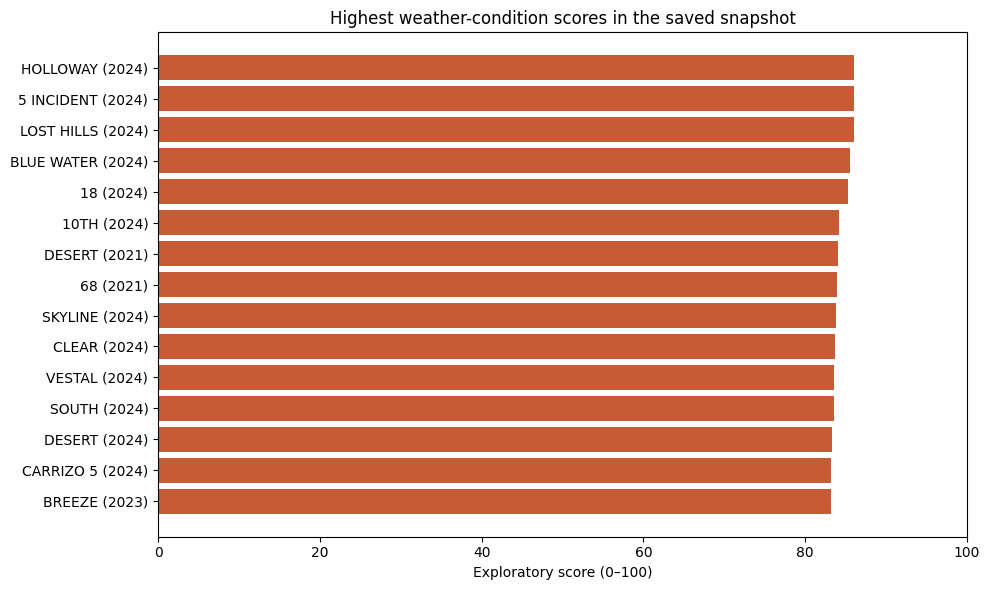

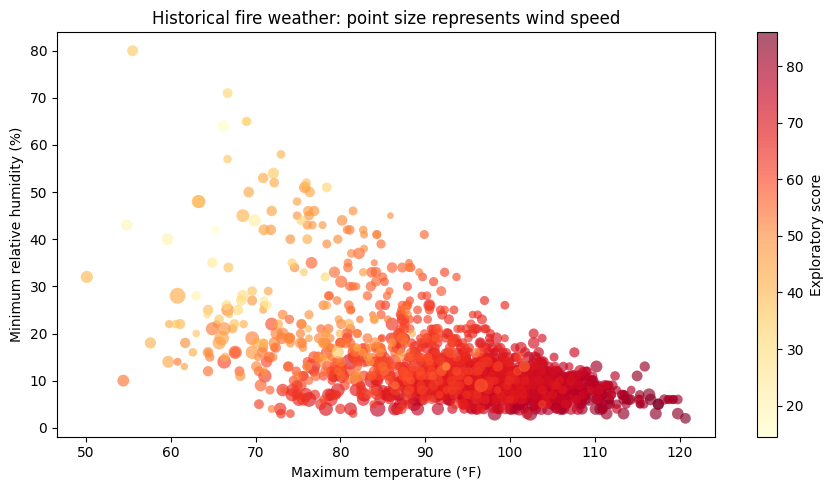

In [5]:
top = ranked.head(15).sort_values("risk_score")
fig, ax = plt.subplots(figsize=(10, 6))
labels = top["fire_name"].astype(str) + " (" + top["year"].astype(str) + ")"
ax.barh(range(len(top)), top["risk_score"], color="#c65b36")
ax.set_yticks(range(len(top)), labels)
ax.set(xlabel="Exploratory score (0–100)", xlim=(0, 100), title="Highest weather-condition scores in the saved snapshot")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
points = ax.scatter(ranked["max_temperature_f"], ranked["min_relative_humidity_pct"],
                    c=ranked["risk_score"], s=ranked["max_wind_speed_mph"].clip(lower=1) * 4,
                    cmap="YlOrRd", alpha=0.65, edgecolors="none")
fig.colorbar(points, ax=ax, label="Exploratory score")
ax.set(xlabel="Maximum temperature (°F)", ylabel="Minimum relative humidity (%)",
       title="Historical fire weather: point size represents wind speed")
fig.tight_layout()
plt.show()


## 5. Interactive weather scenario
The five editable inputs below use the same scoring function as the historical records. Rerunning the cell updates the score and contribution chart. The category boundaries are Low ≤35, Moderate >35–55, High >55–75, and Very High >75. The bars show each factor's **weighted contribution**, which sums to the displayed score before rounding.

Lower humidity increases the dryness contribution, while more rain reduces the precipitation contribution. These are hypothetical weather inputs, not a live forecast for a location.


Scenario score: 73.4/100 (High)


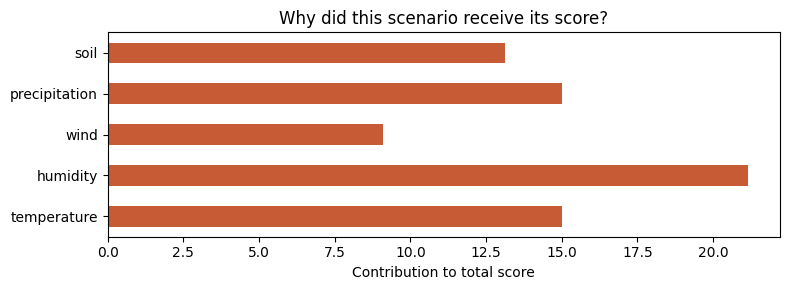

In [6]:
# Edit these inputs, then run this cell.
temperature_f = 95.0
humidity_pct = 15.0
wind_mph = 25.0
precipitation_in = 0.0
soil_moisture = 0.10

assert 0 <= humidity_pct <= 100
assert wind_mph >= 0 and precipitation_in >= 0 and 0 <= soil_moisture <= 1
scenario = pd.DataFrame([{
    "max_temperature_f": temperature_f, "min_relative_humidity_pct": humidity_pct,
    "max_wind_speed_mph": wind_mph, "total_precipitation_in": precipitation_in,
    "mean_soil_moisture": soil_moisture,
}])
result = calculate_risk_scores(scenario).iloc[0]
print(f"Scenario score: {result['risk_score']:.1f}/100 ({result['risk_category']})")
weights = {"temperature": .25, "humidity": .25, "wind": .20, "precipitation": .15, "soil": .15}
contributions = pd.Series({name: result[f"{name}_component"] * weight for name, weight in weights.items()})
contributions.plot.barh(figsize=(8, 3), color="#c65b36")
plt.xlabel("Contribution to total score")
plt.title("Why did this scenario receive its score?")
plt.tight_layout()
plt.show()


## 6. Results export
The cell writes a CSV in the notebook's working directory. In Colab, download it from the Files sidebar. Runtime files are temporary; download anything you want to keep.


In [7]:
export_path = Path("wildfire_risk_colab_results.csv")
ranked.to_csv(export_path, index=False)
print(f"Saved {len(ranked):,} scored records to {export_path}")


Saved 1,557 scored records to wildfire_risk_colab_results.csv


## 7. Interpretation and limitations
- **Historical association:** Hot, dry, windy conditions contribute to the chosen score. A high score does not establish causation or predict an individual fire's size.
- **Selection:** Recorded fire perimeters and complete weather rows are not a representative sample of every California location or day. Repeated names can describe different events.
- **Resolution:** Weather at a perimeter centroid cannot represent every part of a large fire. Terrain, fuels, suppression, and ignition sources are absent.
- **Timing:** The inclusive weather window contains the alarm day. A forecasting extension should use only information available before the prediction time.
- **Experimental models:** The repository also has PyTorch acreage regression and large-fire classification. The README reports weak regression performance and modest classification ranking performance. Those are previous run results, not models retrained by this notebook. A stronger evaluation would reserve later years for testing and compare to simple baselines; selecting the best epoch requires a validation set separate from that final test set.

**Possible extensions:** Comparisons across years, analysis of missingness by year, and sensitivity checks on how the weights affect rankings. A map of recorded fires would show their locations, not ignition probability across unobserved areas.

## Code guide and sources
| File | Responsibility |
|---|---|
| `src/main.py` | Runs the collection, merge, scoring, chart, and map pipeline |
| `src/calfire_api.py` | Retrieves historical fire records |
| `src/weather_api.py` | Retrieves and summarizes the inclusive weather window |
| `src/analysis.py` | Calculates scores and creates charts |
| `src/maps.py` | Creates geographic visualizations |
| `src/predictive_model.py` | Defines experimental neural networks and training |

- [CAL FIRE historical fire perimeters](https://www.fire.ca.gov/what-we-do/fire-resource-assessment-program/fire-perimeters)
- [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api)

This notebook embeds the existing local project snapshot; it does not refresh the source data. For a fresh collection, use the full repository and its README commands. Live API requests may be rate limited.
